In [6]:
import numpy as np
import matplotlib as mpl
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import os
import pickle
from tqdm.auto import tqdm
from scipy.ndimage import gaussian_filter
import seaborn as sns

from utils_load_data import *
from utils_trajectories import *

import matplotlib.patches as mpatches
from scipy.stats import wilcoxon
from sklearn.model_selection import KFold
#import ptitprince as pt
from scipy.stats import sem

from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_predict, cross_val_score
from scipy.stats import pearsonr
from scipy.ndimage import gaussian_filter1d as gaussian_filter
from scipy.stats import gaussian_kde



from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error

from params import save_directory

## plot config 
mpl.rcdefaults()
from fig_parameters import *
apply_final_style()

### PARAMETERS #####

dt = 0.005
t_pre, t_post = 0.2,0.3 #s
dt_trigs = 0
time = np.arange(-t_pre, t_post + dt, dt)





In [7]:
save_directory

'/Volumes/LaCie/dataset_felicie_june/'

## 1. Data import

In [9]:
files_a1 = [ 'NAPOLEON_hs_0','NAPOLEON_hs_1', 'HERCULE_hs_0', 'MMELOIK_hs_1', 'MMELOIK_hs_0', 'FETA_hs_0']

n_data_playback = []
f_data_playback = []
neuron_idx_playback = []
for file in files_a1 :
    with open(save_directory + file + f"_playback_{dt}_data_ss", "rb") as fp:
        n_data_s = pickle.load(fp)
        n_data_playback.append(n_data_s[:12])

    with open(save_directory + file + f"_playback_{dt}_feature_ss", "rb") as fp:
        f_data_s = pickle.load(fp)
        f_data_playback.append(f_data_s[:12])

    with open(save_directory+ file + f"_playback_{dt}_neuron_idx_ss", "rb") as fp:
        idx_data_s = pickle.load(fp)
        neuron_idx_playback.append(idx_data_s[:12])

In [12]:
for n_data_s in n_data_playback :
    n_data_s = smooth_data(n_data_s, sigma =1)

n_data_reorganised, f_data_reorganised, neuron_idx_reorganised = re_organise_data(
    n_data_playback, f_data_playback, neuron_idx_playback
)
n_data_reorganised = [sess / dt for sess in n_data_reorganised] #convertir en spk/s

100%|██████████| 12/12 [00:00<00:00, 38.71it/s]


In [10]:
#version 0.1 pour que ca match
neuron_idx_01 = []
for file in files_a1 :

    with open(save_directory+ file + f"_playback_0.1_neuron_idx_ss", "rb") as fp:
        idx_data_s = pickle.load(fp)
        neuron_idx_01.append(idx_data_s[:12])
_, _, neuron_idx_01 = re_organise_data(
    neuron_idx_01, neuron_idx_01, neuron_idx_01
)

# 1. Masques calculés sur la liste d'ORIGINE (avant tout filtrage)
masks = [np.isin(np.ravel(pb), np.ravel(ref))
         for pb, ref in zip(neuron_idx_reorganised, neuron_idx_01)]

# 2. Appliquer le même masque aux noms ET aux données
neuron_idx_reorganised = [list(np.ravel(pb)[m]) for pb, m in zip(neuron_idx_reorganised, masks)]
n_data_reorganised = [np.asarray(d)[m] for d, m in zip(n_data_reorganised, masks)]

# 3. Vérification
for s, (names, d) in enumerate(zip(neuron_idx_reorganised, n_data_reorganised)):
    assert len(names) == d.shape[0], f"Mismatch session {s}: {len(names)} vs {d.shape[0]}"

# PSTH extraction full population


In [14]:
n_pre_bins  = int(round(t_pre  / dt))
n_post_bins = int(round(t_post / dt))
window_size = n_pre_bins + n_post_bins + 1
assert window_size == len(time)


def _extract_trials(n_data, idx_list, n_pre_bins, n_post_bins, n_baseline_bins, baseline_remove):
    """Découpe et baseline-corrige les fenêtres pour une liste d'indices de trigger."""
    n_bins = n_data.shape[1]
    trials = []
    for idx in idx_list:
        start, end = idx - n_pre_bins, idx + n_post_bins + 1
        if start < 0 or end > n_bins:
            continue  # fenêtre incomplète -> essai exclu
        trial = n_data[:, start:end].astype(float)  # [n_neurons, w]
        if baseline_remove:
            baseline = trial[:, n_pre_bins - n_baseline_bins:n_pre_bins].mean(axis=1, keepdims=True)
            trial = trial - baseline
        trials.append(trial)
    return trials


def build_psth_per_session(n_data_list, f_data_list, n_pre_bins, n_post_bins,
                            n_baseline_bins=None, baseline_remove=True,
                            trial_start=0.0, trial_end=1.0,
                            speed_col=None, speed_max=None, speed_min=None):
    """
    Construit le PSTH moyen (par neurone), baseline retirée, autour des triggers,
    session par session.

    Retourne (track_per_session, pb_per_session, n_trials_per_session) :
      - track_per_session[s] : matrice [window_size, n_neurons_s]  (Condition == 0, Tracking)
      - pb_per_session[s]    : matrice [window_size, n_neurons_s]  (Condition == 1, Playback)
      - n_trials_per_session[s] : dict {'track': n, 'pb': n} - nb d'essais utilisés

    speed_col / speed_max : si renseignés, ne garde que les essais dont la valeur
    de f_data[speed_col] au bin du trigger est < speed_max (essais "basse vitesse").
    Le filtre est appliqué AVANT le découpage en quartiles.
    """
    if n_baseline_bins is None:
        n_baseline_bins = n_pre_bins

    w = n_pre_bins + n_post_bins + 1
    track_per_session, pb_per_session, n_trials_per_session = [], [], []

    for n_data, f_data in zip(n_data_list, f_data_list):
        n_neurons, n_bins = n_data.shape

        trig_idx = np.flatnonzero(f_data['Frequency_changes'].to_numpy())
        cond     = f_data['Condition'].to_numpy()

        track_idx_all = trig_idx[cond[trig_idx] == 0]   # tous les triggers Tracking, ordre chronologique
        pb_idx_all    = trig_idx[cond[trig_idx] == 1]   # tous les triggers Playback, ordre chronologique

        if speed_col is not None and (speed_min is not None or speed_max is not None):
            speed = f_data[speed_col].to_numpy()

            def _speed_mask(idx_arr):
                m = np.ones(len(idx_arr), dtype=bool)
                if speed_min is not None:
                    m &= speed[idx_arr] > speed_min
                if speed_max is not None:
                    m &= speed[idx_arr] < speed_max
                return m

            track_idx_all = track_idx_all[_speed_mask(track_idx_all)]
            pb_idx_all    = pb_idx_all[_speed_mask(pb_idx_all)]

        def _quartile(idx_arr, start_frac, end_frac):
            n = len(idx_arr)
            lo = int(round(start_frac * n))
            hi = int(round(end_frac * n))
            return idx_arr[lo:hi]

        track_idx = _quartile(track_idx_all, trial_start, trial_end)
        pb_idx    = _quartile(pb_idx_all,    trial_start, trial_end)

        track_trials = _extract_trials(n_data, track_idx, n_pre_bins, n_post_bins, n_baseline_bins, baseline_remove)
        pb_trials    = _extract_trials(n_data, pb_idx,    n_pre_bins, n_post_bins, n_baseline_bins, baseline_remove)

        track_psth = (np.nanmean(np.stack(track_trials), axis=0).T
                      if track_trials else np.full((w, n_neurons), np.nan))
        pb_psth    = (np.nanmean(np.stack(pb_trials), axis=0).T
                      if pb_trials else np.full((w, n_neurons), np.nan))

        track_per_session.append(track_psth)
        pb_per_session.append(pb_psth)
        n_trials_per_session.append({'track': len(track_trials), 'pb': len(pb_trials)})

    return track_per_session, pb_per_session, n_trials_per_session


def concat_neurons(mat_list):
    """Concatène une liste de matrices [window_size, n_neurons_s] -> [window_size, total_neurons]."""
    return np.concatenate(mat_list, axis=1)

## 3. Population PSTH — Tracking vs Playback (session entière, baseline retirée)

In [15]:
track_per_session, pb_per_session, n_trials_per_session = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins,n_baseline_bins =int(0.05/dt)
)

all_traj_tracking = concat_neurons(track_per_session)   # [window_size, total_neurons]
all_traj_playback = concat_neurons(pb_per_session)

mean_traj_track = np.nanmean(all_traj_tracking, axis=1)
sem_traj_track  = np.nanstd(all_traj_tracking, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_tracking), axis=1))

mean_traj_pb = np.nanmean(all_traj_playback, axis=1)
sem_traj_pb  = np.nanstd(all_traj_playback, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_playback), axis=1))


Neurones tirés : [np.int64(416), np.int64(277)]


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/2300761372.py:60: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.3, h_pad=0.8)


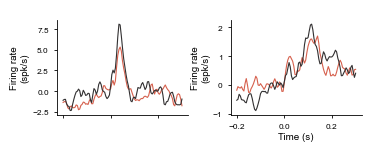

In [16]:
def sig_label(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    neuron_ids=None,
    n_neurons=2,
    neuron_labels=None,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.05,
):

    n_total = all_traj_tracking.shape[1]

    if neuron_ids is None:
        neuron_ids = np.random.choice(n_total, size=n_neurons, replace=False)
        print(f"Neurones tirés : {list(neuron_ids)}")

    if neuron_labels is None:
        neuron_labels = [f' ' for i in range(len(neuron_ids))]

    auc_idx = np.where((time >= auc_t_start) & (time <= auc_t_end))[0]

    fig, axes = plt.subplots(
        1,len(neuron_ids),
        figsize=(89/25.4, 35/25.4),
        sharey=False,   # chaque neurone a sa propre échelle
    )
    if len(neuron_ids) == 1:
        axes = [axes]

    for i, (ax, nid, nlabel) in enumerate(zip(axes, neuron_ids, neuron_labels)):
        tr = all_traj_tracking[:, nid]
        pb = all_traj_playback[:, nid]

        for trace, color, label in [
            (tr, C_TRACK, 'Tracking'),
            (pb, C_PB,    'Playback'),
        ]:
            v = np.isfinite(trace)
            ax.plot(time[v], trace[v], color=color, lw=0.8, label=label)

        ax.set_title(nlabel, pad=2)
        ax.set_ylabel('Firing rate\n(spk/s)', labelpad=2)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        if i == len(neuron_ids) - 1:
            ax.set_xlabel('Time (s)', labelpad=2)
        else:
            ax.set_xticklabels([])

    plt.tight_layout(pad=0.3, h_pad=0.8)
    plt.show()

plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.1,
)

Neurones tirés : [np.int64(1217), np.int64(1214)]


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/1758459856.py:81: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.3, h_pad=1.2)


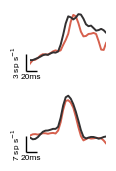

In [17]:
def add_scale_bar(ax, x0, y0, dx, dy, x_range, y_range, label_x, label_y, lw=1.0, fontsize=6):
    """Barre d'échelle en L (Nature-style) : trait horizontal (temps) + vertical (Hz)."""
    ax.plot([x0, x0 + dx], [y0, y0], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.plot([x0, x0], [y0, y0 + dy], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.text(x0 + dx / 2, y0 - y_range * 0.05, label_x, ha='center', va='top', fontsize=fontsize)
    ax.text(x0 - x_range * 0.04, y0 + dy / 2, label_y, ha='right', va='center', fontsize=fontsize, rotation=90)


def sig_label(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'



def plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    neuron_ids=None,
    n_neurons=2,
    neuron_labels=None,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.05,
    xlim=(-0.05, 0.1),
    scale_dx=0.02,  # 20 ms
):

    n_total = all_traj_tracking.shape[1]

    if neuron_ids is None:
        neuron_ids = np.random.choice(n_total, size=n_neurons, replace=False)
        print(f"Neurones tirés : {list(neuron_ids)}")

    if neuron_labels is None:
        neuron_labels = [f'n{nid}' for nid in neuron_ids]

    auc_idx = np.where((time >= auc_t_start) & (time <= auc_t_end))[0]

    fig, axes = plt.subplots(
        len(neuron_ids), 1,
        figsize=(26 * MM, 40 * MM),
        sharex=True,
    )
    if len(neuron_ids) == 1:
        axes = [axes]

    x_range = xlim[1] - xlim[0]  # 0.15, calculé depuis xlim -> jamais désynchronisé

    for i, (ax, nid, nlabel) in enumerate(zip(axes, neuron_ids, neuron_labels)):
        tr = all_traj_tracking[:, nid]
        pb = all_traj_playback[:, nid]

        y_min, y_max = np.inf, -np.inf
        for trace, color in [(tr, C_TRACK), (pb, C_PB)]:
            v = np.isfinite(trace)
            ax.plot(time[v], trace[v], color=color, lw=1.4, zorder=2)
            y_min = min(y_min, np.nanmin(trace[v]))
            y_max = max(y_max, np.nanmax(trace[v]))

        y_range = y_max - y_min
        ax.set_xlim(xlim)
        ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.08)

        # ── barre Hz : ~30% de l'étendue ──
        raw_dy = y_range * 0.3
        magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
        scale_dy = np.round(raw_dy / magnitude) * magnitude

        x0 = xlim[0] - x_range * 0.05
        y0 = y_min - y_range * 0.02
        add_scale_bar(ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
                      label_x=f'{int(scale_dx*1000)}ms', label_y=f'{scale_dy:g} sp s$^{{-1}}$',
                      fontsize=6)

        ax.axis('off')

    plt.tight_layout(pad=0.3, h_pad=1.2)
    #plt.savefig(save_directory + '1F.pdf', transparent=True, dpi=600)
    #plt.savefig(save_directory + '1F.png', bbox_inches='tight', dpi=600)
    plt.show()

plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.1,
)

MI: 61/1257 outliers retirés pour l'affichage (stats calculées sur n=1257)


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3216289712.py:95: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3216289712.py:95: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


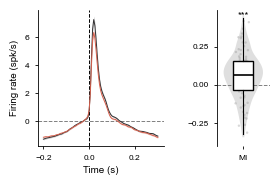

Wilcoxon signed-rank (peak) : W=212533, p=0.0000  ***  (n=1257 neurones appariés)
Wilcoxon signed-rank (modulation index vs 0) : W=245295, p=0.0000  ***  médiane MI=0.065


In [18]:

# ── Pic par neurone (post-onset, baseline déjà retirée) + Wilcoxon ────────────
mean_track, sem_track = mean_traj_track, sem_traj_track
mean_pb,    sem_pb    = mean_traj_pb,    sem_traj_pb

post = time >= 0
peak_track_n = np.nanmax(all_traj_tracking[post, :], axis=0)
peak_pb_n    = np.nanmax(all_traj_playback[post, :], axis=0)

valid        = np.isfinite(peak_track_n) & np.isfinite(peak_pb_n)
pt, pp       = peak_track_n[valid], peak_pb_n[valid]
stat, p_wilc = wilcoxon(pt, pp, alternative='two-sided')

mod_index = (pp - pt) / (pt + pp)
stat_mi, p_mi = wilcoxon(mod_index, alternative='two-sided')

# Outliers (1.5*IQR) retirés uniquement pour l'affichage -> les stats
# ci-dessus restent calculées sur mod_index complet
def remove_outliers_iqr(x, k=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return x[(x >= lo) & (x <= hi)]

mod_index_display = remove_outliers_iqr(mod_index)
n_removed = len(mod_index) - len(mod_index_display)
print(f"MI: {n_removed}/{len(mod_index)} outliers retirés pour l'affichage (stats calculées sur n={len(mod_index)})")

# ── Layout : marges dynamiques (pas de valeurs fixes en pouces), gérées par
# tight_layout plutôt que des coordonnées codées en dur ──
fig = plt.figure(figsize=(76*MM, 45*MM))
gs  = gridspec.GridSpec(1, 2, width_ratios=[2.4, 1], wspace=0.6)

ax      = fig.add_subplot(gs[0])
ax_ins  = fig.add_subplot(gs[1])

for mean, sem_v, color, label in [
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
    (mean_track, sem_track, C_TRACK, 'Tracking'),
]:
    valid_t = np.isfinite(mean) & np.isfinite(sem_v)
    ax.fill_between(time[valid_t],
                    mean[valid_t] - sem_v[valid_t],
                    mean[valid_t] + sem_v[valid_t],
                    color=color, alpha=0.25, linewidth=0)
    ax.plot(time[valid_t], mean[valid_t], color=color, label=label)

ax.axvline(0, color='k', linestyle='--', zorder=0)
ax.axhline(0, color='gray', linestyle='--', zorder=0)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Firing rate (spk/s)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Inset : distribution du modulation index, test contre 0 (violin + boxplot) ---
ax_ins.axhline(0, color='gray', linestyle='--', zorder=0)

parts = ax_ins.violinplot(mod_index_display, positions=[0], widths=0.6,
                           showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor('gray')
    pc.set_edgecolor('none')
    pc.set_alpha(0.25)
    pc.set_zorder(1)

rng   = np.random.default_rng(0)
idx_s = rng.choice(len(mod_index_display), size=min(80, len(mod_index_display)), replace=False)
ax_ins.scatter(rng.normal(0, 0.05, len(idx_s)), mod_index_display[idx_s],
               s=3, color='gray', alpha=0.3, edgecolors='none', zorder=2)

ax_ins.boxplot(mod_index_display, positions=[0], widths=0.3,
               patch_artist=True, showfliers=False,
               medianprops=dict(color='k', lw=1.2),
               boxprops=dict(facecolor='white', edgecolor='k', lw=1),
               whiskerprops=dict(color='k', lw=0.8),
               capprops=dict(lw=0), zorder=3)

ax_ins.set_xticks([0])
ax_ins.set_xticklabels(['MI'])
ax_ins.set_xlim(-0.4, 0.4)
ax_ins.yaxis.set_major_locator(ticker.MaxNLocator(4))
ax_ins.spines['top'].set_visible(False)
ax_ins.spines['right'].set_visible(False)
ax_ins.spines['bottom'].set_visible(False)

# ── ylim calculé sur les données affichées (post-exclusion) ──
y_low  = np.nanpercentile(mod_index_display, 2)
y_high = np.nanpercentile(mod_index_display, 98)
margin = (y_high - y_low) * 0.2
ax_ins.set_ylim(y_low - margin, y_high + margin)

# ── Texte de significativité PLACÉ DANS les limites de l'axe (pas au-delà) ──
y_top = y_high + margin * 0.5
ax_ins.text(0, y_top, f'{sig_label(p_mi)}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(save_directory + 'psth_with_MI_peak.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print(f"Wilcoxon signed-rank (peak) : W={stat:.0f}, p={p_wilc:.4f}  "
      f"{sig_label(p_wilc)}  (n={valid.sum()} neurones appariés)")
print(f"Wilcoxon signed-rank (modulation index vs 0) : W={stat_mi:.0f}, p={p_mi:.4f}  "
      f"{sig_label(p_mi)}  médiane MI={np.median(mod_index):.3f}")

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/409592788.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/409592788.py:114: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


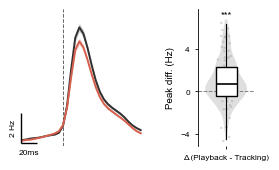

Wilcoxon signed-rank (peak, tracking vs playback) : W=212533, p=0.0000  ***  (n=1257 neurones appariés)
Médiane diff (tracking - playback) : 0.72 Hz
Diff: 54/1257 outliers retirés pour l'affichage (stats calculées sur n=1257)


In [19]:
def add_scale_bar(ax, x0, y0, dx, dy, x_range, y_range, label_x, label_y, lw=1.0, fontsize=6):
    ax.plot([x0, x0 + dx], [y0, y0], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.plot([x0, x0], [y0, y0 + dy], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.text(x0 + dx / 2, y0 - y_range * 0.05, label_x, ha='center', va='top', fontsize=fontsize)
    ax.text(x0 - x_range * 0.04, y0 + dy / 2, label_y, ha='right', va='center', fontsize=fontsize, rotation=90)


# ── Pic par neurone (post-onset, baseline déjà retirée) + Wilcoxon apparié ──
mean_track, sem_track = mean_traj_track, sem_traj_track
mean_pb,    sem_pb    = mean_traj_pb,    sem_traj_pb

post = time >= 0
peak_track_n = np.nanmax(all_traj_tracking[post, :], axis=0)
peak_pb_n    = np.nanmax(all_traj_playback[post, :], axis=0)

valid  = np.isfinite(peak_track_n) & np.isfinite(peak_pb_n)
pt, pp = peak_track_n[valid], peak_pb_n[valid]
stat, p_wilc = wilcoxon(pt, pp, alternative='two-sided')

diff = pp - pt  

def remove_outliers_iqr(x, k=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return x[(x >= lo) & (x <= hi)]

diff_display = remove_outliers_iqr(diff)  # affichage seulement, stats sur diff complet
n_removed = len(diff) - len(diff_display)
median_diff = np.median(diff)

# ── Layout ──
fig = plt.figure(figsize=(76 * MM, 45 * MM))
gs  = gridspec.GridSpec(1, 2, width_ratios=[2.2, 1], wspace=0.6)

ax     = fig.add_subplot(gs[0])
ax_ins = fig.add_subplot(gs[1])

# ── panel gauche : PSTH moyen, style barre d'échelle, xlim fixé ──
xlim = (-0.05, 0.1)

y_min, y_max = np.inf, -np.inf
for mean, sem_v, color, label in [
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
    (mean_track, sem_track, C_TRACK, 'Tracking'),
]:
    valid_t = np.isfinite(mean) & np.isfinite(sem_v) & (time >= xlim[0]) & (time <= xlim[1])
    ax.fill_between(time[valid_t], mean[valid_t] - sem_v[valid_t], mean[valid_t] + sem_v[valid_t],
                    color=color, alpha=0.25, linewidth=0)
    ax.plot(time[valid_t], mean[valid_t], color=color, lw=1.4, label=label, zorder=2)
    y_min = min(y_min, np.nanmin(mean[valid_t] - sem_v[valid_t]))
    y_max = max(y_max, np.nanmax(mean[valid_t] + sem_v[valid_t]))

ax.axvline(0, color='k', linestyle='--', lw=0.7, zorder=1, alpha=0.6)

x_range = xlim[1] - xlim[0]
y_range = y_max - y_min
ax.set_xlim(xlim)
ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.12)

raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
scale_dy = np.round(raw_dy / magnitude) * magnitude
scale_dx = 0.02  # 20ms, cohérent avec le ratio ~13% validé sur tes autres figures

x0 = xlim[0] - x_range * 0.01
y0 = y_min - y_range * 0.02
add_scale_bar(ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
              label_x=f'{int(scale_dx*1000)}ms', label_y=f'{scale_dy:g} Hz', fontsize=6)

#ax.legend(frameon=False, fontsize=6, loc='upper left', handlelength=1.2)
ax.axis('off')

# ── inset : violin + boxplot de la différence appariée, testée contre 0 ──
ax_ins.axhline(0, color='gray', linestyle='--', zorder=0)

parts = ax_ins.violinplot(diff_display, positions=[0], widths=0.6,
                           showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor('gray')
    pc.set_edgecolor('none')
    pc.set_alpha(0.25)
    pc.set_zorder(1)

rng   = np.random.default_rng(0)
idx_s = rng.choice(len(diff_display), size=min(80, len(diff_display)), replace=False)
ax_ins.scatter(rng.normal(0, 0.05, len(idx_s)), diff_display[idx_s],
               s=3, color='gray', alpha=0.3, edgecolors='none', zorder=2)

ax_ins.boxplot(diff_display, positions=[0], widths=0.3,
               patch_artist=True, showfliers=False,
               medianprops=dict(color='k', lw=1.2),
               boxprops=dict(facecolor='white', edgecolor='k', lw=1),
               whiskerprops=dict(color='k', lw=0.8),
               capprops=dict(lw=0), zorder=3)

ax_ins.set_xticks([0])
ax_ins.set_xticklabels(['Δ (Playback - Tracking)'])
ax_ins.set_xlim(-0.4, 0.4)
ax_ins.yaxis.set_major_locator(ticker.MaxNLocator(4))
ax_ins.set_ylabel('Peak diff. (Hz)', fontsize=7)
ax_ins.spines['top'].set_visible(False)
ax_ins.spines['right'].set_visible(False)
ax_ins.spines['bottom'].set_visible(False)

y_low  = np.nanpercentile(diff_display, 2)
y_high = np.nanpercentile(diff_display, 98)
margin = (y_high - y_low) * 0.2
ax_ins.set_ylim(y_low - margin, y_high + margin)

y_top = y_high + margin * 0.5
ax_ins.text(0, y_top, f'{sig_label(p_wilc)}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(save_directory + 'psth_with_diff_violin.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + 'psth_with_diff_violin.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

print(f"Wilcoxon signed-rank (peak, tracking vs playback) : W={stat:.0f}, p={p_wilc:.4f}  "
      f"{sig_label(p_wilc)}  (n={valid.sum()} neurones appariés)")
print(f"Médiane diff (tracking - playback) : {median_diff:.2f} Hz")
print(f"Diff: {n_removed}/{len(diff)} outliers retirés pour l'affichage (stats calculées sur n={len(diff)})")

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/1734762163.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/1734762163.py:116: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


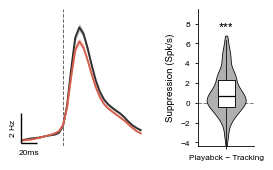

Wilcoxon signed-rank (peak, tracking vs playback) : W=212533, p=0.0000  ***  (n=1257 neurones appariés)
Médiane diff (tracking - playback) : 0.72 Hz
Diff: 54/1257 outliers retirés pour l'affichage (stats calculées sur n=1257)


In [20]:
def add_scale_bar(ax, x0, y0, dx, dy, x_range, y_range, label_x, label_y, lw=1.0, fontsize=6):
    ax.plot([x0, x0 + dx], [y0, y0], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.plot([x0, x0], [y0, y0 + dy], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.text(x0 + dx / 2, y0 - y_range * 0.05, label_x, ha='center', va='top', fontsize=fontsize)
    ax.text(x0 - x_range * 0.04, y0 + dy / 2, label_y, ha='right', va='center', fontsize=fontsize, rotation=90)


# ── Pic par neurone (post-onset, baseline déjà retirée) + Wilcoxon apparié ──
mean_track, sem_track = mean_traj_track, sem_traj_track
mean_pb,    sem_pb    = mean_traj_pb,    sem_traj_pb

post = time >= 0
peak_track_n = np.nanmax(all_traj_tracking[post, :], axis=0)
peak_pb_n    = np.nanmax(all_traj_playback[post, :], axis=0)

valid  = np.isfinite(peak_track_n) & np.isfinite(peak_pb_n)
pt, pp = peak_track_n[valid], peak_pb_n[valid]
stat, p_wilc = wilcoxon(pt, pp, alternative='two-sided')

diff = pp - pt

def remove_outliers_iqr(x, k=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return x[(x >= lo) & (x <= hi)]

diff_display = remove_outliers_iqr(diff)
n_removed = len(diff) - len(diff_display)
median_diff = np.median(diff)

GRAY_LIGHT = '#B0B0B0'
lw = plt.rcParams['lines.linewidth']

# ── Layout ──
fig = plt.figure(figsize=(76 * MM, 45 * MM))
gs  = gridspec.GridSpec(1, 2, width_ratios=[2.2, 1], wspace=0.6)

ax     = fig.add_subplot(gs[0])
ax_ins = fig.add_subplot(gs[1])

# ── panel gauche : PSTH moyen, style barre d'échelle, xlim fixé ──
xlim = (-0.05, 0.1)

y_min, y_max = np.inf, -np.inf
for mean, sem_v, color, label in [
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
    (mean_track, sem_track, C_TRACK, 'Tracking'),
]:
    valid_t = np.isfinite(mean) & np.isfinite(sem_v) & (time >= xlim[0]) & (time <= xlim[1])
    ax.fill_between(time[valid_t], mean[valid_t] - sem_v[valid_t], mean[valid_t] + sem_v[valid_t],
                    color=color, alpha=0.25, linewidth=0)
    ax.plot(time[valid_t], mean[valid_t], color=color, lw=1.4, label=label, zorder=2)
    y_min = min(y_min, np.nanmin(mean[valid_t] - sem_v[valid_t]))
    y_max = max(y_max, np.nanmax(mean[valid_t] + sem_v[valid_t]))

ax.axvline(0, color='k', linestyle='--', lw=0.7, zorder=1, alpha=0.6)

x_range = xlim[1] - xlim[0]
y_range = y_max - y_min
ax.set_xlim(xlim)
ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.12)

raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
scale_dy = np.round(raw_dy / magnitude) * magnitude
scale_dx = 0.02

x0 = xlim[0] - x_range * 0.01
y0 = y_min - y_range * 0.02
add_scale_bar(ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
              label_x=f'{int(scale_dx*1000)}ms', label_y=f'{scale_dy:g} Hz', fontsize=6)

ax.axis('off')

# ── inset : violin plein (gris clair, style harmonisé) + double boxplot ──
ax_ins.axhline(0, color='gray', linestyle='--', zorder=0)

parts = ax_ins.violinplot(diff_display, positions=[0], widths=0.7,
                           showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor(GRAY_LIGHT)
    pc.set_edgecolor('black')
    pc.set_linewidth(lw * 0.8)
    pc.set_alpha(1.0)
    pc.set_zorder(1)

# couche 1 : whiskers seuls
ax_ins.boxplot(diff_display, positions=[0], widths=0.001,
               patch_artist=False, showcaps=False, showfliers=False,
               medianprops=dict(color='none'),
               boxprops=dict(color='none'),
               whiskerprops=dict(color='black', linewidth=lw * 0.8),
               zorder=2)

# couche 2 : box blanche + médiane
ax_ins.boxplot(diff_display, positions=[0], widths=0.3,
               patch_artist=True, showcaps=False, showfliers=False,
               medianprops=dict(color='black', linewidth=lw * 1.3),
               boxprops=dict(facecolor='white', edgecolor='black', linewidth=lw * 0.9),
               whiskerprops=dict(color='none'),
               zorder=3)

ax_ins.set_xticks([0])
ax_ins.set_xticklabels(['Playabck − Tracking'])
ax_ins.set_ylabel('Suppression (Spk/s)', fontsize=7)
ax_ins.spines[['top', 'right']].set_visible(False)

y_low, y_high = np.nanpercentile(diff_display, [5, 95])
margin = abs(y_high - y_low) * 0.15
ax_ins.set_ylim(y_low - margin * 2, y_high + margin * 4)

y_top = y_high + margin
ax_ins.text(0, y_top + margin * 0.7, sig_label(p_wilc), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(save_directory + 'psth_with_diff_violin.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + 'psth_with_diff_violin.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

print(f"Wilcoxon signed-rank (peak, tracking vs playback) : W={stat:.0f}, p={p_wilc:.4f}  "
      f"{sig_label(p_wilc)}  (n={valid.sum()} neurones appariés)")
print(f"Médiane diff (tracking - playback) : {median_diff:.2f} Hz")
print(f"Diff: {n_removed}/{len(diff)} outliers retirés pour l'affichage (stats calculées sur n={len(diff)})")

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/1732175469.py:85: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


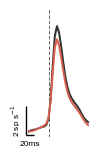

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/1732175469.py:206: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


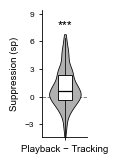

Wilcoxon signed-rank (peak, tracking vs playback) : W=212533, p=0.0000 *** (n=1257 neurones appariés)
Médiane diff (tracking - playback) : 0.72 Hz
Diff: 54/1257 outliers retirés pour l'affichage (stats calculées sur n=1257)


In [21]:
# ─────────────────────────────────────────────
# PLOT 1 — PSTH
# ─────────────────────────────────────────────

fig = plt.figure(figsize=(26 * MM, 40 * MM))
ax = fig.add_subplot(111)

xlim = (-0.05, 0.1)

y_min, y_max = np.inf, -np.inf

for mean, sem_v, color, label in [
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
    (mean_track, sem_track, C_TRACK, 'Tracking'),
]:
    valid_t = (
        np.isfinite(mean)
        & np.isfinite(sem_v)
        & (time >= xlim[0])
        & (time <= xlim[1])
    )

    ax.fill_between(
        time[valid_t],
        mean[valid_t] - sem_v[valid_t],
        mean[valid_t] + sem_v[valid_t],
        color=color,
        alpha=0.25,
        linewidth=0
    )

    ax.plot(
        time[valid_t],
        mean[valid_t],
        color=color,
        lw=1.4,
        label=label,
        zorder=2
    )

    y_min = min(y_min, np.nanmin(mean[valid_t] - sem_v[valid_t]))
    y_max = max(y_max, np.nanmax(mean[valid_t] + sem_v[valid_t]))

ax.axvline(
    0,
    color='k',
    linestyle='--',
    lw=0.7,
    zorder=1,
    alpha=0.6
)

x_range = xlim[1] - xlim[0]
y_range = y_max - y_min

ax.set_xlim(xlim)
ax.set_ylim(
    y_min - y_range * 0.04,
    y_max + y_range * 0.12
)

raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
scale_dy = np.round(raw_dy / magnitude) * magnitude
scale_dx = 0.02

x0 = xlim[0] - x_range * 0.03
y0 = y_min - y_range * 0.02

add_scale_bar(
    ax,
    x0,
    y0,
    scale_dx,
    scale_dy,
    x_range,
    y_range,
    label_x=f'{int(scale_dx * 1000)}ms',
    label_y=f'{scale_dy:g} sp s$^{{-1}}$',
    fontsize=6
)

ax.axis('off')

plt.tight_layout()

plt.savefig(
    save_directory + '1G.pdf',
    dpi=600,
    bbox_inches='tight',
    transparent=True
)
plt.savefig(
    save_directory + '1G.png',
    dpi=600,
    bbox_inches='tight',
    transparent=True
)

plt.show()


# ─────────────────────────────────────────────
# PLOT 2 — VIOLIN
# ─────────────────────────────────────────────

fig = plt.figure(figsize=(26 * MM, 42 * MM))
apply_final_style()
ax = fig.add_subplot(111)

ax.axhline(
    0,
    color='gray',
    linestyle='--',
    zorder=0
)

parts = ax.violinplot(
    diff_display,
    positions=[0],
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for pc in parts['bodies']:
    pc.set_facecolor(GRAY_LIGHT)
    pc.set_edgecolor('black')
    pc.set_linewidth(lw * 0.8)
    pc.set_alpha(1.0)
    pc.set_zorder(1)

# Whiskers
ax.boxplot(
    diff_display,
    positions=[0],
    widths=0.001,
    patch_artist=False,
    showcaps=False,
    showfliers=False,
    medianprops=dict(color='none'),
    boxprops=dict(color='none'),
    whiskerprops=dict(
        color='black',
        linewidth=lw * 0.8
    ),
    zorder=2
)

# White box + median
ax.boxplot(
    diff_display,
    positions=[0],
    widths=0.3,
    patch_artist=True,
    showcaps=False,
    showfliers=False,
    medianprops=dict(
        color='black',
        linewidth=lw * 1.3
    ),
    boxprops=dict(
        facecolor='white',
        edgecolor='black',
        linewidth=lw * 0.9
    ),
    whiskerprops=dict(color='none'),
    zorder=3
)

ax.set_xticks([0])
ax.set_xticklabels(['Playback − Tracking'], fontsize = 7)

ax.set_ylabel(
    r'Suppression (sp)',
    fontsize=7
)
ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5))

ax.spines[['top', 'right']].set_visible(False)

y_low, y_high = np.nanpercentile(
    diff_display,
    [5, 95]
)

margin = abs(y_high - y_low) * 0.15

ax.set_ylim(
    y_low - margin * 2,
    y_high + margin * 4
)

y_top = y_high + margin

ax.text(
    0,
    y_top + margin * 0.7,
    sig_label(p_wilc),
    ha='center',
    va='bottom',
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    save_directory + '1Gp.pdf',
    dpi=600,
    transparent=True
)
plt.savefig(
    save_directory + '1Gp.png',
    dpi=600,
    transparent=True
)

plt.show()


# ─────────────────────────────────────────────
# STATS
# ─────────────────────────────────────────────

print(
    f"Wilcoxon signed-rank (peak, tracking vs playback) : "
    f"W={stat:.0f}, p={p_wilc:.4f} "
    f"{sig_label(p_wilc)} "
    f"(n={valid.sum()} neurones appariés)"
)

print(
    f"Médiane diff (tracking - playback) : "
    f"{median_diff:.2f} Hz"
)

print(
    f"Diff: {n_removed}/{len(diff)} outliers retirés pour l'affichage "
    f"(stats calculées sur n={len(diff)})"
)

In [22]:
print("\n" + "="*70)
print("PEAK RESPONSE ANALYSIS")
print("="*70)

post = time >= 0
peak_curve_track = np.nanmax(mean_traj_track[post])
peak_curve_pb    = np.nanmax(mean_traj_pb[post])

print(f"\n1) Peak of population average (visible on curve):")
print(f"   Tracking: {peak_curve_track:.3f} spk/s")
print(f"   Playback: {peak_curve_pb:.3f} spk/s")

print(f"\n2) Average of individual neuron peaks (statistical test):")
print(f"   Tracking: {pt.mean():.3f} ± {pt.std()/np.sqrt(len(pt)):.3f} spk/s (n={len(pt)})")
print(f"   Playback: {pp.mean():.3f} ± {pp.std()/np.sqrt(len(pp)):.3f} spk/s (n={len(pp)})")
print(f"   Difference: {pt.mean() - pp.mean():.3f} spk/s ({100*(pt.mean()-pp.mean())/pp.mean():+.1f}%)")

print(f"\n3) Statistical comparison (paired neurons):")
print(f"   Wilcoxon signed-rank: W={stat:.0f}, p={p_wilc:.4f} {sig_label(p_wilc)}")
print(f"   N = {valid.sum()} paired neurons")

print(f"\n4) Why they differ:")
print(f"   Individual peaks are higher ({pt.mean():.3f}) than population peak ({peak_curve_track:.3f})")
print(f"   because neurons peak at different times (temporal jitter).")


PEAK RESPONSE ANALYSIS

1) Peak of population average (visible on curve):
   Tracking: 6.314 spk/s
   Playback: 7.240 spk/s

2) Average of individual neuron peaks (statistical test):
   Tracking: 8.357 ± 0.223 spk/s (n=1257)
   Playback: 9.474 ± 0.255 spk/s (n=1257)
   Difference: -1.117 spk/s (-11.8%)

3) Statistical comparison (paired neurons):
   Wilcoxon signed-rank: W=212533, p=0.0000 ***
   N = 1257 paired neurons

4) Why they differ:
   Individual peaks are higher (8.357) than population peak (6.314)
   because neurons peak at different times (temporal jitter).


# latency ? 


LMM (random intercept for session, 72 sessions, 1 animal): β = 0.79 ms, 95% CI [0.13, 1.46], p = 0.0189, converged=True


/Users/felicie/phd_final/env/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/felicie/phd_final/env/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


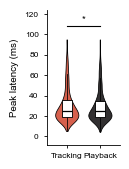

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import wilcoxon

# ── paramètres ──
LAT_WIN  = (0.0, 0.1)    # fenêtre de recherche du pic (s)
BASE_WIN = (-0.05, 0.0)  # baseline (s)
Z_THRESH = 3             # pic > baseline + 3 SD pour être considéré comme une réponse


def peak_latency(mat, time, lat_win=LAT_WIN, base_win=BASE_WIN, z_thresh=Z_THRESH):
    """mat : [n_time, n_units]. Latence du pic (s) par unité ; NaN si pas de réponse claire."""
    w = (time >= lat_win[0]) & (time <= lat_win[1])
    b = (time >= base_win[0]) & (time < base_win[1])
    t_w, seg = time[w], mat[w, :]
    base_mu = np.nanmean(mat[b, :], axis=0)
    base_sd = np.nanstd(mat[b, :], axis=0)
    step = t_w[1] - t_w[0]

    lat = np.full(mat.shape[1], np.nan)
    for u in range(mat.shape[1]):
        y = seg[:, u]
        if not np.any(np.isfinite(y)) or not base_sd[u] > 0:
            continue
        i = np.nanargmax(y)
        if (y[i] - base_mu[u]) / base_sd[u] < z_thresh:
            continue
        # interpolation parabolique pour une précision sous le bin
        delta = 0.0
        if 0 < i < len(y) - 1 and np.all(np.isfinite(y[i - 1:i + 2])):
            denom = y[i - 1] - 2 * y[i] + y[i + 1]
            if denom != 0:
                delta = 0.5 * (y[i - 1] - y[i + 1]) / denom
        lat[u] = t_w[i] + delta * step
    return lat


def as_time_by_units(mat, time):
    """Renvoie la matrice au format [n_time, n_units], quelle que soit son orientation d'origine."""
    mat = np.asarray(mat, dtype=float)
    if mat.shape[0] == len(time) and mat.shape[1] != len(time):
        return mat
    if mat.shape[1] == len(time) and mat.shape[0] != len(time):
        return mat.T
    raise ValueError(f"Orientation ambiguë : shape {mat.shape}, len(time) = {len(time)}")

traj_track = as_time_by_units(all_traj_tracking, time)
traj_pb    = as_time_by_units(all_traj_playback, time)

lat_track = peak_latency(traj_track, time) * 1000
lat_pb    = peak_latency(traj_pb,    time) * 1000
lat_track_v, lat_pb_v = lat_track[valid], lat_pb[valid]
diff_lat = lat_track_v - lat_pb_v

# ── session de chaque unité (même ordre que la concaténation) ──
unit_session = np.concatenate([np.full(n.shape[0], s) for s, n in enumerate(n_data_reorganised)])
assert len(unit_session) == all_traj_tracking.shape[1], (len(unit_session), all_traj_tracking.shape[1])

df_lat = pd.DataFrame({'diff': diff_lat, 'session': unit_session[valid]})
n_sessions = df_lat['session'].nunique()

if n_sessions > 1:
    scale = df_lat['diff'].std()
    res = smf.mixedlm("y ~ 1", df_lat.assign(y=df_lat['diff'] / scale),
                      groups=df_lat['session']).fit(reml=True, method='lbfgs')
    p_lat = res.pvalues['Intercept']
    beta = res.params['Intercept'] * scale
    ci = res.conf_int().loc['Intercept'] * scale
    stat_txt = (f"LMM (random intercept for session, {n_sessions} sessions, 1 animal): "
                f"β = {beta:.2f} ms, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}], "
                f"p = {p_lat:.3g}, converged={res.converged}")
else:
    stat, p_lat = wilcoxon(diff_lat)
    stat_txt = f"Wilcoxon signed-rank (single session): W = {stat:.0f}, p = {p_lat:.3g}"

# ── violin plot ──
fig = plt.figure(figsize=(30 * MM, 40 * MM))
ax = fig.add_subplot(111)

for x, data, color in [(0, lat_track_v, C_TRACK), (1, lat_pb_v, C_PB)]:
    parts = ax.violinplot(data, positions=[x], widths=0.7,
                          showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_edgecolor('black')
        pc.set_linewidth(lw * 0.8)
        pc.set_alpha(1.0)
        pc.set_zorder(1)

    ax.boxplot(data, positions=[x], widths=0.001, patch_artist=False,
               showcaps=False, showfliers=False,
               medianprops=dict(color='none'), boxprops=dict(color='none'),
               whiskerprops=dict(color='black', linewidth=lw * 0.8), zorder=2)
    ax.boxplot(data, positions=[x], widths=0.3, patch_artist=True,
               showcaps=False, showfliers=False,
               medianprops=dict(color='black', linewidth=lw * 1.3),
               boxprops=dict(facecolor='white', edgecolor='black', linewidth=lw * 0.9),
               whiskerprops=dict(color='none'), zorder=3)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Tracking', 'Playback'])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel('Peak latency (ms)', fontsize=7)
ax.spines[['top', 'right']].set_visible(False)

y_lo, y_hi = LAT_WIN[0] * 1000, LAT_WIN[1] * 1000
margin = (y_hi - y_lo) * 0.08
ax.set_ylim(y_lo - margin, y_hi + margin * 3)
y_bar = y_hi + margin
ax.plot([0, 1], [y_bar, y_bar], color='black', linewidth=0.8)
ax.text(0.5, y_bar + margin * 0.3, sig_label(p_lat), ha='center', va='bottom', fontsize=7)



print(stat_txt)

*(Panneau optionnel : moyenne playback seule, sans axes — utile pour un schéma/figure d'ensemble.)*

## 4. Δ AUC (Playback − Tracking) — Beginner vs Expert (session entière)

In [23]:
n = len(n_data_reorganised) // 2

n_data_a1_beg = n_data_reorganised[:n]
n_data_a1_exp = n_data_reorganised[n:]

f_data_a1_beg = f_data_reorganised[:n]
f_data_a1_exp = f_data_reorganised[n:]

neuron_idx_a1_beg = neuron_idx_reorganised[:n]
neuron_idx_a1_exp = neuron_idx_reorganised[n:]

In [24]:
lw = plt.rcParams['lines.linewidth']
fs = plt.rcParams['font.size']

groups = {
    'beg': (n_data_a1_beg, f_data_a1_beg),
    'exp': (n_data_a1_exp, f_data_a1_exp),
}

traj_results = {}

for group_name, (n_data, f_data) in groups.items():
    track_ps, pb_ps, _ = build_psth_per_session(n_data, f_data, n_pre_bins, n_post_bins, n_baseline_bins=int(0.05/dt))

    all_track = concat_neurons(track_ps)
    all_pb    = concat_neurons(pb_ps)

    traj_results[group_name] = {
        'track': all_track,
        'pb':    all_pb,
        'mean_track': np.nanmean(all_track, axis=1),
        'sem_track':  np.nanstd(all_track, axis=1) / np.sqrt(np.sum(~np.isnan(all_track), axis=1)),
        'mean_pb':    np.nanmean(all_pb, axis=1),
        'sem_pb':     np.nanstd(all_pb, axis=1)   / np.sqrt(np.sum(~np.isnan(all_pb),    axis=1)),
    }

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3897803503.py:38: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


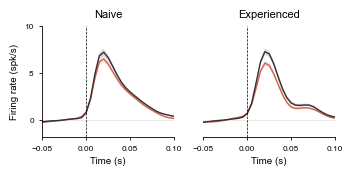

Beginner : Track vs PB (apparié) : n=727, p=7.519e-12
Expert : Track vs PB (apparié) : n=530, p=7.496e-27

Suppression Beg vs Exp (non-apparié) : p=6.959e-05
Beg : mean delta = 0.0212, n=727
Exp : mean delta = 0.0369, n=530


In [25]:


# ============================================================================
# Figure 1 : PSTH Track vs PB, un panneau par groupe (Beg / Exp)
# ============================================================================

event_idx = int(t_pre / dt)
n_tp = traj_results['beg']['track'].shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

fig, axes = plt.subplots(1, 2, figsize=(90 * MM, 45 * MM), sharey=True)

for ax, group_name, group_label in zip(axes, ['beg', 'exp'], ['Naive', 'Experienced']):
    res = traj_results[group_name]

    ax.plot(time_axis_psth, res['mean_track'], color=C_TRACK, lw=1, label='Tracking')
    ax.fill_between(time_axis_psth, res['mean_track'] - res['sem_track'],
                     res['mean_track'] + res['sem_track'], color=C_TRACK, alpha=0.18, linewidth=0)

    ax.plot(time_axis_psth, res['mean_pb'], color=C_PB, lw=1, label='Playback')
    ax.fill_between(time_axis_psth, res['mean_pb'] - res['sem_pb'],
                     res['mean_pb'] + res['sem_pb'], color=C_PB, alpha=0.18, linewidth=0)

    ax.axvline(0, color='k', lw=0.5, ls='--', zorder=5)
    ax.axhline(0, color='gray', lw=0.4, alpha=0.3, zorder=0)
    ax.set_title(group_label, fontsize=8)
    ax.set_xlabel('Time (s)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(-0.05, 0.1)

axes[0].set_ylabel('Firing rate (spk/s)')
axes[0].set_yticks([0, 5, 10])
#axes[0].legend(frameon=False, fontsize=6, loc='upper left', handlelength=1.2)

# ── retire l'axe y du 2e subplot ──
axes[1].spines['left'].set_visible(False)
axes[1].tick_params(left=False, labelleft=False)


plt.tight_layout()
plt.savefig(save_directory + 'psth_track_pb_beg_exp.pdf', dpi=300, bbox_inches='tight')
plt.show()


# ============================================================================
# Figure 2 : quantification AUC (0 à 0.1s)
# ============================================================================

mask = (time_axis_psth >= 0) & (time_axis_psth <= 0.05)
t_win = time_axis_psth[mask]

auc_track_by_group = {}
auc_pb_by_group = {}
delta_auc = {}

for group_name in ['beg', 'exp']:
    all_track = traj_results[group_name]['track']
    all_pb    = traj_results[group_name]['pb']

    auc_track = np.trapezoid(all_track[mask, :], t_win, axis=0)
    auc_pb    = np.trapezoid(all_pb[mask, :],    t_win, axis=0)

    valid = np.isfinite(auc_track) & np.isfinite(auc_pb)
    auc_track_by_group[group_name] = auc_track[valid]
    auc_pb_by_group[group_name]    = auc_pb[valid]
    delta_auc[group_name]          = auc_pb[valid] - auc_track[valid]

# ── test apparié Track vs PB, DANS chaque groupe (même neurones) ──
for group_name, group_label in zip(['beg', 'exp'], ['Beginner', 'Expert']):
    stat, p_paired = wilcoxon(auc_track_by_group[group_name], auc_pb_by_group[group_name])
    print(f"{group_label} : Track vs PB (apparié) : n={len(auc_track_by_group[group_name])}, p={p_paired:.4g}")

# ── test non-apparié : suppression (delta_auc) entre Beg et Exp ──
stat, p_group = mannwhitneyu(delta_auc['beg'], delta_auc['exp'], alternative='two-sided')
print(f"\nSuppression Beg vs Exp (non-apparié) : p={p_group:.4g}")
print(f"Beg : mean delta = {np.nanmean(delta_auc['beg']):.4f}, n={len(delta_auc['beg'])}")
print(f"Exp : mean delta = {np.nanmean(delta_auc['exp']):.4f}, n={len(delta_auc['exp'])}")


# ============================================================================
# Figure 3 : violin/boxplot de la suppression, Beg vs Exp
# ============================================================================

def sig_label(p):
    return 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/2540710239.py:45: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


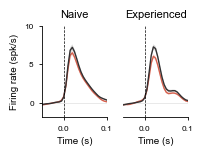

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/2540710239.py:147: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


Beginner : Track vs PB (apparié) : n=727, p=7.519e-12
Expert : Track vs PB (apparié) : n=530, p=7.496e-27

Suppression Beg vs Exp (non-apparié) : p=6.959e-05
Beg : mean delta = 0.0212, n=727
Exp : mean delta = 0.0369, n=530


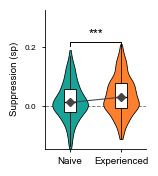

In [26]:
def stars_from_p(p):
    return 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))

def remove_outliers_iqr_series(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return s[(s >= lo) & (s <= hi)]

# ============================================================================
# Figure 1 : PSTH Track vs PB, un panneau par groupe (Beg / Exp)
# ============================================================================

event_idx = int(t_pre / dt)
n_tp = traj_results['beg']['track'].shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

fig, axes = plt.subplots(1, 2, figsize=(52 * MM, 40 * MM), sharey=True)
apply_final_style()

for ax, group_name, group_label in zip(axes, ['beg', 'exp'], ['Naive', 'Experienced']):
    res = traj_results[group_name]

    ax.plot(time_axis_psth, res['mean_track'], color=C_TRACK, lw=1, label='Tracking')
    ax.fill_between(time_axis_psth, res['mean_track'] - res['sem_track'],
                     res['mean_track'] + res['sem_track'], color=C_TRACK, alpha=0.18, linewidth=0)

    ax.plot(time_axis_psth, res['mean_pb'], color=C_PB, lw=1, label='Playback')
    ax.fill_between(time_axis_psth, res['mean_pb'] - res['sem_pb'],
                     res['mean_pb'] + res['sem_pb'], color=C_PB, alpha=0.18, linewidth=0)

    ax.axvline(0, color='k', lw=0.5, ls='--', zorder=5)
    ax.axhline(0, color='gray', lw=0.4, alpha=0.3, zorder=0)
    ax.set_title(group_label, fontsize=8)
    ax.set_xlabel('Time (s)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(-0.05, 0.1)

axes[0].set_ylabel('Firing rate (spk/s)')
axes[0].set_yticks([0, 5, 10])

axes[1].spines['left'].set_visible(False)
axes[1].tick_params(left=False, labelleft=False)

plt.tight_layout()
plt.savefig(save_directory + 'psth_track_pb_beg_exp.pdf', dpi=300, bbox_inches='tight')
plt.show()


# ============================================================================
# Figure 2 : quantification AUC (0 à 0.1s)
# ============================================================================

mask = (time_axis_psth >= 0) & (time_axis_psth <= 0.05)
t_win = time_axis_psth[mask]

auc_track_by_group = {}
auc_pb_by_group = {}
delta_auc = {}

for group_name in ['beg', 'exp']:
    all_track = traj_results[group_name]['track']
    all_pb    = traj_results[group_name]['pb']

    auc_track = np.trapezoid(all_track[mask, :], t_win, axis=0)
    auc_pb    = np.trapezoid(all_pb[mask, :],    t_win, axis=0)

    valid = np.isfinite(auc_track) & np.isfinite(auc_pb)
    auc_track_by_group[group_name] = auc_track[valid]
    auc_pb_by_group[group_name]    = auc_pb[valid]
    delta_auc[group_name]          = auc_pb[valid] - auc_track[valid]

for group_name, group_label in zip(['beg', 'exp'], ['Beginner', 'Expert']):
    stat, p_paired = wilcoxon(auc_track_by_group[group_name], auc_pb_by_group[group_name])
    print(f"{group_label} : Track vs PB (apparié) : n={len(auc_track_by_group[group_name])}, p={p_paired:.4g}")

stat, p_group = mannwhitneyu(delta_auc['beg'], delta_auc['exp'], alternative='two-sided')
print(f"\nSuppression Beg vs Exp (non-apparié) : p={p_group:.4g}")
print(f"Beg : mean delta = {np.nanmean(delta_auc['beg']):.4f}, n={len(delta_auc['beg'])}")
print(f"Exp : mean delta = {np.nanmean(delta_auc['exp']):.4f}, n={len(delta_auc['exp'])}")


# ============================================================================
# Figure 3 : violin plein + double boxplot de la suppression, Beg vs Exp
# ============================================================================

fig, ax_ins = plt.subplots(figsize=(40 * MM, 45 * MM))
apply_final_style()
lw = plt.rcParams['lines.linewidth']
colors_violin = [C_BEG, C_EXP]

delta_display = {}
for group_name in ['beg', 'exp']:
    delta_display[group_name] = remove_outliers_iqr_series(pd.Series(delta_auc[group_name])).values

for i, (group_name, color) in enumerate(zip(['beg', 'exp'], colors_violin)):
    data = delta_display[group_name]

    parts = ax_ins.violinplot(data, positions=[i], widths=0.7,
                               showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_edgecolor('black')
        pc.set_linewidth(lw * 0.8)
        pc.set_alpha(1.0)
        pc.set_zorder(1)

    # couche 1 : whiskers seuls
    ax_ins.boxplot(data, positions=[i], widths=0.001,
                   patch_artist=False, showcaps=False, showfliers=False,
                   medianprops=dict(color='none'),
                   boxprops=dict(color='none'),
                   whiskerprops=dict(color='black', linewidth=lw * 0.8),
                   zorder=2)

    # couche 2 : box blanche + médiane
    ax_ins.boxplot(data, positions=[i], widths=0.22,
                   patch_artist=True, showcaps=False, showfliers=False,
                   medianprops=dict(color='black', linewidth=lw * 1.3),
                   boxprops=dict(facecolor='white', edgecolor='black', linewidth=lw * 0.9),
                   whiskerprops=dict(color='none'),
                   zorder=3)

# ── ligne reliant les médianes (sur données sans outliers) ──
med_beg = np.median(delta_display['beg'])
med_exp = np.median(delta_display['exp'])
ax_ins.plot([0, 1], [med_beg, med_exp], color='#444444', linewidth=lw * 1.1,
            marker='D', markersize=4, zorder=4)

all_data = np.concatenate([delta_display['beg'], delta_display['exp']])
y_low, y_high = np.nanpercentile(all_data, [2, 98])
margin = abs(y_high - y_low) * 0.15
ax_ins.set_ylim(y_low - margin, y_high + margin * 4)
ax_ins.yaxis.set_major_locator(ticker.MaxNLocator(3))

y_top = y_high + margin
ax_ins.plot([0, 0, 1, 1], [y_top, y_top + margin * 0.3, y_top + margin * 0.3, y_top],
            lw=lw, color='k')
ax_ins.text(0.5, y_top + margin * 0.4, stars_from_p(p_group), ha='center', va='bottom', fontsize=9)

ax_ins.set_xticks([0, 1])
ax_ins.set_xticklabels(['Naive', 'Experienced'],  fontsize=7)
ax_ins.set_ylabel('Suppression (sp)')
ax_ins.axhline(0, color='gray', linestyle='--', zorder=0)
ax_ins.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(save_directory + '1J.pdf', dpi=600, transparent=True)
plt.savefig(save_directory + '1J.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3072219773.py:180: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


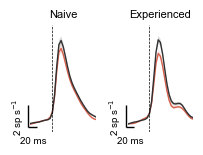

In [27]:
def add_scale_bar(ax, x0, y0, dx, dy, x_range, y_range,
                  label_x, label_y, lw=1.0, fontsize=7):

    ax.plot(
        [x0, x0 + dx], [y0, y0],
        color='k', lw=lw,
        solid_capstyle='butt',
        clip_on=False
    )

    ax.plot(
        [x0, x0], [y0, y0 + dy],
        color='k', lw=lw,
        solid_capstyle='butt',
        clip_on=False
    )

    ax.text(
        x0 + dx / 2,
        y0 - y_range * 0.1,
        label_x,
        ha='center',
        va='top',
        fontsize=fontsize
    )

    ax.text(
        x0 - x_range * 0.04,
        y0 + dy / 2,
        label_y,
        ha='right',
        va='center',
        fontsize=fontsize,
        rotation=90
    )


# ============================================================================
# Figure 1 : PSTH Track vs PB, un panneau par groupe (Beg / Exp)
# ============================================================================

event_idx = int(t_pre / dt)
n_tp = traj_results['beg']['track'].shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

fig, axes = plt.subplots(
    1, 2,
    figsize=(52 * MM, 40 * MM),
    sharey=True
)

apply_final_style()

xlim = (-0.05, 0.1)

# mêmes limites Y pour les deux panneaux
y_min = np.inf
y_max = -np.inf

for group_name in ['beg', 'exp']:
    res = traj_results[group_name]

    for mean, sem in [
        (res['mean_track'], res['sem_track']),
        (res['mean_pb'], res['sem_pb'])
    ]:
        valid_t = (
            np.isfinite(mean)
            & np.isfinite(sem)
            & (time_axis_psth >= xlim[0])
            & (time_axis_psth <= xlim[1])
        )

        y_min = min(
            y_min,
            np.nanmin(mean[valid_t] - sem[valid_t])
        )

        y_max = max(
            y_max,
            np.nanmax(mean[valid_t] + sem[valid_t])
        )


# marge + paramètres scale bar
x_range = xlim[1] - xlim[0]
y_range = y_max - y_min

scale_dx = 0.02       # 20 ms

raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy))
scale_dy = np.round(raw_dy / magnitude) * magnitude


for ax, group_name, group_label in zip(
    axes,
    ['beg', 'exp'],
    ['Naive', 'Experienced']
):

    res = traj_results[group_name]

    # Tracking
    ax.plot(
        time_axis_psth,
        res['mean_track'],
        color=C_TRACK,
        lw=1
    )

    ax.fill_between(
        time_axis_psth,
        res['mean_track'] - res['sem_track'],
        res['mean_track'] + res['sem_track'],
        color=C_TRACK,
        alpha=0.18,
        linewidth=0
    )

    # Playback
    ax.plot(
        time_axis_psth,
        res['mean_pb'],
        color=C_PB,
        lw=1
    )

    ax.fill_between(
        time_axis_psth,
        res['mean_pb'] - res['sem_pb'],
        res['mean_pb'] + res['sem_pb'],
        color=C_PB,
        alpha=0.18,
        linewidth=0
    )

    # sound onset
    ax.axvline(
        0,
        color='k',
        lw=0.5,
        ls='--',
        zorder=5
    )

    ax.set_xlim(xlim)

    ax.set_ylim(
        y_min - y_range * 0.08,
        y_max + y_range * 0.12
    )

    ax.set_title(
        group_label,
        fontsize=8
    )

    # ── SCALE BAR ──
    x0 = xlim[0] - x_range * 0.03
    y0 = y_min - y_range * 0.03

    add_scale_bar(
        ax,
        x0,
        y0,
        scale_dx,
        scale_dy,
        x_range,
        y_range,
        label_x=f'{int(scale_dx * 1000)} ms',
        label_y=f'{scale_dy:g} sp s$^{{-1}}$',
        fontsize=7
    )

    # retire tous les axes
    ax.axis('off')


plt.tight_layout()

plt.savefig(
    save_directory + '1i.pdf',
    transparent=True
)

plt.savefig(
    save_directory + '1i.png',
    dpi=600,
    transparent=True
)

plt.show()

['FETA_headstage_0' 'HERCULE_headstage_0' 'MMELOIK_headstage_0'
 'MMELOIK_headstage_1' 'NAPOLEON_headstage_0' 'NAPOLEON_headstage_1'] 6
Wilcoxon evoked tracking vs playback (par animal) : W=0, p=0.0312, n=6 animaux


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3774360252.py:71: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(traj[peak_mask, :], x=t_peak, axis=0)


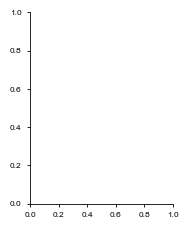

In [29]:
import re
import numpy as np
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

# ── 1. PSTH par session (inchangé) ────────────────────────────────────────
track_per_session, pb_per_session, n_trials_per_session = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins,
    n_baseline_bins=int(0.05 / dt)
)

all_traj_tracking = concat_neurons(track_per_session)   # [window_size, total_neurons]
all_traj_playback = concat_neurons(pb_per_session)


# ── 2. Id animal_headstage par neurone, aligné avec concat_neurons ────────
def _animal_headstage_id(idx_arr):
    """Extrait 'animal_headstage_X' depuis un id du type
    'FETA_20251216_SESSION_00_headstage_0_neuron7'."""
    idx_arr = np.asarray(idx_arr)
    if idx_arr.ndim > 1:
        idx_arr = idx_arr[:, 0]  # id constant sur la fenêtre temporelle si stocké comme n_data
    pattern = re.compile(r'^([^_]+).*?(headstage_\d+)', re.IGNORECASE)

    def _extract(x):
        m = pattern.match(str(x))
        if m is None:
            raise ValueError(f"Format d'id inattendu: {x}")
        return f"{m.group(1)}_{m.group(2)}"

    return np.array([_extract(x) for x in idx_arr])


animal_id_per_session = [_animal_headstage_id(a) for a in neuron_idx_reorganised]
all_animal_ids = np.concatenate(animal_id_per_session)

assert len(all_animal_ids) == all_traj_tracking.shape[1] == all_traj_playback.shape[1]

# ── 3. Exclusion d'un headstage spécifique ────────────────────────────────

all_animal_ids    = all_animal_ids
all_traj_tracking = all_traj_tracking
all_traj_playback = all_traj_playback

unique_animals = np.unique(all_animal_ids)
n_animals = len(unique_animals)
w = all_traj_tracking.shape[0]
print(unique_animals, n_animals)


# ── 4. PSTH moyen par animal, puis moyenne/SEM inter-animaux (plot principal) ──
mean_per_animal_track = np.full((w, n_animals), np.nan)
mean_per_animal_pb    = np.full((w, n_animals), np.nan)

for i, a in enumerate(unique_animals):
    mask = all_animal_ids == a
    mean_per_animal_track[:, i] = np.nanmean(all_traj_tracking[:, mask], axis=1)
    mean_per_animal_pb[:, i]    = np.nanmean(all_traj_playback[:, mask], axis=1)

mean_traj_track = np.nanmean(mean_per_animal_track, axis=1)
sem_traj_track  = np.nanstd(mean_per_animal_track, axis=1) / np.sqrt(np.sum(~np.isnan(mean_per_animal_track), axis=1))
mean_traj_pb    = np.nanmean(mean_per_animal_pb, axis=1)
sem_traj_pb     = np.nanstd(mean_per_animal_pb, axis=1) / np.sqrt(np.sum(~np.isnan(mean_per_animal_pb), axis=1))


def compute_evoked(traj, time, peak_window=(0.0, 0.1)):
    """traj: [window_size, n_neurons], déjà baseline-corrigé en amont (_extract_trials).
    evoked = AUC entre peak_window."""
    peak_mask = (time >= peak_window[0]) & (time <= peak_window[1])
    t_peak = time[peak_mask]
    return np.trapz(traj[peak_mask, :], x=t_peak, axis=0)


evoked_track_n = compute_evoked(all_traj_tracking, time)  # [total_neurons]
evoked_pb_n    = compute_evoked(all_traj_playback, time)

# ── 6. Moyenne evoked par animal ──────────────────────────────────────────
evoked_track_animal = np.full(n_animals, np.nan)
evoked_pb_animal    = np.full(n_animals, np.nan)

for i, a in enumerate(unique_animals):
    mask = all_animal_ids == a
    valid = np.isfinite(evoked_track_n[mask]) & np.isfinite(evoked_pb_n[mask])
    evoked_track_animal[i] = np.nanmean(evoked_track_n[mask][valid])
    evoked_pb_animal[i]    = np.nanmean(evoked_pb_n[mask][valid])

valid_a = np.isfinite(evoked_track_animal) & np.isfinite(evoked_pb_animal)
et_a, ep_a = evoked_track_animal[valid_a], evoked_pb_animal[valid_a]

stat, p = wilcoxon(et_a, ep_a, alternative='two-sided')
print(f"Wilcoxon evoked tracking vs playback (par animal) : W={stat:.0f}, p={p:.4f}, n={valid_a.sum()} animaux")


# ── 7. Plot façon "Expected/Probe" ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(45 * MM, 55 * MM))

x_track, x_pb = 0, 1


In [31]:
import pandas as pd
import statsmodels.formula.api as smf

df = pd.DataFrame({
    'evoked': np.concatenate([evoked_track_n, evoked_pb_n]),
    'condition': ['track'] * len(evoked_track_n) + ['pb'] * len(evoked_pb_n),
    'animal': np.concatenate([all_animal_ids, all_animal_ids]),
})
df = df.dropna(subset=['evoked'])

model = smf.mixedlm("evoked ~ condition", df, groups=df["animal"])
result = model.fit()
print(result.summary())

            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   evoked   
No. Observations:   2514      Method:               REML     
No. Groups:         6         Scale:                0.0798   
Min. group size:    250       Log-Likelihood:       -406.3749
Max. group size:    622       Converged:            Yes      
Mean group size:    419.0                                    
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           0.300    0.040  7.520 0.000  0.222  0.378
condition[T.track] -0.038    0.011 -3.375 0.001 -0.060 -0.016
Group Var           0.009    0.021                           



/Users/felicie/phd_final/env/lib/python3.9/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/590121149.py:52: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


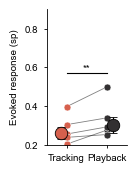

In [32]:
apply_final_style()
fig, ax = plt.subplots(figsize=(35 * MM, 45 * MM))

x_track, x_pb = 0, 1


# lignes individuelles par animal
for et, ep in zip(et_a, ep_a):
    ax.plot([x_track, x_pb], [et, ep], color='black', linewidth=0.6, alpha=0.5, zorder=1)

# points individuels
ax.scatter(np.full_like(et_a, x_track), et_a, color=C_TRACK, s=25,
           edgecolors='white', linewidths=0.4, zorder=2)
ax.scatter(np.full_like(ep_a, x_pb), ep_a, color=C_PB, s=25,
           edgecolors='white', linewidths=0.4, zorder=2)

# moyenne ± SEM par condition (gros point, décalé pour ne pas chevaucher les lignes)
mean_track, sem_track_a = np.nanmean(et_a), np.nanstd(et_a) / np.sqrt(len(et_a))
mean_pb,    sem_pb_a    = np.nanmean(ep_a), np.nanstd(ep_a) / np.sqrt(len(ep_a))

offset = 0.15
ax.errorbar(x_track - offset, mean_track, yerr=sem_track_a, fmt='o', color=C_TRACK,
            markersize=9, markeredgecolor='black', markeredgewidth=0.6,
            ecolor='black', elinewidth=0.8, capsize=3, zorder=3)
ax.errorbar(x_pb + offset, mean_pb, yerr=sem_pb_a, fmt='o', color=C_PB,
            markersize=9, markeredgecolor='black', markeredgewidth=0.6,
            ecolor='black', elinewidth=0.8, capsize=3, zorder=3)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.7, zorder=0)

# ── stats : LMM (intercept aléatoire par animal), pas le Wilcoxon apparié ──
# beta = -0.047, p = 0.004 (issu du modèle mixedlm converged)
p_lmm = 0.004

y_max = max(et_a.max(), ep_a.max())
y_star = y_max + 0.15 * abs(y_max)
ax.plot([x_track, x_pb], [y_star, y_star], color='black', linewidth=0.8)
ax.text((x_track + x_pb) / 2, y_star, sig_label(p_lmm), ha='center', va='bottom', fontsize=7)

ax.set_xticks([x_track, x_pb])
ax.set_xticklabels(['Tracking', 'Playback'], fontsize=8)
ax.set_xlim(x_track - 0.5, x_pb + 0.5)
ax.set_ylim(0.2, 0.9)

ax.set_ylabel('Evoked response (sp)', fontsize=7)
ax.tick_params(labelsize=7)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)



plt.tight_layout()
plt.savefig(save_directory + '1H.pdf',
            dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + '1H.png',
            dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Sustained ?

In [34]:
track_per_session, pb_per_session, n_trials_per_session = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=False)

all_traj_tracking = concat_neurons(track_per_session)   # [window_size, total_neurons]
all_traj_playback = concat_neurons(pb_per_session)

mean_traj_track = np.nanmean(all_traj_tracking, axis=1)
sem_traj_track  = np.nanstd(all_traj_tracking, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_tracking), axis=1))

mean_traj_pb = np.nanmean(all_traj_playback, axis=1)
sem_traj_pb  = np.nanstd(all_traj_playback, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_playback), axis=1))


IndexError: invalid index to scalar variable.

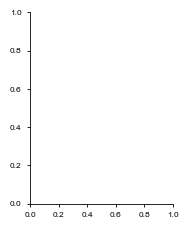

In [35]:
def add_scale_bar(ax, x0, y0, dx, dy, x_range, y_range, label_x, label_y, lw=1.0, fontsize=6):
    ax.plot([x0, x0 + dx], [y0, y0], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.plot([x0, x0], [y0, y0 + dy], color='k', lw=lw, solid_capstyle='butt', clip_on=False)
    ax.text(x0 + dx / 2, y0 - y_range * 0.06, label_x, ha='center', va='top', fontsize=fontsize)
    ax.text(x0 - x_range * 0.04, y0 + dy / 2, label_y, ha='right', va='center', fontsize=fontsize, rotation=90)


xlim = (-0.05, 0.1)
scale_dx = 0.02  # 20ms

fig, ax = plt.subplots( figsize=(45 * MM, 55 * MM))
apply_final_style()

valid_t = np.isfinite(mean_pb) & np.isfinite(sem_pb) & (time >= xlim[0]) & (time <= xlim[1])

ax.plot(time[valid_t], mean_pb[valid_t], color=C_PB, lw=1.4, zorder=2)
ax.fill_between(time[valid_t], mean_pb[valid_t] - sem_pb[valid_t], mean_pb[valid_t] + sem_pb[valid_t],
                color=C_PB, alpha=0.25, linewidth=0)

ax.axvline(0, color='k', lw=0.7, ls='--', zorder=1, alpha=0.6)

x_range = xlim[1] - xlim[0]
y_min = np.nanmin(mean_pb[valid_t] - sem_pb[valid_t])
y_max = np.nanmax(mean_pb[valid_t] + sem_pb[valid_t])
y_range = y_max - y_min
ax.set_xlim(xlim)
ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.15)

raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
scale_dy = np.round(raw_dy / magnitude) * magnitude

x0 = xlim[0] - x_range * 0.01
y0 = y_min - y_range * 0.02

y_min = min(0, np.nanmin(mean_pb[valid_t] - sem_pb[valid_t]))
y_max = np.nanmax(mean_pb[valid_t] + sem_pb[valid_t])
y_range = y_max - y_min
ax.set_xlim(xlim)
ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.15)
#add_scale_bar(ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
              #label_x=f'{int(scale_dx*1000)}ms', label_y=f'{scale_dy:g} Hz', fontsize=6)

ax.axhline(0, c = 'gray', linestyle = '--')

ax.axis('off')

plt.tight_layout()
plt.savefig(save_directory + 'psth_playback_only.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + 'psth_playback_only.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_46131/950538917.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


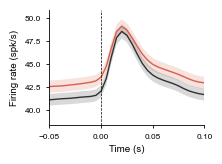

In [ ]:
event_idx = int(t_pre / dt)
n_tp = all_traj_tracking.shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

apply_final_style()
fig, ax = plt.subplots(figsize=(55 * MM, 42 * MM))

ax.plot(time_axis_psth, mean_traj_track, color=C_TRACK, lw=1, label='Tracking')
ax.fill_between(time_axis_psth, mean_traj_track - sem_traj_track,
                 mean_traj_track + sem_traj_track, color=C_TRACK, alpha=0.18, linewidth=0)

ax.plot(time_axis_psth, mean_traj_pb, color=C_PB, lw=1, label='Playback')
ax.fill_between(time_axis_psth, mean_traj_pb - sem_traj_pb,
                 mean_traj_pb + sem_traj_pb, color=C_PB, alpha=0.18, linewidth=0)

ax.axvline(0, color='k', lw=0.5, ls='--', zorder=5)

# ── y-lim resserré sur l'étendue réelle affichée ──
y_all = np.concatenate([mean_traj_track - sem_traj_track, mean_traj_track + sem_traj_track,
                         mean_traj_pb - sem_traj_pb, mean_traj_pb + sem_traj_pb])
y_low, y_high = np.nanmin(y_all), np.nanmax(y_all)
margin = (y_high - y_low) * 0.1
ax.set_ylim(y_low - margin, y_high + margin)

ax.set_xlabel('Time (s)')
ax.set_ylabel('Firing rate (spk/s)')
#ax.legend(frameon=False, fontsize=6, loc='upper left', handlelength=1.2)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(-0.05, 0.1)

plt.tight_layout()
#plt.savefig(save_directory + 'psth_track_pb_population.pdf', dpi=300, bbox_inches='tight')
plt.show()

/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_46131/2584710847.py:44: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


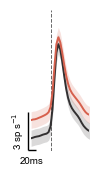

In [ ]:


event_idx = int(t_pre / dt)
n_tp = all_traj_tracking.shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

xlim = (-0.05, 0.1)
scale_dx = 0.02  # 20ms

apply_final_style()
fig, ax = plt.subplots(figsize=(26 * MM, 45 * MM))

valid_t = (time_axis_psth >= xlim[0]) & (time_axis_psth <= xlim[1])

y_min, y_max = np.inf, -np.inf
for mean, sem, color, label in [
    (mean_traj_pb,    sem_traj_pb,    C_PB,    'Playback'),
    (mean_traj_track, sem_traj_track, C_TRACK, 'Tracking'),
]:
    ax.plot(time_axis_psth[valid_t], mean[valid_t], color=color, lw=1.4, label=label, zorder=2)
    ax.fill_between(time_axis_psth[valid_t], mean[valid_t] - sem[valid_t], mean[valid_t] + sem[valid_t],
                    color=color, alpha=0.18, linewidth=0)
    y_min = min(y_min, np.nanmin(mean[valid_t] - sem[valid_t]))
    y_max = max(y_max, np.nanmax(mean[valid_t] + sem[valid_t]))

ax.axvline(0, color='k', lw=0.7, ls='--', zorder=1, alpha=0.6)

x_range = xlim[1] - xlim[0]
y_range = y_max - y_min
ax.set_xlim(xlim)
ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.15)

# ── barre d'échelle Hz adaptée, arrondie à une valeur propre ──
raw_dy = y_range * 0.3
magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
scale_dy = np.round(raw_dy / magnitude) * magnitude

x0 = xlim[0] - x_range * 0.05
y0 = y_min - y_range * 0.03
add_scale_bar(ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
              label_x=f'{int(scale_dx*1000)}ms', label_y=f'{scale_dy:g} sp s$^{{-1}}$', fontsize=7)

#ax.legend(frameon=False, fontsize=6, loc='upper left', handlelength=1.2)
ax.axis('off')

plt.tight_layout()
plt.savefig(save_directory + '1L.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + '1L.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

Sustained diff (PB - Track) : n=1257, p=4.023e-30
  mean diff = -1.497


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_75446/3568160366.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


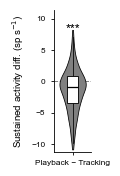

In [36]:
sustained_mask = (time_axis_psth >= -0.2) & (time_axis_psth < 0)

sustained_track = np.nanmean(all_traj_tracking[sustained_mask, :], axis=0)
sustained_pb    = np.nanmean(all_traj_playback[sustained_mask, :], axis=0)

valid = np.isfinite(sustained_track) & np.isfinite(sustained_pb)
sustained_diff = (sustained_pb - sustained_track)[valid]

# ── test contre 0 (la différence est-elle significativement différente de 0) ──
stat, p_sustained = wilcoxon(sustained_diff)
print(f"Sustained diff (PB - Track) : n={len(sustained_diff)}, p={p_sustained:.4g}")
print(f"  mean diff = {np.nanmean(sustained_diff):.3f}")


def stars_from_p(p):
    return 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))

def remove_outliers_iqr_series(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return s[(s >= lo) & (s <= hi)]

fig, ax = plt.subplots(figsize=(26 * MM, 45 * MM))
apply_final_style()
lw = plt.rcParams['lines.linewidth']

sustained_diff_display = remove_outliers_iqr_series(pd.Series(sustained_diff)).values

parts = ax.violinplot(sustained_diff_display, positions=[0], widths=0.7,
                       showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor('gray')
    pc.set_edgecolor('black')
    pc.set_linewidth(lw * 0.8)
    pc.set_alpha(1.0)
    pc.set_zorder(1)

# couche 1 : whiskers seuls
ax.boxplot(sustained_diff_display, positions=[0], widths=0.001,
           patch_artist=False, showcaps=False, showfliers=False,
           medianprops=dict(color='none'),
           boxprops=dict(color='none'),
           whiskerprops=dict(color='black', linewidth=lw * 0.8),
           zorder=2)

# couche 2 : box blanche + médiane
ax.boxplot(sustained_diff_display, positions=[0], widths=0.3,
           patch_artist=True, showcaps=False, showfliers=False,
           medianprops=dict(color='black', linewidth=lw * 1.3),
           boxprops=dict(facecolor='white', edgecolor='black', linewidth=lw * 0.9),
           whiskerprops=dict(color='none'),
           zorder=3)

y_low, y_high = np.nanpercentile(sustained_diff_display, [5, 95])
margin = abs(y_high - y_low) * 0.15
ax.set_ylim(y_low - margin*2, y_high + margin * 4)

y_top = y_high + margin
ax.text(0, y_top + margin * 0.7, stars_from_p(p_sustained), ha='center', va='bottom', fontsize=9)

ax.set_xticks([0])
ax.set_xticklabels(['Playback − Tracking'])
ax.set_ylabel(r'Sustained activity diff. (sp s$^{{-1}}$)')
ax.axhline(0, color='gray', linestyle='--', zorder=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(save_directory + '1_N.pdf', dpi=600, bbox_inches='tight')
plt.show()

AUC diff (PB - Track), 0-0.05s : n=1257, p=2.687e-10
  mean diff = -0.046


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_46131/2587434339.py:71: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


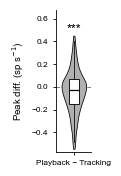

In [ ]:
peak_mask = (time_axis_psth >= 0) & (time_axis_psth <= 0.05)
t_win_peak = time_axis_psth[peak_mask]

auc_track = np.trapezoid(all_traj_tracking[peak_mask, :], t_win_peak, axis=0)
auc_pb    = np.trapezoid(all_traj_playback[peak_mask, :], t_win_peak, axis=0)

valid = np.isfinite(auc_track) & np.isfinite(auc_pb)
auc_diff = (auc_pb - auc_track)[valid]

# ── test contre 0 ──
stat, p_auc = wilcoxon(auc_diff)
print(f"AUC diff (PB - Track), 0-0.05s : n={len(auc_diff)}, p={p_auc:.4g}")
print(f"  mean diff = {np.nanmean(auc_diff):.3f}")


def stars_from_p(p):
    return 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))

def remove_outliers_iqr_series(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return s[(s >= lo) & (s <= hi)]

fig, ax = plt.subplots(figsize=(26 * MM, 45 * MM))
apply_final_style()
lw = plt.rcParams['lines.linewidth']

GRAY_LIGHT = '#B0B0B0'

auc_diff_display = remove_outliers_iqr_series(pd.Series(auc_diff)).values

parts = ax.violinplot(auc_diff_display, positions=[0], widths=0.7,
                       showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor(GRAY_LIGHT)
    pc.set_edgecolor('black')
    pc.set_linewidth(lw * 0.8)
    pc.set_alpha(1.0)
    pc.set_zorder(1)

# couche 1 : whiskers seuls
ax.boxplot(auc_diff_display, positions=[0], widths=0.001,
           patch_artist=False, showcaps=False, showfliers=False,
           medianprops=dict(color='none'),
           boxprops=dict(color='none'),
           whiskerprops=dict(color='black', linewidth=lw * 0.8),
           zorder=2)

# couche 2 : box blanche + médiane
ax.boxplot(auc_diff_display, positions=[0], widths=0.3,
           patch_artist=True, showcaps=False, showfliers=False,
           medianprops=dict(color='black', linewidth=lw * 1.3),
           boxprops=dict(facecolor='white', edgecolor='black', linewidth=lw * 0.9),
           whiskerprops=dict(color='none'),
           zorder=3)

y_low, y_high = np.nanpercentile(auc_diff_display, [5, 95])
margin = abs(y_high - y_low) * 0.15
ax.set_ylim(y_low - margin*2, y_high + margin * 4)

y_top = y_high + margin
ax.text(0, y_top + margin * 0.7, stars_from_p(p_auc), ha='center', va='bottom', fontsize=9)

ax.set_xticks([0])
ax.set_xticklabels(['Playback − Tracking'])
ax.set_ylabel(r'Peak diff. (sp s$^{{-1}}$)')
ax.axhline(0, color='gray', linestyle='--', zorder=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(save_directory + '1_M.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.savefig(save_directory + '1_M.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

Neurones tirés : [np.int64(597), np.int64(861)]


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_46131/461154956.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.3, h_pad=1.2)


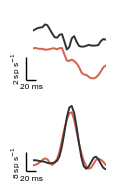

In [ ]:
def plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    neuron_ids=None,
    n_neurons=2,
    neuron_labels=None,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.05,
    xlim=(-0.05, 0.1),
    scale_dx=0.02,  # 20 ms
):

    n_total = all_traj_tracking.shape[1]

    if neuron_ids is None:
        neuron_ids = np.random.choice(n_total, size=n_neurons, replace=False)
        print(f"Neurones tirés : {list(neuron_ids)}")

    if neuron_labels is None:
        neuron_labels = [f'n{nid}' for nid in neuron_ids]

    auc_idx = np.where((time >= auc_t_start) & (time <= auc_t_end))[0]

    fig, axes = plt.subplots(
        len(neuron_ids), 1,
        figsize=(26 * MM, 45 * MM),
        sharex=True,
    )
    if len(neuron_ids) == 1:
        axes = [axes]

    x_range = xlim[1] - xlim[0]  # 0.15, calculé depuis xlim -> jamais désynchronisé

    for i, (ax, nid, nlabel) in enumerate(zip(axes, neuron_ids, neuron_labels)):
        tr = all_traj_tracking[:, nid]
        pb = all_traj_playback[:, nid]

        y_min, y_max = np.inf, -np.inf
        for trace, color in [(tr, C_TRACK), (pb, C_PB)]:
            v = np.isfinite(trace)
            ax.plot(time[v], trace[v], color=color, lw=1.4, zorder=2)
            y_min = min(y_min, np.nanmin(trace[v]))
            y_max = max(y_max, np.nanmax(trace[v]))

        y_range = y_max - y_min
        ax.set_xlim(xlim)
        ax.set_ylim(y_min - y_range * 0.04, y_max + y_range * 0.08)

        # ── barre Hz : ~30% de l'étendue ──
        raw_dy = y_range * 0.3
        magnitude = 10 ** np.floor(np.log10(raw_dy)) if raw_dy > 0 else 1
        scale_dy = np.round(raw_dy / magnitude) * magnitude

        x0 = xlim[0] - x_range * 0.09
        y0 = y_min - y_range * 0.02
        add_scale_bar(
        ax, x0, y0, scale_dx, scale_dy, x_range, y_range,
        label_x=f'{int(scale_dx*1000)} ms',
        label_y=f'{scale_dy:g} sp s$^{{-1}}$',
        fontsize=6
)

        ax.axis('off')

    plt.tight_layout(pad=0.3, h_pad=1.2)
    plt.savefig(save_directory + 'fig_2A.pdf', transparent=True, dpi=600)
    #plt.savefig(save_directory + 'fig_2A.png', bbox_inches='tight', dpi=600)
    plt.show()

plot_psth_two_example_neurons(
    all_traj_tracking,
    all_traj_playback,
    time,
    C_TRACK=C_TRACK,
    C_PB=C_PB,
    auc_t_start=0.0,
    auc_t_end=0.1,
)

In [ ]:
a = 

SyntaxError: invalid syntax (2792523948.py, line 1)

In [ ]:

groups = {
    'beg': (n_data_a1_beg, f_data_a1_beg),
    'exp': (n_data_a1_exp, f_data_a1_exp),
}

traj_results = {}

for group_name, (n_data, f_data) in groups.items():
    track_ps, pb_ps, _ = build_psth_per_session(n_data, f_data, n_pre_bins, n_post_bins, baseline_remove=False)

    all_track = concat_neurons(track_ps)
    all_pb    = concat_neurons(pb_ps)

    traj_results[group_name] = {
        'track': all_track,
        'pb':    all_pb,
        'mean_track': np.nanmean(all_track, axis=1),
        'sem_track':  np.nanstd(all_track, axis=1) / np.sqrt(np.sum(~np.isnan(all_track), axis=1)),
        'mean_pb':    np.nanmean(all_pb, axis=1),
        'sem_pb':     np.nanstd(all_pb, axis=1)   / np.sqrt(np.sum(~np.isnan(all_pb),    axis=1)),
    }

Sustained diff (PB - Track), Beg vs Exp : p=0.07646
  Beg : mean=-1.204, n=727
  Exp : mean=-1.812, n=530


/var/folders/w2/2vn_mmlj0bl8mbc0m82rp8hh0000gn/T/ipykernel_36183/3237346118.py:65: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


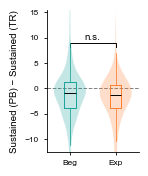

In [ ]:
event_idx = int(t_pre / dt)
n_tp = traj_results['beg']['track'].shape[0]
time_axis_psth = (np.arange(n_tp) - event_idx) * dt

sustained_mask = (time_axis_psth >= -0.1) & (time_axis_psth < 0)

sustained_diff_by_group = {}

for group_name in ['beg', 'exp']:
    all_track = traj_results[group_name]['track']
    all_pb    = traj_results[group_name]['pb']

    sustained_track = np.nanmean(all_track[sustained_mask, :], axis=0)
    sustained_pb    = np.nanmean(all_pb[sustained_mask, :],    axis=0)

    valid = np.isfinite(sustained_track) & np.isfinite(sustained_pb)
    sustained_diff_by_group[group_name] = (sustained_pb - sustained_track)[valid]

# ── test non-apparié : diff sustained (PB - Track) entre Beg et Exp ──
stat, p_diff = mannwhitneyu(sustained_diff_by_group['beg'], sustained_diff_by_group['exp'], alternative='two-sided')
print(f"Sustained diff (PB - Track), Beg vs Exp : p={p_diff:.4g}")
print(f"  Beg : mean={np.nanmean(sustained_diff_by_group['beg']):.3f}, n={len(sustained_diff_by_group['beg'])}")
print(f"  Exp : mean={np.nanmean(sustained_diff_by_group['exp']):.3f}, n={len(sustained_diff_by_group['exp'])}")


# ── figure : violin/boxplot de la diff sustained, Beg vs Exp ──
def sig_label(p):
    return 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))

fig, ax = plt.subplots(figsize=(38 * MM, 45 * MM))

for i, (group_name, color) in enumerate(zip(['beg', 'exp'], [C_BEG, C_EXP])):
    data = sustained_diff_by_group[group_name]

    parts = ax.violinplot(data, positions=[i], widths=0.7,
                           showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_edgecolor('none')
        pc.set_alpha(0.25)
        pc.set_zorder(1)

    ax.boxplot(data, positions=[i], widths=0.25,
               patch_artist=False, showcaps=False, showfliers=False,
               medianprops=dict(color='black', linewidth=lw * 1.0),
               boxprops=dict(color=color, linewidth=lw),
               whiskerprops=dict(color=color, linewidth=lw * 0.8),
               zorder=3)

all_data = np.concatenate([sustained_diff_by_group['beg'], sustained_diff_by_group['exp']])
y_low, y_high = np.nanpercentile(all_data, [5, 95])
margin = abs(y_high - y_low) * 0.15
ax.set_ylim(y_low - margin, y_high + margin * 4)

y_top = y_high + margin
ax.plot([0, 0, 1, 1], [y_top, y_top + margin * 0.3, y_top + margin * 0.3, y_top], lw=lw, color='k')
ax.text(0.5, y_top + margin * 0.4, sig_label(p_diff), ha='center', va='bottom', fontsize=fs)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Beg', 'Exp'])
ax.set_ylabel('Sustained (PB) − Sustained (TR)')
ax.axhline(0, color='gray', linestyle='--', zorder=0)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(save_directory + 'sustained_diff_beg_exp.pdf', dpi=300, bbox_inches='tight')
plt.show()

## evolution of suppression within session

## 6. Effect of expertise (Beginner / Expert) x quarter

In [ ]:
groups = {
    'beg': (n_data_a1_beg, f_data_a1_beg),
    'exp': (n_data_a1_exp, f_data_a1_exp),
}


### Example neuron PSTHs (Q1 vs Q4)

## 7. SumUp

AJOUTER difference de niveau de suppression au depart Q1 de beg vs Q1 de exp
Test d'interaction propre (quartile continu × groupe), niveau session — 

Tester Q4 de beg avec Q1 de exp 
On peut ausi tester tous les Q deux a deux entre beg et exp ??


In [ ]:
def extract_animal(neuron_name):
    """
    neuron_name format: 'ANIMAL_20241202_..._hs_0_neuron16' (ou 'headstage_0')
    Animal ID = nom de l'animal + numéro après 'hs' (ou 'headstage').
    """
    parts = neuron_name.split('_')
    animal_name = parts[0]

    # trouve l'indice du token 'hs' ou 'headstage', prend le suivant
    for i, p in enumerate(parts):
        if p in ('hs', 'headstage'):
            hs_num = parts[i + 1]
            return f"{animal_name}_hs{hs_num}"

    return animal_name  # fallback si le pattern n'est pas trouvé

In [ ]:
def extract_animal(neuron_name):
    parts = neuron_name.split('_')
    animal_name = parts[0]
    for i, p in enumerate(parts):
        if p in ('hs', 'headstage'):
            hs_num = parts[i + 1]
            return f"{animal_name}_hs{hs_num}"
    return animal_name

def build_neuron_ids_with_animal(n_data_list, neuron_idx_list, group_label):
    ids, animals = [], []
    for sess_idx, (n_data, names) in enumerate(zip(n_data_list, neuron_idx_list)):
        n_neurons = n_data.shape[0]
        assert len(names) == n_neurons, f"Mismatch session {sess_idx}: {len(names)} vs {n_neurons}"
        ids.extend([f"{group_label}_sess{sess_idx}_n{k}" for k in range(n_neurons)])
        animals.extend([extract_animal(n) for n in names])
    return np.array(ids), np.array(animals)


rows = []
for exp, n_data_list, neuron_idx_list in zip(
    expertise_levels,
    [n_data_a1_beg, n_data_a1_exp],
    [neuron_idx_a1_beg, neuron_idx_a1_exp]
):
    neuron_ids_full, animal_ids_full = build_neuron_ids_with_animal(n_data_list, neuron_idx_list, exp)

    for q_idx, (q, q_label) in enumerate(zip(quarters, quarter_labels), start=1):
        cat_track = traj_by_quarter[q]['track_concat'][exp]
        cat_pb    = traj_by_quarter[q]['pb_concat'][exp]
        auc_track = np.trapz(cat_track[mask, :], t_win, axis=0)
        auc_pb    = np.trapz(cat_pb[mask, :], t_win, axis=0)
        valid_g   = np.isfinite(auc_track) & np.isfinite(auc_pb)

        deltas = auc_pb[valid_g] - auc_track[valid_g]
        ids_valid = neuron_ids_full[valid_g]
        animals_valid = animal_ids_full[valid_g]

        for nid, aid, d in zip(ids_valid, animals_valid, deltas):
            rows.append({'group': exp, 'quarter': q_idx, 'delta': d,
                         'neuron_id': nid, 'animal_id': aid})

df_interaction = pd.DataFrame(rows)
df_interaction['group'] = df_interaction['group'].astype('category')

NameError: name 'expertise_levels' is not defined

In [ ]:
from scipy.stats import mannwhitneyu

delta_q4_beg = data_matrix['beg'][quarter_labels[-1]]['delta']
delta_q1_exp = data_matrix['exp'][quarter_labels[0]]['delta']

u, p = mannwhitneyu(delta_q4_beg, delta_q1_exp, alternative='two-sided')
print(f"Q4(beg) vs Q1(exp) : U={u:.1f}, p={p:.4g}")
print(f"Q4(beg) mean={np.mean(delta_q4_beg):.4f}, Q1(exp) mean={np.mean(delta_q1_exp):.4f}")

Q4(beg) vs Q1(exp) : U=189263.0, p=0.4605
Q4(beg) mean=0.0483, Q1(exp) mean=0.0536


In [ ]:
df_sub = df_interaction[
    ((df_interaction['group'] == 'beg') & (df_interaction['quarter'] == 4)) |
    ((df_interaction['group'] == 'exp') & (df_interaction['quarter'] == 1))
].copy()

df_sub['condition'] = df_sub.apply(
    lambda row: 'beg_Q4' if row['group'] == 'beg' else 'exp_Q1', axis=1
)
df_sub['condition'] = df_sub['condition'].astype('category')

model_conv_ols = smf.ols("delta ~ condition", data=df_sub).fit()
print(model_conv_ols.summary())

NameError: name 'smf' is not defined

In [ ]:
a = 

SyntaxError: invalid syntax (2792523948.py, line 1)

# Q1 Q4 par clus 

In [ ]:
def filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, cluster_id):
    idx_cluster = set(df_clusters[df_clusters['cluster_encoding'] == cluster_id]['neuron_idx'].values)

    n_data_filtered = [
        n_data_s[np.array([idx in idx_cluster for idx in idx_s]), :]
        for n_data_s, idx_s in zip(n_data_reorganised, neuron_idx_reorganised)
    ]

    neuron_idx_filtered = [
        [idx for idx in idx_s if idx in idx_cluster]
        for idx_s in neuron_idx_reorganised
    ]

    return n_data_filtered, neuron_idx_filtered

with open(save_directory + 'df_clus_encoding_july.pkl', "rb") as f:
    df_clusters = pickle.load(f)

In [ ]:
from scipy.stats import kruskal, friedmanchisquare, wilcoxon, mannwhitneyu

clus = 0
n_data_clus, neuron_idx_clus = filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, clus)


quarter_labels = ['Q1', 'Q2', 'Q3', 'Q4']
quarters = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.0)]

results_by_quarter = {}
for start, end in quarters:
    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
        trial_start=start, trial_end=end
    )
    results_by_quarter[(start, end)] = {
        'track_per_session': track_ps,
        'pb_per_session':    pb_ps,
        'track': concat_neurons(track_ps),
        'pb':    concat_neurons(pb_ps),
        'n_trials': n_trials,
    }

C = {'Tracking': C_TRACK, 'Playback': C_PB}



fig, axes = plt.subplots(
    1, len(quarters),
    figsize=(38*4 * MM, 45 * MM),   # plus bas : pas besoin de place pour les ticks
    sharey=True, sharex=True,
)

auc_track_by_q, auc_pb_by_q = [], []
mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

for ax_i, (ax, (start, end), qlbl) in enumerate(zip(axes, quarters, quarter_labels)):
    mat_track = results_by_quarter[(start, end)]['track']
    mat_pb    = results_by_quarter[(start, end)]['pb']

    auc_track_by_q.append(np.trapz(mat_track[mask, :], t_win, axis=0))
    auc_pb_by_q.append(np.trapz(mat_pb[mask, :], t_win, axis=0))

    for mat, cond in [(mat_track, 'Tracking'), (mat_pb, 'Playback')]:
        mean  = np.nanmean(mat, axis=1)
        s     = sem(mat, axis=1)
        valid = np.isfinite(mean) & np.isfinite(s)
        ax.plot(time[valid], mean[valid], color=C[cond])
        ax.fill_between(time[valid], mean[valid] - s[valid], mean[valid] + s[valid],
                        color=C[cond], alpha=0.38, linewidth=0)

    ax.axvline(0, color=COLOR_TRIGGER, lw=0.6, ls='-', zorder=0)   # trait plein, comme l'exemple
    ax.axhline(0, color='gray', lw=0.5, ls='--', zorder=0)
    ax.set_title(qlbl, pad=4)
    ax.set_xlim(-0.05, 0.1)  
    ax.axis('off')   # supprime tous les axes/ticks — seules les courbes restent visibles

# barre d'échelle sur le premier panneau seulement
y0 = axes[0].get_ylim()[0]
add_scalebar(axes[0], x0=-0.065, y0=y0, x_len=0.02, y_len=(axes[0].get_ylim()[1]-y0)*0.3,
             x_label='20 ms', y_label='1 spk/s')
#plt.savefig(save_directory + 'supreesion_within_session', dpi=300, bbox_inches='tight', transparent=True)

plt.show()

In [ ]:
from scipy.stats import kruskal, friedmanchisquare, wilcoxon, mannwhitneyu

clus = 1
n_data_clus, neuron_idx_clus = filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, clus)

quarter_labels = ['Q1', 'Q2', 'Q3', 'Q4']
quarters = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.0)]

results_by_quarter = {}
for start, end in quarters:
    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
        trial_start=start, trial_end=end
    )
    results_by_quarter[(start, end)] = {
        'track_per_session': track_ps,
        'pb_per_session':    pb_ps,
        'track': concat_neurons(track_ps),
        'pb':    concat_neurons(pb_ps),
        'n_trials': n_trials,
    }

# ── AUC par unité, par quart (fenêtre 0-100ms post-event) ──
mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

auc_track_by_q, auc_pb_by_q = [], []
for (start, end) in quarters:
    mat_track = results_by_quarter[(start, end)]['track']
    mat_pb    = results_by_quarter[(start, end)]['pb']
    auc_track_by_q.append(np.trapz(mat_track[mask, :], t_win, axis=0))
    auc_pb_by_q.append(np.trapz(mat_pb[mask, :], t_win, axis=0))

# ── Diff PB - TR par quart (mêmes unités, même ordre à chaque quart) ──
auc_diff_q_display = [pb - tr for pb, tr in zip(auc_pb_by_q, auc_track_by_q)]

# ── Stat Q1 vs Q4 (apparié par unité) ──
_, p = wilcoxon(auc_diff_q_display[0], auc_diff_q_display[-1])

# ── Figure ──
fig, ax = plt.subplots(figsize=(55 * MM, 45 * MM))  # panneau compact ~45x40 mm

w   = 0.6
pos = np.arange(len(quarters)) * (w + 0.8)

# ── Moyenne ± SEM par quart (sur les données affichées, post-exclusion) ──
means = np.array([np.nanmean(d) for d in auc_diff_q_display])
sems  = np.array([np.nanstd(d) / np.sqrt(len(d)) for d in auc_diff_q_display])

# ligne reliant les points
ax.plot(pos, means, '-', color='gray', lw=lw, zorder=2)

# points colorés par quart (dégradé reds), avec barre d'erreur
for i_q, (m, s, c) in enumerate(zip(means, sems, reds)):
    ax.errorbar(pos[i_q], m, yerr=s, fmt='o', color=c,
                markersize=4, capsize=2, lw=lw, zorder=3)

# ── Bracket de significativité entre le premier et le dernier quart ──
y_top = (means + sems).max()
y_min = (means - sems).min()
h     = (y_top - y_min) * 0.15

n_brackets_before = len(ax.texts)
i, j = 0, len(quarters) - 1
bracket(ax, pos[i], pos[j], y_top + h, h, sig_stars(p))

for t in ax.texts[n_brackets_before:]:
    t.set_fontsize(fs)

ax.axhline(0, color='k', linestyle='--', zorder=0)
ax.set_xticks(pos)
ax.set_xticklabels(quarter_labels)
ax.set_ylabel(r'AUC(PB)-AUC(TR) (spk)')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

margin = (y_top - y_min) * 0.05
ax.set_ylim(y_min - margin, y_top + h * 1 + margin)

fig.tight_layout()
fig.subplots_adjust(left=0.22)

plt.show()

In [ ]:
from scipy.stats import wilcoxon

half_labels = ['H1', 'H2']
halves = [(0.0, 0.5), (0.5, 1.0)]

mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

cluster_ids = [0, 1, 2, 3]
cluster_names = {0: 'Motor', 1: 'Auditory', 2: 'Sensorimotor', 3: 'Non-motor'}
cluster_colors = {0: C_M, 1: C_AUD, 2: C_SM, 3: C_NONE}

auc_diff_by_cluster_h = {}
p_by_cluster_h = {}

for clus in cluster_ids:
    n_data_clus, neuron_idx_clus = filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, clus)

    results_by_half = {}
    for start, end in halves:
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
            trial_start=start, trial_end=end
        )
        results_by_half[(start, end)] = {
            'track': concat_neurons(track_ps),
            'pb':    concat_neurons(pb_ps),
        }

    auc_track_by_h, auc_pb_by_h = [], []
    for (start, end) in halves:
        mat_track = results_by_half[(start, end)]['track']
        mat_pb    = results_by_half[(start, end)]['pb']
        auc_track_by_h.append(np.trapz(mat_track[mask, :], t_win, axis=0))
        auc_pb_by_h.append(np.trapz(mat_pb[mask, :], t_win, axis=0))

    auc_diff_h = [pb - tr for pb, tr in zip(auc_pb_by_h, auc_track_by_h)]
    auc_diff_by_cluster_h[clus] = auc_diff_h

    _, p = wilcoxon(auc_diff_h[0], auc_diff_h[-1])
    p_by_cluster_h[clus] = p




In [ ]:
def plot_pair_delta(cluster_pair):
    fig, axes = plt.subplots(1, 2, figsize=(75 * MM, 40 * MM), sharey=True)

    for ax, clus in zip(axes, cluster_pair):
        auc_diff_h = auc_diff_by_cluster_h[clus]
        vals_h1, vals_h2 = auc_diff_h[0], auc_diff_h[-1]
        delta = vals_h2 - vals_h1
        c = cluster_colors[clus]

        parts = ax.violinplot(delta, positions=[0], showmeans=False,
                               showmedians=False, showextrema=False, widths=0.8)
        for pc in parts['bodies']:
            pc.set_facecolor(c)
            pc.set_alpha(0.35)
            pc.set_edgecolor('none')

        bp = ax.boxplot(delta, positions=[0], widths=0.15, patch_artist=False,
                         showcaps=False, showfliers=False,
                         medianprops=dict(color=c, linewidth=1.5),
                         whiskerprops=dict(color='black', linewidth=1),
                         boxprops=dict(color='black', linewidth=1))

        ax.axhline(0, color='gray', linestyle='--', lw=0.6, zorder=0)
        ax.set_title(f"{cluster_names[clus]} (n={len(delta)})", fontsize=fs, color=c, pad=4)

        p = p_by_cluster_h[clus]
        if p < 0.05:
            y_star = np.nanpercentile(delta, 95) * 1.3
            ax.text(0, y_star, sig_stars(p), ha='center', va='bottom',
                    fontsize=fs * 1.3, fontweight='bold', color=c)

        ax.set_xticks([0])
        ax.set_xticklabels(['H2 − H1'], fontsize=fs)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

    axes[0].set_ylabel(r'Δ AUC(PB)-AUC(TR) (spk)', fontsize=fs)
    fig.tight_layout()
    plt.show()

plot_pair_delta([0, 2])
plot_pair_delta([1, 3])

In [ ]:
# plot

fig, axes = plt.subplots(1, 4, figsize=(140 * MM, 40 * MM), sharex=True)

pos = np.arange(len(quarters))

for ax, clus in zip(axes, cluster_ids):
    auc_diff_q = auc_diff_by_cluster[clus]
    means = np.array([np.nanmean(d) for d in auc_diff_q])
    sems  = np.array([np.nanstd(d) / np.sqrt(len(d)) for d in auc_diff_q])
    c = cluster_colors[clus]

    ax.plot(pos, means, '-', color=c, lw=1.3, zorder=2)
    ax.fill_between(pos, means - sems, means + sems, color=c, alpha=0.25, linewidth=0, zorder=1)
    ax.scatter(pos, means, color=c, s=14, zorder=3, edgecolor='none')

    ax.axhline(0, color='gray', linestyle='--', lw=0.6, zorder=0)
    ax.set_title(cluster_names[clus], fontsize=fs, color=c, pad=4)

    # ── ylim propre à ce panel, avec marge réservée pour l'étoile ──
    y_top_panel = (means + sems).max()
    y_min_panel = min((means - sems).min(), 0)
    span = y_top_panel - y_min_panel
    y_star = y_top_panel + span * 0.12
    ax.set_ylim(y_min_panel - span * 0.08, y_top_panel + span * 0.30)

    p = p_by_cluster[clus]
    if p < 0.05:
        ax.text(pos[-1], y_star, sig_stars(p), ha='center', va='bottom',
                fontsize=fs * 1.3, fontweight='bold', color=c)

    ax.set_xticks(pos)
    ax.set_xticklabels(quarter_labels, fontsize=fs)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

axes[0].set_ylabel(r'AUC(PB)-AUC(TR) (spk)', fontsize=fs)

fig.tight_layout()
plt.show()

peak

In [ ]:
from scipy.stats import wilcoxon

quarter_labels = ['Q1', 'Q2', 'Q3', 'Q4']
quarters = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.0)]

mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

cluster_ids = [0, 1, 2, 3]
cluster_names = {0: 'Motor', 1: 'Auditory', 2: 'Sensorimotor', 3: 'Non-motor'}
cluster_colors = {0: C_M, 1: C_AUD, 2: C_SM, 3: C_NONE}

peak_diff_by_cluster = {}
p_by_cluster = {}

for clus in cluster_ids:
    n_data_clus, neuron_idx_clus = filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, clus)

    results_by_quarter = {}
    for start, end in quarters:
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
            trial_start=start, trial_end=end
        )
        results_by_quarter[(start, end)] = {
            'track': concat_neurons(track_ps),
            'pb':    concat_neurons(pb_ps),
        }

    peak_track_by_q, peak_pb_by_q = [], []
    for (start, end) in quarters:
        mat_track = results_by_quarter[(start, end)]['track']
        mat_pb    = results_by_quarter[(start, end)]['pb']
        # peak = max sur la fenêtre 0-100ms, par unité (axis=0 = temps, axis=1 = unités)
        peak_track_by_q.append(np.nanmax(mat_track[mask, :], axis=0))
        peak_pb_by_q.append(np.nanmax(mat_pb[mask, :], axis=0))

    peak_diff_q = [pb - tr for pb, tr in zip(peak_pb_by_q, peak_track_by_q)]
    peak_diff_by_cluster[clus] = peak_diff_q

    _, p = wilcoxon(peak_diff_q[0], peak_diff_q[-1])
    p_by_cluster[clus] = p

# ── Figure : small multiples, 1x4 ──
fig, axes = plt.subplots(1, 4, figsize=(140 * MM, 40 * MM), sharex=True)

pos = np.arange(len(quarters))

for ax, clus in zip(axes, cluster_ids):
    peak_diff_q = peak_diff_by_cluster[clus]
    means = np.array([np.nanmean(d) for d in peak_diff_q])
    sems  = np.array([np.nanstd(d) / np.sqrt(len(d)) for d in peak_diff_q])
    c = cluster_colors[clus]

    ax.plot(pos, means, '-', color=c, lw=1.3, zorder=2)
    ax.fill_between(pos, means - sems, means + sems, color=c, alpha=0.25, linewidth=0, zorder=1)
    ax.scatter(pos, means, color=c, s=14, zorder=3, edgecolor='none')

    ax.axhline(0, color='gray', linestyle='--', lw=0.6, zorder=0)
    ax.set_title(cluster_names[clus], fontsize=fs, color=c, pad=4)

    y_top_panel = (means + sems).max()
    y_min_panel = min((means - sems).min(), 0)
    span = y_top_panel - y_min_panel
    y_star = y_top_panel + span * 0.12
    ax.set_ylim(y_min_panel - span * 0.08, y_top_panel + span * 0.30)

    p = p_by_cluster[clus]
    if p < 0.05:
        ax.text(pos[-1], y_star, sig_stars(p), ha='center', va='bottom',
                fontsize=fs * 1.3, fontweight='bold', color=c)

    ax.set_xticks(pos)
    ax.set_xticklabels(quarter_labels, fontsize=fs)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

axes[0].set_ylabel(r'Peak(PB)-Peak(TR) (spk/s)', fontsize=fs)

fig.tight_layout()
plt.show()

for clus in cluster_ids:
    print(f"{cluster_names[clus]}: p={p_by_cluster[clus]:.4g}")

In [ ]:


n_data_clus_beg = n_data_clus[:n]
n_data_clus_exp = n_data_clus[n:]

groups = {
    'beg': (n_data_clus_beg, f_data_a1_beg),
    'exp': (n_data_clus_exp, f_data_a1_exp),
}

results = {}  # results[group][quarter] = {'track_per_session','pb_per_session','track','pb','n_trials'}

for group_name, (n_data, f_data) in groups.items():
    results[group_name] = {}
    for start, end in quarters:
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data, f_data, n_pre_bins, n_post_bins,
            trial_start=start, trial_end=end
        )
        results[group_name][(start, end)] = {
            'track_per_session': track_ps,
            'pb_per_session':    pb_ps,
            'track': concat_neurons(track_ps),
            'pb':    concat_neurons(pb_ps),
            'n_trials': n_trials,
        }

traj_by_quarter = {}

for q in quarters:
    traj_by_quarter[q] = {
        # listes par session (nécessaires pour indexer neurone par neurone plus bas)
        'track': {
            'beg': results['beg'][q]['track_per_session'],
            'exp': results['exp'][q]['track_per_session'],
        },
        'pb': {
            'beg': results['beg'][q]['pb_per_session'],
            'exp': results['exp'][q]['pb_per_session'],
        },
        # matrices concaténées (toutes sessions confondues), pour les stats
        'track_concat': {
            'beg': results['beg'][q]['track'],
            'exp': results['exp'][q]['track'],
        },
        'pb_concat': {
            'beg': results['beg'][q]['pb'],
            'exp': results['exp'][q]['pb'],
        },
    }

expertise_levels = ['beg', 'exp']
expertise_labels = ['Beginner', 'Expert']

fig, axes = plt.subplots(
    2, len(quarters),
    figsize=(38*4 * MM, 90 * MM),   # plus bas : pas besoin de place pour les ticks
    sharey='row', sharex=True,
)
plt.suptitle(f'Cluster {clus}')

stats_matrix = {}
data_matrix = {}
mask = (time >= 0) & (time <= 0.1)
t_win = time[mask]

for row, (exp, exp_label) in enumerate(zip(expertise_levels, expertise_labels)):
    stats_matrix[exp] = {}
    data_matrix[exp] = {}

    for col, (q, q_label) in enumerate(zip(quarters, quarter_labels)):
        ax = axes[row, col]

        cat_track = traj_by_quarter[q]['track_concat'][exp]
        cat_pb    = traj_by_quarter[q]['pb_concat'][exp]

        auc_track = np.trapz(cat_track[mask, :], t_win, axis=0)
        auc_pb = np.trapz(cat_pb[mask, :], t_win, axis=0)

        valid_g = np.isfinite(auc_track) & np.isfinite(auc_pb)
        auc_track_valid = auc_track[valid_g]
        auc_pb_valid = auc_pb[valid_g]
        delta_auc = auc_pb_valid - auc_track_valid

        stat, p = wilcoxon(auc_track_valid, auc_pb_valid)

        stats_matrix[exp][q_label] = {
            'n_neurons': valid_g.sum(),
            'auc_track_mean': auc_track_valid.mean(),
            'auc_track_sem': auc_track_valid.std() / np.sqrt(len(auc_track_valid)),
            'auc_pb_mean': auc_pb_valid.mean(),
            'auc_pb_sem': auc_pb_valid.std() / np.sqrt(len(auc_pb_valid)),
            'delta_mean': delta_auc.mean(),
            'delta_sem': delta_auc.std() / np.sqrt(len(delta_auc)),
            'wilcoxon_W': stat,
            'wilcoxon_p': p,
        }

        data_matrix[exp][q_label] = {
            'auc_track': auc_track_valid,
            'auc_pb': auc_pb_valid,
            'delta': delta_auc,
        }

        mean_track = np.nanmean(cat_track, axis=1)
        mean_pb    = np.nanmean(cat_pb,    axis=1)
        sem_track  = sem(cat_track, axis=1)
        sem_pb     = sem(cat_pb,    axis=1)

        ax.fill_between(time, mean_track - sem_track, mean_track + sem_track,
                        color=C_TRACK, alpha=0.2, linewidth=0)
        ax.fill_between(time, mean_pb - sem_pb, mean_pb + sem_pb,
                        color=C_PB, alpha=0.2, linewidth=0)
        ax.plot(time, mean_track, color=C_TRACK, lw=1)
        ax.plot(time, mean_pb,    color=C_PB,    lw=1)

        ax.axvline(0, color=COLOR_TRIGGER, lw=0.6, ls='-', zorder=0)
        ax.axhline(0, color=COLOR_BASELINE, lw=0.5, ls='--', zorder=0)
        ax.set_xlim(-0.05, 0.1)

        if row == 0:
            ax.set_title(q_label, pad=3)

        ax.axis('off')   # supprime tous les axes/ticks — seules les courbes restent visibles

    # ── label de ligne (Beginner / Expert), à gauche du premier panneau ──
    axes[row, 0].text(-0.35, 0.5, exp_label, transform=axes[row, 0].transAxes,
                       ha='right', va='center', rotation=90)

    # ── scale bar sur le premier panneau de la ligne (échelle propre à la ligne) ──
    y0 = axes[row, 0].get_ylim()[0]
    y_len = (axes[row, 0].get_ylim()[1] - y0) * 0.3
    add_scalebar(axes[row, 0], x0=-0.065, y0=y0, x_len=0.02, y_len=y_len,
                 x_label='20 ms', y_label='1 spk/s')

#plt.savefig(save_directory + 'Q1_Q4_beg_exp.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(55 * MM, 45 * MM))  # panneau compact ~45x40 mm

w   = 0.6
pos = np.arange(len(quarters)) * (w + 0.8)

# ── Moyenne ± SEM par quart (sur les données affichées, post-exclusion) ──
means = np.array([np.nanmean(d) for d in auc_diff_q_display])
sems  = np.array([np.nanstd(d) / np.sqrt(len(d)) for d in auc_diff_q_display])

# ligne reliant les points
ax.plot(pos, means, '-', color='gray', lw=lw, zorder=2)

# points colorés par quart (dégradé reds), avec barre d'erreur
for i_q, (m, s, c) in enumerate(zip(means, sems, reds)):
    ax.errorbar(pos[i_q], m, yerr=s, fmt='o', color=c,
                markersize=4, capsize=2, lw=lw, zorder=3)

# ── Bracket de significativité entre le premier et le dernier quart ──
y_top = (means + sems).max()
y_min = (means - sems).min()
h     = (y_top - y_min) * 0.15

n_brackets_before = len(ax.texts)
i, j = 0, len(quarters) - 1
bracket(ax, pos[i], pos[j], y_top + h, h, sig_stars(p))

for t in ax.texts[n_brackets_before:]:
    t.set_fontsize(fs)

ax.axhline(0, color='k', linestyle='--', zorder=0)
ax.set_xticks(pos)
ax.set_xticklabels(quarter_labels)
ax.set_ylabel(r'AUC(PB)-AUC(TR) (spk)')
#ax.spines['bottom'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
#sns.despine(ax=ax, offset=3, trim=True)

margin = (y_top - y_min) * 0.05
ax.set_ylim(y_min - margin, y_top + h * 1 + margin)

fig.tight_layout()
fig.subplots_adjust(left=0.22)

plt.show()

In [ ]:
a =  

In [ ]:
# si je garde la baseline

In [ ]:
track_per_session, pb_per_session, n_trials_per_session = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=False
)

all_traj_tracking = concat_neurons(track_per_session)   # [window_size, total_neurons]
all_traj_playback = concat_neurons(pb_per_session)

mean_traj_track = np.nanmean(all_traj_tracking, axis=1)
sem_traj_track  = np.nanstd(all_traj_tracking, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_tracking), axis=1))

mean_traj_pb = np.nanmean(all_traj_playback, axis=1)
sem_traj_pb  = np.nanstd(all_traj_playback, axis=1) / np.sqrt(np.sum(~np.isnan(all_traj_playback), axis=1))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



mean_track, sem_track = mean_traj_track, sem_traj_track
mean_pb,    sem_pb    = mean_traj_pb,    sem_traj_pb

fig, ax = plt.subplots(figsize=(65*MM, 45*MM))  # panneau compact ~42x32 mm

for mean, sem_v, color, label in [
    (mean_track, sem_track, C_TRACK, 'Tracking'),
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
]:
    valid_t = np.isfinite(mean) & np.isfinite(sem_v)
    ax.fill_between(time[valid_t],
                    mean[valid_t] - sem_v[valid_t],
                    mean[valid_t] + sem_v[valid_t],
                    color=color, alpha=0.25, linewidth=0)
    ax.plot(time[valid_t], mean[valid_t], color=color, label=label)

ax.axvline(0, color='k', linestyle='--', zorder=0)
ax.set_xlim(-0.3, 0.15)

# ── choisir une valeur ronde pour la barre verticale plutôt que 30% arbitraire ──
y_scale_val = 1.0   # 1 spk/s -- ajuste selon l'échelle réelle de tes courbes
y0 = ax.get_ylim()[0]

add_scalebar(ax, x0=-0.14, y0=y0, x_len=0.1, y_len=y_scale_val,
             x_label='100 ms', y_label=f'{y_scale_val:g} spk/s')

ax.axis('off')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Firing rate (spk/s)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#sns.despine(ax=ax, offset=3, trim=True)  # légende retirée : couleurs définies dans la légende de la figure globale

plt.tight_layout()
plt.savefig(save_directory + 'psth_tracking_vs_playback.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import wilcoxon


mean_track, sem_track = mean_traj_track, sem_traj_track
mean_pb,    sem_pb    = mean_traj_pb,    sem_traj_pb

# ---------------------------------------------------------------------------
# Modulation index par neurone, basé sur la baseline (-0.3 à 0s avant onset)
# MI = (baseline_track - baseline_pb) / (baseline_track + baseline_pb)
# ---------------------------------------------------------------------------

baseline_mask = (time >= -0.3) & (time <= 0)

baseline_track_n = np.nanmean(all_traj_tracking[baseline_mask, :], axis=0)
baseline_pb_n    = np.nanmean(all_traj_playback[baseline_mask, :], axis=0)

valid = np.isfinite(baseline_track_n) & np.isfinite(baseline_pb_n)
bt, bp = baseline_track_n[valid], baseline_pb_n[valid]

mod_index = (bt - bp) / (bt + bp)
stat_mi, p_mi = wilcoxon(mod_index, alternative='two-sided')

print(f"Modulation index (baseline) : médiane = {np.median(mod_index):.4f}, "
      f"n = {len(mod_index)}, Wilcoxon p = {p_mi:.4f}")

# Outliers (1.5*IQR) retirés uniquement pour l'affichage -> les stats
# ci-dessus restent calculées sur mod_index complet
q1, q3 = np.percentile(mod_index, [25, 75])
iqr = q3 - q1
lo_bound, hi_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mod_index_display = mod_index[(mod_index >= lo_bound) & (mod_index <= hi_bound)]


# Figure : tracé principal + inset MI
# ---------------------------------------------------------------------------

fig = plt.figure(figsize=(100 * MM, 70 * MM))   # 55 -> 70mm de haut
gs  = gridspec.GridSpec(1, 2, width_ratios=[3, 1], wspace=0.6,
                        left=0.1, right=0.97, top=0.9, bottom=0.15)
ax     = fig.add_subplot(gs[0])
ax_ins = fig.add_subplot(gs[1])

for mean, sem_v, color, label in [
    (mean_track, sem_track, C_TRACK, 'Tracking'),
    (mean_pb,    sem_pb,    C_PB,    'Playback'),
]:
    valid_t = np.isfinite(mean) & np.isfinite(sem_v)
    ax.fill_between(time[valid_t],
                    mean[valid_t] - sem_v[valid_t],
                    mean[valid_t] + sem_v[valid_t],
                    color=color, alpha=0.25, linewidth=0)
    ax.plot(time[valid_t], mean[valid_t], color=color, label=label)


ax.axvline(0, color='k', linestyle='--', zorder=0)
ax.set_xlim(-0.3, 0.05)

# ── choisir une valeur ronde pour la barre verticale plutôt que 30% arbitraire ──
y_scale_val = 1.0   # 1 spk/s -- ajuste selon l'échelle réelle de tes courbes
y0 = ax.get_ylim()[0]

add_scalebar(ax, x0=-0.14, y0=y0, x_len=0.1, y_len=y_scale_val,
             x_label='100 ms', y_label=f'{y_scale_val:g} spk/s')

ax.axis('off')
#sns.despine(ax=ax, offset=3, trim=True)   # remplace les 2 lignes spines manuelles

# --- Inset : distribution du modulation index, test contre 0 ---
ax_ins.axhline(0, color='gray', linestyle='--', zorder=0)

parts = ax_ins.violinplot(mod_index_display, positions=[0], widths=0.7,
                           showmeans=False, showmedians=False, showextrema=False)
for pc in parts['bodies']:
    pc.set_facecolor(C_TRACK)
    pc.set_edgecolor('none')
    pc.set_alpha(0.25)
    pc.set_zorder(1)

ax_ins.boxplot(mod_index_display, positions=[0], widths=0.3,
               patch_artist=True, showfliers=False,
               medianprops=dict(color=C_TRACK),
               boxprops=dict(facecolor='none', edgecolor=C_TRACK),
               whiskerprops=dict(color=C_TRACK),
               capprops=dict(linewidth=0),
               zorder=3)

ax_ins.set_xticks([0])
ax_ins.set_xticklabels(['MI'])
ax_ins.set_ylabel('Modulation index\n(baseline: -0.3 to 0s)')
ax_ins.spines['top'].set_visible(False)     # <- corrigé : ax_ins, pas ax
ax_ins.spines['right'].set_visible(False)   # <- corrigé : ax_ins, pas ax
#sns.despine(ax=ax_ins, offset=3, trim=True)   # corrige le bug : c'est bien ax_ins qui doit être dépiné


plt.tight_layout()
plt.savefig(save_directory + 'psth_tracking_vs_playback_with_MI.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Fig Q /exp-beg par cluster 

In [ ]:
# est ce que la evoked response elle diminue au fur et à mesure de la session pour les clusters ? 

TCA

In [ ]:
with open(save_directory + 'tca_weight_idx_a1_5C_ortho.pkl', "rb") as f:
    tca_weights = pickle.load(f)

WEIGHT_SOURCE = 'pinv'
gram_C_inv  = tca_weights['gram_C_inv']   # (R, R)
G_sqrt      = tca_weights['G_sqrt']       # (R, R)

rows = []
for animal, sessions_w in tca_weights['weights'].items():
    sessions_w_orth = tca_weights['weights_embedding'][animal]
    sessions_idx    = tca_weights['neuron_idx'][animal]
    for sess_w, sess_w_orth, sess_idx in zip(sessions_w, sessions_w_orth, sessions_idx):
        for neuron_name, w, w_orth in zip(sess_idx, sess_w, sess_w_orth):
            rows.append({
                'neuron_idx':   neuron_name,
                'animal':       animal,
                'weights':      w,
                'weights_orth': w_orth,
            })

df_tca = pd.DataFrame(rows)

# Garde-fou : un seul neuron_idx par ligne (sinon les .to_dict() plus bas
# ecraseraient silencieusement une entree)
assert df_tca['neuron_idx'].duplicated().sum() == 0, "neuron_idx duplique dans df_tca !"

weights_df      = pd.DataFrame(df_tca['weights'].tolist(),      index=df_tca.index)
weights_orth_df = pd.DataFrame(df_tca['weights_orth'].tolist(), index=df_tca.index)
weights_df.columns      = [f'C{i}'      for i in range(weights_df.shape[1])]
weights_orth_df.columns = [f'C{i}_orth' for i in range(weights_orth_df.shape[1])]

# Correction espace neurones : C_pinv = C @ gram_C_inv (decorrelation des composantes CP)
_raw  = weights_df.values                # (N, R) -- poids CP bruts
_pinv = _raw @ gram_C_inv                # (N, R) -- poids decorreles
weights_pinv_df = pd.DataFrame(_pinv,
    columns=[f'C{i}_pinv' for i in range(_pinv.shape[1])],
    index=df_tca.index)

# C_abs : poids relatifs par neurone, normalises par la somme des |C_i|
# HARMONISATION : calcule depuis WEIGHT_SOURCE ('pinv' par defaut), pas depuis
# les poids bruts -- le brut est confondu par la correlation entre composantes CP
# (cf. section "Normalisation des poids TCA" plus bas, meme rationale).
_source = _pinv if WEIGHT_SOURCE == 'pinv' else _raw
_abs_sum = np.abs(_source).sum(axis=1, keepdims=True)       # (N, 1)
_abs_sum[_abs_sum == 0] = np.nan                             # evite division par 0
_abs = _source / _abs_sum                                    # (N, R)
weights_abs_df = pd.DataFrame(_abs,
    columns=[f'C{i}_abs' for i in range(_abs.shape[1])],
    index=df_tca.index)

df_tca = pd.concat([
    df_tca.drop(columns=['weights', 'weights_orth']),
    weights_abs_df,
    weights_df,
    weights_orth_df,
    weights_pinv_df,
], axis=1)

print(df_tca.shape)
print(df_tca.columns.tolist())


In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

track_ps_all, pb_ps_all, n_trials_all = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins
)
all_track_full = concat_neurons(track_ps_all)
all_pb_full    = concat_neurons(pb_ps_all)

auc_track_n = np.trapezoid(all_track_full[mask, :], t_win, axis=0)
auc_pb_n    = np.trapezoid(all_pb_full[mask, :],    t_win, axis=0)

denom = auc_pb_n + auc_track_n
valid_auc = np.isfinite(auc_track_n) & np.isfinite(auc_pb_n) & (np.abs(denom) > 1e-6)

neuron_idx_flat = np.concatenate([np.asarray(idx) for idx in neuron_idx_reorganised])

print(f"Dénominateurs proches de 0 exclus : {(np.abs(denom) <= 1e-6).sum()} / {len(denom)}")

df_mi = pd.DataFrame({
    'neuron_idx': neuron_idx_flat[valid_auc],
    'modulation_index': (auc_pb_n[valid_auc] - auc_track_n[valid_auc]) / denom[valid_auc],
})

# ── Fusion avec les poids TCA normalisés ──
components = ['C0', 'C1', 'C2', 'C3', 'C4']
norm_cols = [f'{c}' for c in components]

if not all(col in df_tca.columns for col in norm_cols):
    weight_sum = df_tca[components].sum(axis=1)
    for comp in components:
        df_tca[f'{comp}'] = df_tca[comp] / weight_sum

df_merged_mi = df_tca.merge(df_mi, on='neuron_idx', how='inner')
print(f"n après fusion : {len(df_merged_mi)}")

# ── Pearson : MI vs chaque composante, sur toutes les données valides ──
results = []
for comp, col in zip(components, norm_cols):
    valid = (df_merged_mi[col].notna() & df_merged_mi['modulation_index'].notna()
             & np.isfinite(df_merged_mi['modulation_index']))
    x = df_merged_mi.loc[valid, col]
    y = df_merged_mi.loc[valid, 'modulation_index']

    r, p = stats.pearsonr(x, y)
    results.append({'component': comp, 'r': r, 'p': p, 'n': len(x)})

df_results_mi = pd.DataFrame(results)
reject, pvals_fdr, _, _ = multipletests(df_results_mi['p'], method='fdr_bh')
df_results_mi['p_fdr'] = pvals_fdr
df_results_mi['significant'] = reject

print(df_results_mi.round(4).to_string(index=False))

In [ ]:
with open(save_directory + 'tuning.pkl', "rb") as f:
   df_tuning = pickle.load(f)

df = df_tca.merge(df_tuning, on='neuron_idx', how='left')

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

components = ['C0', 'C1', 'C2', 'C3', 'C4']
norm_cols = [f'{c}_norm' for c in components]

if not all(col in df.columns for col in norm_cols):
    weight_sum = df[components].sum(axis=1)
    for comp in components:
        df[f'{comp}_norm'] = df[comp] / weight_sum

# ── Fusion avec df_tuning ──
df_merged_bf = df.merge(df_tuning[['neuron_idx', 'best_freq']], on='neuron_idx', how='inner')
print(f"n après fusion : {len(df_merged_bf)}")

# ── Pearson : bf vs chaque composante normalisée, sur toutes les données valides ──
results = []
for comp, col in zip(components, norm_cols):
    valid = (df[col].notna() & df['best_freq'].notna() & np.isfinite(df['best_freq']))
    x = df.loc[valid, 'best_freq']
    y = df.loc[valid, col]
    r, p = stats.pearsonr(x, y)
    results.append({'component': comp, 'r': r, 'p': p, 'n': len(x)})

df_results_bf = pd.DataFrame(results)
reject, pvals_fdr, _, _ = multipletests(df_results_bf['p'], method='fdr_bh')
df_results_bf['p_fdr'] = pvals_fdr
df_results_bf['significant'] = reject

print(df_results_bf.round(4).to_string(index=False))

In [ ]:
def remove_outliers_iqr(s, k=1.5):
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    return (s >= q1 - k * iqr) & (s <= q3 + k * iqr)

bf_col = 'best_freq_y'  # <- ajustez selon ce que le print montre (celui de df_tuning)

for comp in ['C2', 'C3']:
    col = f'{comp}_norm'
    valid = (df_merged_bf[col].notna() & df_merged_bf[bf_col].notna()
             & np.isfinite(df_merged_bf[bf_col]))
    x = df_merged_bf.loc[valid, bf_col]
    y = df_merged_bf.loc[valid, col]

    r_full, p_full = stats.pearsonr(x, y)

    mask_out = remove_outliers_iqr(x) & remove_outliers_iqr(y)
    r_clean, p_clean = stats.pearsonr(x[mask_out], y[mask_out])

    print(f"{comp} : toutes données r={r_full:.3f}, p={p_full:.4g}  |  "
          f"sans outliers r={r_clean:.3f}, p={p_clean:.4g}  (n={mask_out.sum()})")

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

mask  = (time >= 0) & (time <= 0.1)
t_win = time[mask]

track_ps_all, pb_ps_all, n_trials_all = build_psth_per_session(
    n_data_reorganised, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove= False
)
all_track_full = concat_neurons(track_ps_all)
all_pb_full    = concat_neurons(pb_ps_all)

auc_track_n = np.trapezoid(all_track_full[mask, :], t_win, axis=0)
auc_pb_n    = np.trapezoid(all_pb_full[mask, :],    t_win, axis=0)

denom = auc_pb_n + auc_track_n
valid_auc = np.isfinite(auc_track_n) & np.isfinite(auc_pb_n) & (np.abs(denom) > 1e-6)

neuron_idx_flat = np.concatenate([np.asarray(idx) for idx in neuron_idx_reorganised])

df_mi = pd.DataFrame({
    'neuron_idx': neuron_idx_flat[valid_auc],
    'modulation_index': (auc_pb_n[valid_auc] - auc_track_n[valid_auc]) / denom[valid_auc],
})

# ── Fix : exclure les MI hors de l'intervalle théorique [-1, 1],
# signe d'un dénominateur proche de 0 (division instable) ──
n_before = len(df_mi)
mask_reasonable_mi = (df_mi['modulation_index'] >= -1) & (df_mi['modulation_index'] <= 1)
df_mi = df_mi[mask_reasonable_mi].copy()
print(f"{n_before - len(df_mi)} / {n_before} neurones exclus pour MI hors [-1, 1]")

# ── Fusion avec les poids TCA normalisés ──
components = ['C0', 'C1', 'C2', 'C3', 'C4']

if not all(col in df_tca.columns for col in components):
    weight_sum = df_tca[components].sum(axis=1)
    for comp in components:
        df_tca[comp] = df_tca[comp] / weight_sum

df_merged_mi = df_tca.merge(df_mi, on='neuron_idx', how='inner')
print(f"n après fusion : {len(df_merged_mi)}")

# ── Pearson + Spearman : MI vs chaque composante ──
results = []
for comp in components:
    valid = (df_merged_mi[comp].notna() & df_merged_mi['modulation_index'].notna()
             & np.isfinite(df_merged_mi['modulation_index']))
    x = df_merged_mi.loc[valid, comp]
    y = df_merged_mi.loc[valid, 'modulation_index']

    r, p = stats.pearsonr(x, y)
    rho, p_rho = stats.spearmanr(x, y)
    results.append({'component': comp, 'pearson_r': r, 'pearson_p': p,
                    'spearman_rho': rho, 'spearman_p': p_rho, 'n': len(x)})

df_results_mi = pd.DataFrame(results)
reject, pvals_fdr, _, _ = multipletests(df_results_mi['pearson_p'], method='fdr_bh')
df_results_mi['pearson_p_fdr'] = pvals_fdr
df_results_mi['pearson_significant'] = reject

reject_s, pvals_fdr_s, _, _ = multipletests(df_results_mi['spearman_p'], method='fdr_bh')
df_results_mi['spearman_p_fdr'] = pvals_fdr_s
df_results_mi['spearman_significant'] = reject_s

print(df_results_mi.round(4).to_string(index=False))

autre test


In [ ]:
df_clus = pd.read_pickle(save_directory + 'df_shuffle_pb_july_leakfix_2.pkl')

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

# ── Calcul du ratio à partir de df_clus ──
denom_ratio = df_clus['delta_pb_speed'] + df_clus['delta_pb_sound']
valid_ratio = np.isfinite(df_clus['delta_pb_speed']) & np.isfinite(df_clus['delta_pb_sound']) & (np.abs(denom_ratio) > 1e-6)

df_ratio = pd.DataFrame({
    'neuron_idx': df_clus.loc[valid_ratio, 'neuron_idx'],
    'speed_sound_ratio': (df_clus.loc[valid_ratio, 'delta_pb_speed'] - df_clus.loc[valid_ratio, 'delta_pb_sound']) / denom_ratio[valid_ratio],
})

print(f"n avant filtre extrêmes : {len(df_ratio)}")

# ── Filtrer les valeurs hors [-1, 1], signe de dénominateur instable ──
mask_reasonable = (df_ratio['speed_sound_ratio'] >= -1) & (df_ratio['speed_sound_ratio'] <= 1)
n_excluded = (~mask_reasonable).sum()
df_ratio = df_ratio[mask_reasonable].copy()
print(f"{n_excluded} neurones exclus pour ratio hors [-1, 1] | n restant : {len(df_ratio)}")

# ── Fusion avec le modulation index (suppression) ──
df_merged_ratio = df_ratio.merge(df_mi, on='neuron_idx', how='inner')
print(f"n après fusion avec df_mi : {len(df_merged_ratio)}")

# ── Corrélation avec la suppression (MI) ──
valid = (df_merged_ratio['speed_sound_ratio'].notna() & df_merged_ratio['modulation_index'].notna()
         & np.isfinite(df_merged_ratio['modulation_index']))
x = df_merged_ratio.loc[valid, 'speed_sound_ratio']
y = df_merged_ratio.loc[valid, 'modulation_index']

r, p = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)

print(f"\nPearson  r = {r:.4f}, p = {p:.4g}, n = {len(x)}")
print(f"Spearman rho = {rho:.4f}, p = {p_rho:.4g}")

# ── Visualisation ──
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(38 / 25.4, 38 / 25.4))  # panneau compact ~38x38 mm
sns.regplot(x=x, y=y, ax=ax, scatter_kws={'alpha': 0.3, 's': 6}, line_kws={'color': 'crimson', 'lw': 1})
ax.set_xlabel('(Δspeed − Δsound) / (Δspeed + Δsound)')
ax.set_ylabel('Modulation index')
ax.text(0.03, 0.97, f'r = {r:.2f}', transform=ax.transAxes, ha='left', va='top')  # stat discrète, pas de titre
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
def remove_outliers_iqr(df, cols, k=1.5):
    """Retire les lignes où au moins une colonne dépasse Q1-k*IQR ou Q3+k*IQR."""
    mask = pd.Series(True, index=df.index)
    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        mask &= df[col].between(lower, upper)
    return df[mask].copy(), (~mask).sum()

df_merged_ratio_clean, n_removed = remove_outliers_iqr(
    df_merged_ratio, ['speed_sound_ratio', 'modulation_index'], k=1.5
)
print(f"{n_removed} outliers supplémentaires retirés (IQR) | n restant : {len(df_merged_ratio_clean)}")

x = df_merged_ratio_clean['speed_sound_ratio']
y = df_merged_ratio_clean['modulation_index']

r, p = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)

print(f"\nPearson  r = {r:.4f}, p = {p:.4g}, n = {len(x)}")
print(f"Spearman rho = {rho:.4f}, p = {p_rho:.4g}")


In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import scipy.stats as stats



x = df_merged_ratio_clean['speed_sound_ratio'].values
y = df_merged_ratio_clean['modulation_index'].values
r, p = stats.pearsonr(x, y)
n = len(x)

fig, ax = plt.subplots(figsize=(40 / 25.4, 40 / 25.4), dpi=300)  # panneau compact ~40x40 mm

# nuage de points, petit et semi-transparent (pas de contour épais qui charge)
ax.scatter(x, y, s=3, color='gray', alpha=0.35, linewidths=0, rasterized=True)

# régression + IC (calculé manuellement pour contrôle total du style)
slope, intercept, r_val, p_val, se = stats.linregress(x, y)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

# IC par bootstrap simple
rng = np.random.default_rng(0)
boot_slopes, boot_intercepts = [], []
idx_all = np.arange(n)
for _ in range(2000):
    idx = rng.choice(idx_all, n, replace=True)
    s, i, _, _, _ = stats.linregress(x[idx], y[idx])
    boot_slopes.append(s); boot_intercepts.append(i)
boot_slopes = np.array(boot_slopes); boot_intercepts = np.array(boot_intercepts)
y_boot = boot_slopes[:, None] * x_line[None, :] + boot_intercepts[:, None]
ci_low, ci_high = np.percentile(y_boot, [2.5, 97.5], axis=0)

#ax.fill_between(x_line, ci_low, ci_high, color='#c0392b', alpha=0.15, linewidth=0)
ax.plot(x_line, y_line, color='#c0392b', lw=1.6)

ax.axhline(0, color='gray', lw=0.5, alpha=0.5, zorder=0)
ax.axvline(0, color='gray', lw=0.5, alpha=0.5, zorder=0)

ax.set_xlabel('Motor–auditory index')
ax.set_ylabel('Suppression (MI)')

ax.set_xlim(-1.05, 1.05)
ax.spines[['top', 'right']].set_visible(False)

# annotation stats, discrète, coin supérieur
ax.text(0.03, 0.97, f'r = {r:.2f}\np = {p:.1e}',
        transform=ax.transAxes, ha='left', va='top', linespacing=1.3)

plt.tight_layout()
#plt.savefig(save_directory + 'fig_suppression_motor_auditory_ratio.pdf',
           #bbox_inches='tight', dpi=300)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

components = ['C0', 'C1', 'C2', 'C3', 'C4']

# ── Fusion TCA + résultats de régression ridge ──
df_merged_delta = df_tca.merge(
    df_clus[['neuron_idx', 'delta_pb_speed', 'delta_pb_sound']],
    on='neuron_idx', how='inner'
)
print(f"n après fusion : {len(df_merged_delta)}")

# ── Corrélations : chaque composant vs delta_pb_speed et delta_pb_sound ──
results = []
for comp in components:
    for delta_col in ['delta_pb_speed', 'delta_pb_sound']:
        valid = (df_merged_delta[comp].notna() & df_merged_delta[delta_col].notna()
                 & np.isfinite(df_merged_delta[comp]) & np.isfinite(df_merged_delta[delta_col]))
        x = df_merged_delta.loc[valid, comp]
        y = df_merged_delta.loc[valid, delta_col]

        r, p = stats.pearsonr(x, y)
        rho, p_rho = stats.spearmanr(x, y)
        results.append({
            'component': comp, 'delta': delta_col,
            'pearson_r': r, 'pearson_p': p,
            'spearman_rho': rho, 'spearman_p': p_rho,
            'n': len(x)
        })

df_results_delta = pd.DataFrame(results)

# ── Correction FDR sur l'ensemble des 10 tests (5 comp x 2 delta), Pearson et Spearman séparément ──
_, pvals_fdr, _, _ = multipletests(df_results_delta['pearson_p'], method='fdr_bh')
df_results_delta['pearson_p_fdr'] = pvals_fdr
df_results_delta['pearson_significant'] = pvals_fdr < 0.05

_, pvals_fdr_s, _, _ = multipletests(df_results_delta['spearman_p'], method='fdr_bh')
df_results_delta['spearman_p_fdr'] = pvals_fdr_s
df_results_delta['spearman_significant'] = pvals_fdr_s < 0.05

print(df_results_delta.round(4).to_string(index=False))

In [ ]:
def effect_size_label(r):
    ar = abs(r)
    if ar < 0.1:
        return 'negligible'
    elif ar < 0.3:
        return 'small'
    elif ar < 0.5:
        return 'medium'
    else:
        return 'large'

df_results_delta['pearson_effect'] = df_results_delta['pearson_r'].apply(effect_size_label)
df_results_delta['spearman_effect'] = df_results_delta['spearman_rho'].apply(effect_size_label)

cols_to_show = ['component', 'delta', 'pearson_r', 'pearson_effect',
                'spearman_rho', 'spearman_effect', 'n']
print(df_results_delta[cols_to_show].round(3).to_string(index=False))

en fait mon hypothèse c'est que les neurones ont un firing rate max (qui est leur peak response). elle n'est pas modulée car la peak response pour un son reste la meme peu importe le contexte. en revanche, ce qui va changer en fonction du contexte c'est l'evoked response donc peak-baseline. 

In [ ]:
import numpy as np
import scipy.stats as stats

# ── Fenêtres ──
response_window = (0, 0.1)     # fenêtre de réponse au son
baseline_window = (-0.3, 0)    # fenêtre de baseline

resp_mask = (time >= response_window[0]) & (time <= response_window[1])
base_mask = (time >= baseline_window[0]) & (time < baseline_window[1])

# ── Peak brut (non baseline-soustrait) et baseline, par neurone ──
peak_track = np.nanmax(all_track_full[resp_mask, :], axis=0)      # (n_neurons,)
peak_pb    = np.nanmax(all_pb_full[resp_mask, :],    axis=0)

baseline_track = np.nanmean(all_track_full[base_mask, :], axis=0)
baseline_pb    = np.nanmean(all_pb_full[base_mask, :],    axis=0)

# ── Evoked = peak - baseline ──
evoked_track = peak_track - baseline_track
evoked_pb    = peak_pb - baseline_pb

# ── Filtrer les neurones valides ──
valid = (np.isfinite(peak_track) & np.isfinite(peak_pb) &
         np.isfinite(baseline_track) & np.isfinite(baseline_pb))

print(f"n neurones valides : {valid.sum()} / {len(valid)}")

# ── Test 1 : le PIC BRUT diffère-t-il entre tracking et playback ? (H0 attendue : non) ──
stat_peak, p_peak = stats.wilcoxon(peak_track[valid], peak_pb[valid])
print(f"\nPeak (raw) track vs playback : Wilcoxon p = {p_peak:.4g}")
print(f"  mean peak track = {peak_track[valid].mean():.3f}, mean peak pb = {peak_pb[valid].mean():.3f}")

# ── Test 2 : la BASELINE diffère-t-elle entre tracking et playback ? ──
stat_base, p_base = stats.wilcoxon(baseline_track[valid], baseline_pb[valid])
print(f"\nBaseline track vs playback : Wilcoxon p = {p_base:.4g}")
print(f"  mean baseline track = {baseline_track[valid].mean():.3f}, mean baseline pb = {baseline_pb[valid].mean():.3f}")

# ── Test 3 : l'EVOKED (peak - baseline) diffère-t-il entre tracking et playback ? (H0 attendue : oui, différent) ──
stat_evoked, p_evoked = stats.wilcoxon(evoked_track[valid], evoked_pb[valid])
print(f"\nEvoked (peak-baseline) track vs playback : Wilcoxon p = {p_evoked:.4g}")
print(f"  mean evoked track = {evoked_track[valid].mean():.3f}, mean evoked pb = {evoked_pb[valid].mean():.3f}")

# ── Tailles d'effet (r de Wilcoxon) pour les 3 tests ──
def wilcoxon_r(p, n):
    z = stats.norm.isf(p / 2)
    return z / np.sqrt(n)

n_valid = valid.sum()
print(f"\nEffect sizes (r) : peak={wilcoxon_r(p_peak, n_valid):.3f}, "
      f"baseline={wilcoxon_r(p_base, n_valid):.3f}, evoked={wilcoxon_r(p_evoked, n_valid):.3f}")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(120*MM, 45*MM), sharey=False)

panels = [
    ('Peak', peak_track[valid], peak_pb[valid], 0.5602),
    ('Sustained activity', baseline_track[valid], baseline_pb[valid], 2.738e-28),
    ('Evoked\n(peak − sustained activity)', evoked_track[valid], evoked_pb[valid], 2.864e-46),
]

def remove_outliers_iqr(x, k=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return x[(x >= lo) & (x <= hi)]

for ax, (title, vals_track, vals_pb, p) in zip(axes, panels):
    delta = vals_pb - vals_track
    n = len(delta)

    delta_display = remove_outliers_iqr(delta)
    n_removed = n - len(delta_display)

    rng = np.random.default_rng(0)
    x_jitter = rng.normal(0, 0.09, len(delta_display))

    parts = ax.violinplot(delta_display, positions=[0], widths=0.6,
                           showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor('grey')
        pc.set_edgecolor('none')
        pc.set_alpha(0.4)
        pc.set_zorder(1)

    ax.scatter(x_jitter, delta_display, s=3, color='gray', alpha=0.6, zorder=2, linewidths=0)

    ax.axhline(0, color='gray', ls='--', lw=0.5, zorder=0)

    stars = 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))
    y_top = np.nanpercentile(delta_display, 95)
    y_range = np.nanpercentile(delta_display, 95) - np.nanpercentile(delta_display, 5)
    ax.text(0, y_top + y_range * 0.3, stars, ha='center', va='bottom')
    ax.set_ylim(top=y_top + y_range * 0.35)

    ax.set_xticks([])
    ax.set_xlim(-0.4, 0.4)
    ax.set_title(title, pad=8)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)

    print(f"{title.splitlines()[0]}: {n_removed}/{n} outliers retirés pour l'affichage (stats calculées sur n={n})")

axes[0].set_ylabel('Δ Firing rate (PB − TR)')

plt.tight_layout()
plt.show()

par cluster : 

In [ ]:
import numpy as np
import scipy.stats as stats
import pandas as pd

with open(save_directory + 'df_clus_encoding_july.pkl', "rb") as f:
   df_clusters = pickle.load(f)

def wilcoxon_r(p, n):
    z = stats.norm.isf(p / 2)
    return z / np.sqrt(n)

# ── neuron_idx alignés avec peak_track/peak_pb/etc. (même ordre que all_track_full) ──
# neuron_idx_flat doit déjà exister et être aligné avec valid (comme dans le calcul initial)

results_by_cluster_peak = {}

cluster_ids = sorted(df_clusters['cluster_encoding'].unique())

for cid in cluster_ids:
    cluster_neuron_set = set(df_clusters.loc[df_clusters['cluster_encoding'] == cid, 'neuron_idx'])
    cluster_mask = np.array([nid in cluster_neuron_set for nid in neuron_idx_flat]) & valid

    n_clus = cluster_mask.sum()
    if n_clus < 10:
        print(f"Cluster {cid} : trop peu de neurones ({n_clus}), skip")
        continue

    pt, pp = peak_track[cluster_mask], peak_pb[cluster_mask]
    bt, bp = baseline_track[cluster_mask], baseline_pb[cluster_mask]
    et, ep = evoked_track[cluster_mask], evoked_pb[cluster_mask]

    _, p_peak = stats.wilcoxon(pt, pp)
    _, p_base = stats.wilcoxon(bt, bp)
    _, p_evok = stats.wilcoxon(et, ep)

    r_peak = wilcoxon_r(p_peak, n_clus)
    r_base = wilcoxon_r(p_base, n_clus)
    r_evok = wilcoxon_r(p_evok, n_clus)

    results_by_cluster_peak[cid] = {
        'n': n_clus,
        'peak_track': pt, 'peak_pb': pp, 'p_peak': p_peak, 'r_peak': r_peak,
        'baseline_track': bt, 'baseline_pb': bp, 'p_base': p_base, 'r_base': r_base,
        'evoked_track': et, 'evoked_pb': ep, 'p_evok': p_evok, 'r_evok': r_evok,
    }

    print(f"\nCluster {cid} (n={n_clus}):")
    print(f"  Peak     : p={p_peak:.4g}, r={r_peak:.3f} | mean track={pt.mean():.2f}, pb={pp.mean():.2f}")
    print(f"  Baseline : p={p_base:.4g}, r={r_base:.3f} | mean track={bt.mean():.2f}, pb={bp.mean():.2f}")
    print(f"  Evoked   : p={p_evok:.4g}, r={r_evok:.3f} | mean track={et.mean():.2f}, pb={ep.mean():.2f}")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np


C_TRACK = '#e8703a'
C_PB    = '#2c2c2c'

cluster_labels = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3'}
measure_labels = ['Peak (raw)', 'Baseline', 'Evoked\n(peak−baseline)']
measure_keys   = [('peak_track', 'peak_pb', 'p_peak', 'r_peak'),
                  ('baseline_track', 'baseline_pb', 'p_base', 'r_base'),
                  ('evoked_track', 'evoked_pb', 'p_evok', 'r_evok')]

rng = np.random.default_rng(0)

fig, axes = plt.subplots(4, 3, figsize=(FIG_2COL[0], 130 * MM), sharex=True)

for row, cid in enumerate(sorted(results_by_cluster_peak.keys())):
    res = results_by_cluster_peak[cid]
    n = res['n']
    n_show = min(100, n)
    show_idx = rng.choice(n, n_show, replace=False)

    for col, (k_track, k_pb, k_p, k_r) in enumerate(measure_keys):
        ax = axes[row, col]
        vals_track = res[k_track]
        vals_pb    = res[k_pb]
        p, r = res[k_p], res[k_r]

        x_track = np.zeros(n_show) + rng.normal(0, 0.03, n_show)
        x_pb    = np.ones(n_show)  + rng.normal(0, 0.03, n_show)

        for i in range(n_show):
            idx = show_idx[i]
            ax.plot([x_track[i], x_pb[i]], [vals_track[idx], vals_pb[idx]],
                   color='gray', alpha=0.15, lw=0.4, zorder=1)

        ax.scatter(x_track, vals_track[show_idx], s=5, color=C_TRACK, alpha=0.6, zorder=2)
        ax.scatter(x_pb, vals_pb[show_idx], s=5, color=C_PB, alpha=0.6, zorder=2)

        mean_track, sem_track = vals_track.mean(), vals_track.std() / np.sqrt(n)
        mean_pb, sem_pb       = vals_pb.mean(), vals_pb.std() / np.sqrt(n)
        ax.errorbar([0, 1], [mean_track, mean_pb], yerr=[sem_track, sem_pb],
                   fmt='o', color='k', markersize=4, capsize=2, zorder=3, lw=1.2)

        stars = 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))
        y_max = max(vals_track.max(), vals_pb.max())
        y_min = min(vals_track.min(), vals_pb.min())
        y_range = y_max - y_min
        y_bar = y_max + 0.08 * y_range
        ax.plot([0, 1], [y_bar, y_bar], color='k', lw=0.6)
        ax.text(0.5, y_bar + 0.04 * y_range, stars, ha='center', va='bottom')
        ax.set_ylim(top=y_bar + 0.22 * y_range)

        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Track', 'PB'])
        ax.spines[['top', 'right']].set_visible(False)

        if row == 0:
            ax.set_title(measure_labels[col], pad=10)
        if col == 0:
            ax.set_ylabel(f'{cluster_labels[cid]}\n(spk/s)', labelpad=2)

# pas de légende ni de suptitle : Track/PB défini une seule fois dans la légende de la figure globale
plt.tight_layout()
plt.savefig(save_directory + 'fig_peak_baseline_evoked_by_cluster.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
import numpy as np
import scipy.stats as stats
import pandas as pd

# ── Modulation index sur le PEAK (au lieu de l'evoked) ──
denom_peak = peak_pb + peak_track
valid_peak_mi = np.isfinite(peak_track) & np.isfinite(peak_pb) & (np.abs(denom_peak) > 1e-6)

df_peak_mi = pd.DataFrame({
    'neuron_idx': neuron_idx_flat[valid_peak_mi],
    'peak_modulation_index': (peak_pb[valid_peak_mi] - peak_track[valid_peak_mi]) / denom_peak[valid_peak_mi],
})

# retirer les valeurs hors [-1, 1] (dénominateur instable)
n_before = len(df_peak_mi)
mask_reasonable = (df_peak_mi['peak_modulation_index'] >= -1) & (df_peak_mi['peak_modulation_index'] <= 1)
df_peak_mi = df_peak_mi[mask_reasonable].copy()
print(f"{n_before - len(df_peak_mi)} exclus | n restant : {len(df_peak_mi)}")

# ── Fusion avec delta_pb_speed (et delta_pb_sound pour comparaison) ──
df_merged_peak = df_peak_mi.merge(
    df_clus[['neuron_idx', 'delta_pb_speed', 'delta_pb_sound']],
    on='neuron_idx', how='inner'
)
print(f"n après fusion : {len(df_merged_peak)}")

# ── Corrélation peak MI vs delta_pb_speed ──
for delta_col in ['delta_pb_speed', 'delta_pb_sound']:
    valid = (df_merged_peak[delta_col].notna() & df_merged_peak['peak_modulation_index'].notna()
             & np.isfinite(df_merged_peak[delta_col]))
    x = df_merged_peak.loc[valid, delta_col]
    y = df_merged_peak.loc[valid, 'peak_modulation_index']

    r, p = stats.pearsonr(x, y)
    rho, p_rho = stats.spearmanr(x, y)
    print(f"\nPeak MI vs {delta_col} : Pearson r={r:.4f} (p={p:.4g}), Spearman rho={rho:.4f} (p={p_rho:.4g}), n={len(x)}")

In [ ]:
import numpy as np
import scipy.stats as stats

for cid, res in results_by_cluster_peak.items():
    evoked_norm_track = res['evoked_track'] / res['peak_track']  # fraction du peak qui est "evoked"
    evoked_norm_pb     = res['evoked_pb'] / res['peak_pb']

    print(f"Cluster {cid} : evoked/peak ratio — track={np.nanmean(evoked_norm_track):.3f}, "
          f"pb={np.nanmean(evoked_norm_pb):.3f}")

# Comparaison directe cluster 0 vs cluster 2, sur ce ratio normalisé
evoked_norm_0 = results_by_cluster_peak[0]['evoked_track'] / results_by_cluster_peak[0]['peak_track']
evoked_norm_2 = results_by_cluster_peak[2]['evoked_track'] / results_by_cluster_peak[2]['peak_track']

stat, p = stats.mannwhitneyu(evoked_norm_0, evoked_norm_2)
print(f"\nCluster 0 vs 2 (evoked/peak, track) : p={p:.4g}")
print(f"mean cluster 0 = {np.nanmean(evoked_norm_0):.3f}, mean cluster 2 = {np.nanmean(evoked_norm_2):.3f}")

In [ ]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
# ── 1. Filtrage par cluster ──────────────────────────────────────────────────
def filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, cluster_id):
    idx_cluster = set(df_clusters[df_clusters['cluster_encoding'] == cluster_id]['neuron_idx'].values)

    n_data_filtered = [
        n_data_s[np.array([idx in idx_cluster for idx in idx_s]), :]
        for n_data_s, idx_s in zip(n_data_reorganised, neuron_idx_reorganised)
    ]

    neuron_idx_filtered = [
        [idx for idx in idx_s if idx in idx_cluster]
        for idx_s in neuron_idx_reorganised
    ]

    return n_data_filtered, neuron_idx_filtered


cluster_colors = {0: 'blue', 1: 'gold', 2: 'green', 3: 'gray'}
cluster_names  = {0: 'Motor', 1: 'Sound', 2: 'Both', 3: 'None'}  # ajustez selon votre category_to_cluster réel

fig, axes = plt.subplots(1, 2, figsize=(FIG_2COL[0]/2, 38 * MM), sharey=True)

for cid in sorted(df_clusters['cluster_encoding'].unique()):
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )

    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=True
    )
    track_full = concat_neurons(track_ps)
    pb_full    = concat_neurons(pb_ps)

    n_valid_track = np.sum(np.isfinite(track_full).all(axis=0))
    n_valid_pb    = np.sum(np.isfinite(pb_full).all(axis=0))

    mean_track = gaussian_filter1d(np.nanmean(track_full, axis=1), sigma=1)
    sem_track  = np.nanstd(track_full, axis=1) / np.sqrt(n_valid_track)
    mean_pb    = gaussian_filter1d(np.nanmean(pb_full, axis=1), sigma=1)
    sem_pb     = np.nanstd(pb_full, axis=1) / np.sqrt(n_valid_pb)

    axes[0].plot(time, mean_track, color=cluster_colors[cid], lw=1.8,
                label=cluster_names.get(cid, f'Cluster {cid}'))
    axes[0].fill_between(time, mean_track - sem_track, mean_track + sem_track,
                         color=cluster_colors[cid], alpha=0.15)

    axes[1].plot(time, mean_pb, color=cluster_colors[cid], lw=1.8,
                label='')
    axes[1].fill_between(time, mean_pb - sem_pb, mean_pb + sem_pb,
                         color=cluster_colors[cid], alpha=0.15)

for ax_i, (ax, title) in enumerate(zip(axes, ['Tracking', 'Playback'])):
    ax.axvline(0, color='k', lw=0.6, ls='--')
    ax.set_xlabel('Time (s)')
    ax.set_title(title, pad=3)
    if ax_i == 0:
        ax.legend(frameon=False)  # légende affichée une seule fois (mêmes clusters sur les 2 panneaux)
    sns.despine(ax=ax)

axes[0].set_ylabel('Firing rate (spk/s)')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
# ── 1. Filtrage par cluster ──────────────────────────────────────────────────
def filter_by_cluster(n_data_reorganised, neuron_idx_reorganised, df_clusters, cluster_id):
    idx_cluster = set(df_clusters[df_clusters['cluster_encoding'] == cluster_id]['neuron_idx'].values)

    n_data_filtered = [
        n_data_s[np.array([idx in idx_cluster for idx in idx_s]), :]
        for n_data_s, idx_s in zip(n_data_reorganised, neuron_idx_reorganised)
    ]

    neuron_idx_filtered = [
        [idx for idx in idx_s if idx in idx_cluster]
        for idx_s in neuron_idx_reorganised
    ]

    return n_data_filtered, neuron_idx_filtered



cluster_colors = {0: 'blue', 1: 'gold', 2: 'green', 3: 'gray'}
cluster_names  = {0: 'Motor', 1: 'Sound', 2: 'Both', 3: 'None'}  # ajustez selon votre category_to_cluster réel

fig, axes = plt.subplots(1, 2, figsize=(FIG_2COL[0]/2, 38 * MM), sharey=True)

for cid in sorted(df_clusters['cluster_encoding'].unique()):
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )

    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=False
    )
    track_full = concat_neurons(track_ps)
    pb_full    = concat_neurons(pb_ps)

    n_valid_track = np.sum(np.isfinite(track_full).all(axis=0))
    n_valid_pb    = np.sum(np.isfinite(pb_full).all(axis=0))

    mean_track = gaussian_filter1d(np.nanmean(track_full, axis=1), sigma=1)
    sem_track  = np.nanstd(track_full, axis=1) / np.sqrt(n_valid_track)
    mean_pb    = gaussian_filter1d(np.nanmean(pb_full, axis=1), sigma=1)
    sem_pb     = np.nanstd(pb_full, axis=1) / np.sqrt(n_valid_pb)

    axes[0].plot(time, mean_track, color=cluster_colors[cid], lw=1.8,
                label=cluster_names.get(cid, f'Cluster {cid}'))
    axes[0].fill_between(time, mean_track - sem_track, mean_track + sem_track,
                         color=cluster_colors[cid], alpha=0.15)

    axes[1].plot(time, mean_pb, color=cluster_colors[cid], lw=1.8,
                label='')
    axes[1].fill_between(time, mean_pb - sem_pb, mean_pb + sem_pb,
                         color=cluster_colors[cid], alpha=0.15)

for ax_i, (ax, title) in enumerate(zip(axes, ['Tracking', 'Playback'])):
    ax.axvline(0, color='k', lw=0.6, ls='--')
    ax.set_xlabel('Time (s)')
    ax.set_title(title, pad=3)
    if ax_i == 0:
        ax.legend(frameon=False)  # légende affichée une seule fois (mêmes clusters sur les 2 panneaux)
    sns.despine(ax=ax)

axes[0].set_ylabel('Firing rate (spk/s)')
plt.tight_layout()
plt.show()

In [ ]:

condition_colors = {'track': C_TRACK, 'pb': C_PB}
cluster_names = {0: 'Motor', 1: 'Auditory', 2: 'Sensorimotor', 3: 'None'}

cluster_ids = sorted(df_clusters['cluster_encoding'].unique())
n_clusters = len(cluster_ids)

fig, axes = plt.subplots(1, n_clusters, figsize=(FIG_2COL[0], 32 * MM), sharey=False)
if n_clusters == 1:
    axes = [axes]

for ax, cid in zip(axes, cluster_ids):
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )

    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=False
    )
    track_full = concat_neurons(track_ps)
    pb_full    = concat_neurons(pb_ps)

    n_valid_track = np.sum(np.isfinite(track_full).all(axis=0))
    n_valid_pb    = np.sum(np.isfinite(pb_full).all(axis=0))

    mean_track = gaussian_filter1d(np.nanmean(track_full, axis=1), sigma=1)
    sem_track  = np.nanstd(track_full, axis=1) / np.sqrt(n_valid_track)
    mean_pb    = gaussian_filter1d(np.nanmean(pb_full, axis=1), sigma=1)
    sem_pb     = np.nanstd(pb_full, axis=1) / np.sqrt(n_valid_pb)

    ax.plot(time, mean_track, color=condition_colors['track'], lw=1,
            label='Tracking')
    ax.fill_between(time, mean_track - sem_track, mean_track + sem_track,
                     color=condition_colors['track'], alpha=0.15)

    ax.plot(time, mean_pb, color=condition_colors['pb'], lw=1,
            label='Playback')
    ax.fill_between(time, mean_pb - sem_pb, mean_pb + sem_pb,
                     color=condition_colors['pb'], alpha=0.15)

    ax.axvline(0, color='k', lw=0.6, ls='--')
    ax.set_xlabel('Time (s)')
    ax.set_title(cluster_names.get(cid, f'Cluster {cid}'), pad=3)
    sns.despine(ax=ax)

axes[0].set_ylabel('Firing rate (spk/s)')
axes[0].legend(frameon=False)  # légende une seule fois : mêmes 2 conditions dans tous les panneaux
plt.tight_layout()
plt.show()

In [ ]:


fig, axes = plt.subplots(1, n_clusters, figsize=(FIG_2COL[0], 32 * MM), sharey=True)
if n_clusters == 1:
    axes = [axes]

for ax, cid in zip(axes, cluster_ids):
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )

    track_ps, pb_ps, n_trials = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=True
    )
    track_full = concat_neurons(track_ps)
    pb_full    = concat_neurons(pb_ps)

    n_valid_track = np.sum(np.isfinite(track_full).all(axis=0))
    n_valid_pb    = np.sum(np.isfinite(pb_full).all(axis=0))

    mean_track = gaussian_filter1d(np.nanmean(track_full, axis=1), sigma=1)
    sem_track  = np.nanstd(track_full, axis=1) / np.sqrt(n_valid_track)
    mean_pb    = gaussian_filter1d(np.nanmean(pb_full, axis=1), sigma=1)
    sem_pb     = np.nanstd(pb_full, axis=1) / np.sqrt(n_valid_pb)

    ax.plot(time, mean_track, color=condition_colors['track'], lw=1,
            label='Tracking')
    ax.fill_between(time, mean_track - sem_track, mean_track + sem_track,
                     color=condition_colors['track'], alpha=0.15)

    ax.plot(time, mean_pb, color=condition_colors['pb'], lw=1,
            label='Playback')
    ax.fill_between(time, mean_pb - sem_pb, mean_pb + sem_pb,
                     color=condition_colors['pb'], alpha=0.15)

    ax.axvline(0, color='k', lw=0.6, ls='--')
    ax.set_xlabel('Time (s)')
    ax.set_title(cluster_names.get(cid, f'Cluster {cid}'), pad=3)
    sns.despine(ax=ax)

axes[0].set_ylabel('Firing rate (spk/s)')
axes[0].legend(frameon=False)  # légende une seule fois : mêmes 2 conditions dans tous les panneaux
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import wilcoxon

def compute_auc_per_neuron(psth_full, time_axis, window=(0, 0.05)):
    """AUC (trapèze) sur la fenêtre donnée, pour chaque neurone (colonne)."""
    mask = (time_axis >= window[0]) & (time_axis <= window[1])
    t_win = time_axis[mask]
    return np.array([
        np.trapz(psth_full[mask, i], t_win) if np.isfinite(psth_full[mask, i]).all() else np.nan
        for i in range(psth_full.shape[1])
    ])

results_peak = {}    # baseline_remove=False
results_evoked = {}  # baseline_remove=True

for cid in cluster_ids:
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )

    # ── Peak (baseline non retirée) ──
    track_ps, pb_ps, _ = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=False
    )
    track_full = concat_neurons(track_ps)
    pb_full    = concat_neurons(pb_ps)
    auc_track_peak = compute_auc_per_neuron(track_full, time)
    auc_pb_peak    = compute_auc_per_neuron(pb_full, time)
    results_peak[cid] = (auc_track_peak, auc_pb_peak)

    # ── Evoked (baseline retirée) ──
    track_ps_bc, pb_ps_bc, _ = build_psth_per_session(
        n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins, baseline_remove=True
    )
    track_full_bc = concat_neurons(track_ps_bc)
    pb_full_bc    = concat_neurons(pb_ps_bc)
    auc_track_evoked = compute_auc_per_neuron(track_full_bc, time)
    auc_pb_evoked    = compute_auc_per_neuron(pb_full_bc, time)
    results_evoked[cid] = (auc_track_evoked, auc_pb_evoked)

# ── Plot : 2 lignes (peak / evoked) x n_clusters colonnes ──
fig, axes = plt.subplots(2, len(cluster_ids), figsize=(FIG_2COL[0], 70 * MM), sharex=True)

for col, cid in enumerate(cluster_ids):
    for row, (results, label) in enumerate([(results_peak, 'Peak AUC'),
                                             (results_evoked, 'Evoked AUC')]):
        ax = axes[row, col]
        auc_track, auc_pb = results[cid]
        valid = np.isfinite(auc_track) & np.isfinite(auc_pb)
        auc_track_v, auc_pb_v = auc_track[valid], auc_pb[valid]

        bp = ax.boxplot([auc_track_v, auc_pb_v], labels=['Track', 'PB'],
                        patch_artist=False, showcaps=False, widths=0.5)

        # lignes appariées neurone par neurone
        for t, p in zip(auc_track_v, auc_pb_v):
            ax.plot([1, 2], [t, p], color='gray', alpha=0.2, lw=0.6, zorder=0)

        if len(auc_track_v) >= 5:
            stat, pval = wilcoxon(auc_track_v, auc_pb_v)
            sig = '***' if pval < 0.001 else '**' if pval < 0.01 else '*' if pval < 0.05 else 'n.s.'
        else:
            sig = ''
        if row == 0:
            ax.set_title(cluster_names.get(cid, cid), pad=3)
        ax.text(0.5, 1.0, sig, transform=ax.transAxes, ha='center', va='bottom')

        if col == 0:
            ax.set_ylabel(label)
        sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import wilcoxon

def paired_rank_biserial(x, y):
    """Taille d'effet pour Wilcoxon signed-rank apparié.
    r = (W+ - W-) / (n(n+1)/2), borné [-1, 1].
    Positif = x > y globalement (en rang signé).
    """
    diff = x - y
    diff = diff[diff != 0]  # Wilcoxon ignore les ex-aequo à 0
    n = len(diff)
    if n == 0:
        return np.nan
    ranks = stats.rankdata(np.abs(diff))
    w_pos = ranks[diff > 0].sum()
    w_neg = ranks[diff < 0].sum()
    return (w_pos - w_neg) / (n * (n + 1) / 2)

def effect_label(r):
    ar = abs(r)
    if ar < 0.1: return 'negligible'
    elif ar < 0.3: return 'small'
    elif ar < 0.5: return 'medium'
    else: return 'large'


In [ ]:
speed_bins = [0, 0.2, 0.5, 1, 2, 3, 4,5, 6, 7, 8, 10, 12, 16, 20]
speed_bin_labels = [f'[{speed_bins[i]},{speed_bins[i+1]})' for i in range(len(speed_bins)-1)]

results_speed_matched = {}  # {(cluster_id, speed_bin_idx): (auc_track, auc_pb, n_trials)}

for cid in cluster_ids:
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )
    for sb in range(len(speed_bins) - 1):
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
            baseline_remove=True,
            speed_col='Speed_x',
            speed_min=speed_bins[sb],
            speed_max=speed_bins[sb + 1],
        )
        track_full = concat_neurons(track_ps)
        pb_full    = concat_neurons(pb_ps)

        auc_track = compute_auc_per_neuron(track_full, time)
        auc_pb    = compute_auc_per_neuron(pb_full, time)

        n_tr_tot = sum(d['track'] for d in n_trials)
        n_pb_tot = sum(d['pb'] for d in n_trials)
        results_speed_matched[(cid, sb)] = (auc_track, auc_pb, n_tr_tot, n_pb_tot)



peak

In [ ]:
results_speed_matched_peak = {}

for cid in cluster_ids:
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )
    for sb in range(len(speed_bins) - 1):
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
            baseline_remove=False,   # <-- peak, pas evoked
            speed_col='Speed_x',
            speed_min=speed_bins[sb],
            speed_max=speed_bins[sb + 1],
        )
        track_full = concat_neurons(track_ps)
        pb_full    = concat_neurons(pb_ps)

        auc_track = compute_auc_per_neuron(track_full, time)
        auc_pb    = compute_auc_per_neuron(pb_full, time)

        n_tr_tot = sum(d['track'] for d in n_trials)
        n_pb_tot = sum(d['pb'] for d in n_trials)
        results_speed_matched_peak[(cid, sb)] = (auc_track, auc_pb, n_tr_tot, n_pb_tot)

In [ ]:


cluster_order = [2, 0, 1, 3]  # Sensorimotor, Motor, Auditory, None — ordre par force d'effet
speed_bin_centers = [(speed_bins[i] + speed_bins[i+1]) / 2 for i in range(len(speed_bins)-1)]
speed_bin_labels = [f'{speed_bins[i]}–{speed_bins[i+1]}' for i in range(len(speed_bins)-1)]

fig, axes = plt.subplots(1, 2, figsize=(FIG_2COL[0], 40 * MM), sharey=True)

panels = [
    (results_speed_matched_peak, 'Peak AUC', axes[0]),
    (results_speed_matched,      'Evoked AUC', axes[1]),
]

for results, panel_label, ax in panels:
    for cid in cluster_order:
        r_effects, p_values = [], []
        for sb in range(len(speed_bins) - 1):
            auc_track, auc_pb, n_tr, n_pb = results[(cid, sb)]
            valid = np.isfinite(auc_track) & np.isfinite(auc_pb)
            if valid.sum() >= 5:
                _, pval = wilcoxon(auc_track[valid], auc_pb[valid])
                r_eff = paired_rank_biserial(auc_pb[valid], auc_track[valid])
            else:
                pval, r_eff = np.nan, np.nan
            r_effects.append(r_eff)
            p_values.append(pval)

        r_effects = np.array(r_effects)
        p_values = np.array(p_values)
        color = cluster_colors[cid]

        ax.plot(speed_bin_centers, r_effects, '-', color=color, lw=1, zorder=2,
                label=cluster_names.get(cid, cid))
        sig = p_values < 0.05
        ax.scatter(np.array(speed_bin_centers)[sig], r_effects[sig],
                  color=color, s=16, zorder=3, edgecolor='white', linewidth=0.5)
        ax.scatter(np.array(speed_bin_centers)[~sig], r_effects[~sig],
                  facecolor='white', edgecolor=color, s=16, zorder=3, linewidth=0.8)

    ax.axhline(0, color='black', lw=0.6, zorder=1)
    ax.axhspan(-0.1, 0.1, color='gray', alpha=0.08, zorder=0)  # zone d'effet négligeable
    ax.set_xticks(speed_bin_centers)
    ax.set_xticklabels(speed_bin_labels, rotation=45, ha='right')
    ax.set_xlabel('Speed at trigger')
    ax.set_title(panel_label, pad=3)
    sns.despine(ax=ax)

axes[0].set_ylabel('Effect PB vs Track (r)')
axes[0].legend(frameon=False, loc='best')  # légende une seule fois, panneau le plus lisible

plt.tight_layout()
plt.savefig('peak_vs_evoked_speed.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
# ── Diagnostic : effectifs, nombre de sessions, et distribution brute de Speed_x ──

speed_bins_ext = [0, 0.2, 0.5, 1, 2, 3, 4, 8, 10, 12, 16, 20]
speed_bin_labels_ext = [f'{speed_bins_ext[i]}-{speed_bins_ext[i+1]}' for i in range(len(speed_bins_ext)-1)]

# 1. Distribution brute de Speed_x (toutes sessions, tous essais confondus) ──
all_speeds = np.concatenate([f_data['Speed_x'].to_numpy() for f_data in f_data_reorganised])
all_speeds = all_speeds[np.isfinite(all_speeds)]

# Figure de contrôle qualité (QC) — pas destinée à la figure finale, gardée en taille normale pour lisibilité
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(all_speeds, bins=100, color='steelblue', alpha=0.7)
for b in speed_bins_ext:
    ax.axvline(b, color='gray', lw=0.6, ls=':')
ax.set_xlabel('Speed_x (toutes sessions, tous bins temporels)')
ax.set_ylabel('Count')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

print(f"Speed_x : min={all_speeds.min():.2f}, max={all_speeds.max():.2f}, "
      f"median={np.median(all_speeds):.2f}, p99={np.percentile(all_speeds,99):.2f}")
for i in range(len(speed_bins_ext)-1):
    frac = np.mean((all_speeds >= speed_bins_ext[i]) & (all_speeds < speed_bins_ext[i+1])) * 100
    print(f"  [{speed_bins_ext[i]},{speed_bins_ext[i+1]}) : {frac:.3f}% des points")


# 2. Nombre de triggers ET nombre de sessions distinctes par bin (au niveau des TRIGGERS, pas des bins temporels bruts) ──
def count_triggers_and_sessions_per_bin(f_data_reorganised, speed_bins, speed_col='Speed_x'):
    """
    Pour chaque bin de vitesse, compte le nombre total de triggers (track/pb)
    et le nombre de sessions distinctes qui contribuent au moins 1 trigger.
    """
    rows = []
    for i in range(len(speed_bins) - 1):
        lo, hi = speed_bins[i], speed_bins[i+1]
        n_track_trig, n_pb_trig = 0, 0
        n_sessions_track, n_sessions_pb = 0, 0
        for f_data in f_data_reorganised:
            trig_idx = np.flatnonzero(f_data['Frequency_changes'].to_numpy())
            cond = f_data['Condition'].to_numpy()
            speed = f_data[speed_col].to_numpy()

            track_idx = trig_idx[cond[trig_idx] == 0]
            pb_idx    = trig_idx[cond[trig_idx] == 1]

            track_in_bin = track_idx[(speed[track_idx] >= lo) & (speed[track_idx] < hi)]
            pb_in_bin    = pb_idx[(speed[pb_idx] >= lo) & (speed[pb_idx] < hi)]

            n_track_trig += len(track_in_bin)
            n_pb_trig    += len(pb_in_bin)
            if len(track_in_bin) > 0:
                n_sessions_track += 1
            if len(pb_in_bin) > 0:
                n_sessions_pb += 1

        rows.append({
            'bin': f'[{lo},{hi})',
            'n_track_trig': n_track_trig, 'n_pb_trig': n_pb_trig,
            'n_sessions_track': n_sessions_track, 'n_sessions_pb': n_sessions_pb,
            'n_sessions_total': len(f_data_reorganised),
        })
    return pd.DataFrame(rows)

diag_df = count_triggers_and_sessions_per_bin(f_data_reorganised, speed_bins_ext)
print("\n=== Diagnostic par bin de vitesse ===")
print(diag_df.to_string(index=False))


# 3. Neurones valides par bin ET par cluster (reprend la même logique que results_speed_matched) ──
diag_rows = []
for cid in cluster_ids:
    n_data_clus, nidx_clus = filter_by_cluster(
        n_data_reorganised, neuron_idx_reorganised, df_clusters, cid
    )
    for sb in range(len(speed_bins_ext) - 1):
        track_ps, pb_ps, n_trials = build_psth_per_session(
            n_data_clus, f_data_reorganised, n_pre_bins, n_post_bins,
            baseline_remove=True,
            speed_col='Speed_x',
            speed_min=speed_bins_ext[sb],
            speed_max=speed_bins_ext[sb + 1],
        )
        track_full = concat_neurons(track_ps)
        pb_full    = concat_neurons(pb_ps)
        auc_track = compute_auc_per_neuron(track_full, time)
        auc_pb    = compute_auc_per_neuron(pb_full, time)
        valid = np.isfinite(auc_track) & np.isfinite(auc_pb)

        diag_rows.append({
            'cluster': cluster_names.get(cid, cid),
            'bin': speed_bin_labels_ext[sb],
            'n_neurons_valid': int(valid.sum()),
            'n_track_trig': sum(d['track'] for d in n_trials),
            'n_pb_trig': sum(d['pb'] for d in n_trials),
        })

diag_neurons_df = pd.DataFrame(diag_rows)
print("\n=== Neurones valides par cluster x bin ===")
print(diag_neurons_df.pivot(index='bin', columns='cluster', values='n_neurons_valid').loc[speed_bin_labels_ext])

montrer que M et SM ont le meme FR moyen (ur tous les bins) mais que au niveau des réponses évokées on voit une diff

In [ ]:
# ── Firing rate moyen par neurone, sur toute la trace disponible ──
mean_fr_per_session = [np.nanmean(session_data, axis=1) for session_data in n_data_reorganised]
mean_fr_flat = np.concatenate(mean_fr_per_session)

# FIX : utiliser neuron_idx_reorganised_playback, pas n_data_reorganised_playback
neuron_idx_flat_all = np.concatenate([np.asarray(idx) for idx in neuron_idx_reorganised])

assert len(mean_fr_flat) == len(neuron_idx_flat_all), (
    f"Mismatch : {len(mean_fr_flat)} vs {len(neuron_idx_flat_all)}"
)

df_fr = pd.DataFrame({
    'neuron_idx': neuron_idx_flat_all,
    'mean_fr': mean_fr_flat,
})

# ── Fusion avec les clusters ──
df_merged_fr = df_clusters.merge(df_fr, on='neuron_idx', how='inner')
print(f"n après fusion : {len(df_merged_fr)}")

In [ ]:
import numpy as np
import scipy.stats as stats
import pandas as pd

# ── Rappel du mapping (à confirmer selon votre category_to_cluster) ──
# {'speed only': 0 (Motor), 'sound only': 1 (Sound), 'both': 2 (SM), 'none': 3 (None)}
M_id, SM_id = 0, 2

# ── 1. Firing rate global (toute la session) : M vs SM ──
fr_M  = df_merged_fr.loc[df_merged_fr['cluster_encoding'] == M_id,  'mean_fr']
fr_SM = df_merged_fr.loc[df_merged_fr['cluster_encoding'] == SM_id, 'mean_fr']

stat_fr, p_fr = stats.mannwhitneyu(fr_M, fr_SM)
print("=== Firing rate global (session complète) ===")
print(f"M  : mean={fr_M.mean():.3f}, n={len(fr_M)}")
print(f"SM : mean={fr_SM.mean():.3f}, n={len(fr_SM)}")
print(f"Mann-Whitney p={p_fr:.4g}\n")

# ── 2. Peak et evoked aux événements de changement de son : M vs SM ──
res_M  = results_by_cluster_peak[M_id]
res_SM = results_by_cluster_peak[SM_id]

for label, key_track in [('Peak', 'peak_track'), ('Baseline', 'baseline_track'), ('Evoked', 'evoked_track')]:
    vals_M  = res_M[key_track]
    vals_SM = res_SM[key_track]
    stat, p = stats.mannwhitneyu(vals_M, vals_SM)
    print(f"{label} (tracking) : M mean={np.nanmean(vals_M):.3f} (n={len(vals_M)}), "
          f"SM mean={np.nanmean(vals_SM):.3f} (n={len(vals_SM)}), Mann-Whitney p={p:.4g}")

partie 2 : est qu'onn peut predire M ou SM uniquement a partir du FR?

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score

# ── Construction du jeu M vs SM ──
df_MvsSM = df_merged_fr[df_merged_fr['cluster_encoding'].isin([M_id, SM_id])].copy()
df_MvsSM['is_SM'] = (df_MvsSM['cluster_encoding'] == SM_id).astype(int)

X = df_MvsSM[['mean_fr']].values
y = df_MvsSM['is_SM'].values

clf = LogisticRegression()
auc_scores = cross_val_score(clf, X, y, cv=5, scoring='roc_auc')

print(f"\n=== Peut-on prédire M vs SM à partir du firing rate seul ? ===")
print(f"AUC-ROC (5-fold CV) : {auc_scores.mean():.3f} ± {auc_scores.std():.3f}")
print(f"(0.5 = chance, 1.0 = séparation parfaite)")

# ── Test de permutation pour la significativité de cet AUC ──
from sklearn.model_selection import permutation_test_score

clf_full = LogisticRegression()
score, perm_scores, p_value = permutation_test_score(
    clf_full, X, y, cv=5, scoring='roc_auc', n_permutations=1000, random_state=0
)
print(f"AUC observé = {score:.3f}, p (permutation) = {p_value:.4g}")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import scipy.stats as stats



C_M  = 'blue'
C_SM = 'green'

fig, ax = plt.subplots(figsize=(38 / 25.4, 36 / 25.4))  # panneau compact ~38x36 mm

rng = np.random.default_rng(0)
n_M, n_SM = len(fr_M), len(fr_SM)
n_show_M  = min(200, n_M)
n_show_SM = min(200, n_SM)
idx_M  = rng.choice(n_M, n_show_M, replace=False)
idx_SM = rng.choice(n_SM, n_show_SM, replace=False)

fr_M_arr, fr_SM_arr = fr_M.values, fr_SM.values

x_M  = np.zeros(n_show_M)  + rng.normal(0, 0.06, n_show_M)
x_SM = np.ones(n_show_SM) + rng.normal(0, 0.06, n_show_SM)

ax.scatter(x_M, fr_M_arr[idx_M], s=4, color=C_M, alpha=0.4, zorder=2)
ax.scatter(x_SM, fr_SM_arr[idx_SM], s=4, color=C_SM, alpha=0.4, zorder=2)

mean_M, sem_M   = fr_M.mean(), fr_M.std() / np.sqrt(n_M)
mean_SM, sem_SM = fr_SM.mean(), fr_SM.std() / np.sqrt(n_SM)
ax.errorbar([0, 1], [mean_M, mean_SM], yerr=[sem_M, sem_SM],
           fmt='o', color='k', markersize=6, capsize=3, zorder=3, lw=1.5)

_, p_fr = stats.mannwhitneyu(fr_M, fr_SM)
stars = 'n.s.'  # p=0.179, non significatif
y_max = max(fr_M.max(), fr_SM.max())
y_min = min(fr_M.min(), fr_SM.min())
y_range = y_max - y_min
y_bar = y_max + 0.08 * y_range
ax.plot([0, 1], [y_bar, y_bar], color='k', lw=0.8)
ax.text(0.5, y_bar + 0.03 * y_range, stars, ha='center', va='bottom')
ax.set_ylim(top=y_bar + 0.2 * y_range)

ax.set_xticks([0, 1])
ax.set_xticklabels(['M', 'SM'])
ax.set_ylabel('Firing rate (spk/s)')
ax.spines[['top', 'right']].set_visible(False)

# pas de légende ni de suptitle : M/SM et la conclusion vont dans la légende de la figure globale
plt.tight_layout()
plt.savefig(save_directory + 'fig_M_vs_SM_global_FR.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:


C_M  = 'blue'
C_SM = 'green'

res_M  = results_by_cluster_peak[M_id]
res_SM = results_by_cluster_peak[SM_id]

panels = [
    ('Peak (raw)', 'peak_track'),
    ('Baseline', 'baseline_track'),
    ('Evoked\n(peak − baseline)', 'evoked_track'),
]

fig, axes = plt.subplots(1, 3, figsize=(FIG_2COL[0], 32 * MM))

rng = np.random.default_rng(0)

for ax, (title, key) in zip(axes, panels):
    vals_M  = res_M[key]
    vals_SM = res_SM[key]
    _, p = stats.mannwhitneyu(vals_M, vals_SM)

    n_M, n_SM = len(vals_M), len(vals_SM)
    n_show_M  = min(120, n_M)
    n_show_SM = min(120, n_SM)
    idx_M  = rng.choice(n_M, n_show_M, replace=False)
    idx_SM = rng.choice(n_SM, n_show_SM, replace=False)

    x_M  = np.zeros(n_show_M)  + rng.normal(0, 0.06, n_show_M)
    x_SM = np.ones(n_show_SM) + rng.normal(0, 0.06, n_show_SM)

    ax.scatter(x_M, vals_M[idx_M], s=4, color=C_M, alpha=0.4, zorder=2)
    ax.scatter(x_SM, vals_SM[idx_SM], s=4, color=C_SM, alpha=0.4, zorder=2)

    mean_M, sem_M   = np.nanmean(vals_M), np.nanstd(vals_M) / np.sqrt(n_M)
    mean_SM, sem_SM = np.nanmean(vals_SM), np.nanstd(vals_SM) / np.sqrt(n_SM)
    ax.errorbar([0, 1], [mean_M, mean_SM], yerr=[sem_M, sem_SM],
               fmt='o', color='k', markersize=6, capsize=3, zorder=3, lw=1.5)

    stars = 'n.s.' if p >= 0.05 else ('***' if p < 0.001 else ('**' if p < 0.01 else '*'))
    y_max = max(np.nanmax(vals_M), np.nanmax(vals_SM))
    y_min = min(np.nanmin(vals_M), np.nanmin(vals_SM))
    y_range = y_max - y_min
    y_bar = y_max + 0.08 * y_range
    ax.plot([0, 1], [y_bar, y_bar], color='k', lw=0.8)
    ax.text(0.5, y_bar + 0.03 * y_range, stars, ha='center', va='bottom', fontweight='bold')
    ax.set_ylim(top=y_bar + 0.2 * y_range)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['M', 'SM'])
    ax.set_title(title, pad=8)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Firing rate (spk/s)')

# pas de légende ni de suptitle : M/SM et la conclusion vont dans la légende de la figure globale
plt.tight_layout()
plt.savefig(save_directory + 'fig_M_vs_SM_evoked.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold

fig, axes = plt.subplots(1, 2, figsize=(FIG_2COL[0]/2, 32 * MM))

# ── Panel A : distributions de firing rate ──
ax = axes[0]
ax.hist(fr_M, bins=30, color=C_M, alpha=0.5, density=True, label='Motor')
ax.hist(fr_SM, bins=30, color=C_SM, alpha=0.5, density=True, label='Sensorimotor')
ax.set_xlabel('Firing rate (spk/s)')
ax.set_ylabel('Density')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

# ── Panel B : courbe ROC (cross-validated) ──
ax = axes[1]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
tprs, aucs = [], []
mean_fpr = np.linspace(0, 1, 100)

for train_idx, test_idx in skf.split(X, y):
    clf = LogisticRegression().fit(X[train_idx], y[train_idx])
    probs = clf.predict_proba(X[test_idx])[:, 1]
    fpr, tpr, _ = roc_curve(y[test_idx], probs)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    aucs.append(auc(fpr, tpr))

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = np.mean(aucs)

ax.plot(mean_fpr, mean_tpr, color='crimson', lw=1, label=f'AUC = {mean_auc:.2f}')
ax.plot([0, 1], [0, 1], color='gray', lw=0.6, ls='--', label='Chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(save_directory + 'fig_M_vs_SM_firingrate_decode.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
# track vs pb
import scipy.stats as stats

print("=== M vs SM : Tracking vs Playback ===\n")

for label, key_track, key_pb in [
    ('Peak',     'peak_track',     'peak_pb'),
    ('Baseline', 'baseline_track', 'baseline_pb'),
    ('Evoked',   'evoked_track',   'evoked_pb'),
]:
    # Tracking
    vals_M_track  = res_M[key_track]
    vals_SM_track = res_SM[key_track]
    _, p_track = stats.mannwhitneyu(vals_M_track, vals_SM_track)

    # Playback
    vals_M_pb  = res_M[key_pb]
    vals_SM_pb = res_SM[key_pb]
    _, p_pb = stats.mannwhitneyu(vals_M_pb, vals_SM_pb)

    print(f"{label}:")
    print(f"  Tracking : M={np.nanmean(vals_M_track):.2f}, SM={np.nanmean(vals_SM_track):.2f}, p={p_track:.4g}")
    print(f"  Playback : M={np.nanmean(vals_M_pb):.2f}, SM={np.nanmean(vals_SM_pb):.2f}, p={p_pb:.4g}")
    print()

In [ ]:
n = int(len(f_data_reorganised)//2)
f_data_reorganised_exp = f_data_reorganised[n:]
n_data_reorganised_exp = n_data_reorganised[n:]
neuron_idx_reorganised_exp = neuron_idx_reorganised[n:]

In [ ]:
import numpy as np
import pandas as pd
from utils_motor import *
from utils_fig3 import *

# ══════════════════════════════════════════════════════════════════
# 1. Fonctions utilitaires
# ══════════════════════════════════════════════════════════════════

def compute_peak_baseline_evoked(mat, time_axis, evoked_window=(0, 0.1), baseline_window=(-0.3, 0)):
    """mat : (n_neurons, n_time), alignée sur motion onset."""
    evoked_mask   = (time_axis >= evoked_window[0])   & (time_axis < evoked_window[1])
    baseline_mask = (time_axis >= baseline_window[0]) & (time_axis < baseline_window[1])
    peak     = np.nanmax(mat[:, evoked_mask], axis=1)
    baseline = np.nanmean(mat[:, baseline_mask], axis=1)
    evoked   = peak - baseline
    return peak, baseline, evoked


def build_dimension_vector(vals_A, vals_B, idx_A, idx_B):
    """Différence par neurone entre deux conditions, alignée sur neurones communs."""
    idx_A, idx_B = np.asarray(idx_A), np.asarray(idx_B)
    common = np.intersect1d(idx_A, idx_B)
    pos_A = np.array([np.where(idx_A == n)[0][0] for n in common])
    pos_B = np.array([np.where(idx_B == n)[0][0] for n in common])
    return vals_A[pos_A] - vals_B[pos_B], common


def cosine_angle(v1, v2):
    cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))


def bootstrap_angle(v1, v2, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(v1)
    angles = np.zeros(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        angles[b] = cosine_angle(v1[idx], v2[idx])
    return angles


# ══════════════════════════════════════════════════════════════════
# 2. Dimensions "baseline" et "peak" : tracking vs playback,
#    ALIGNÉES SUR MOTION ONSET (compute_psth_plateau_change,
#    population entière, pas de split IN/OUT)
# ══════════════════════════════════════════════════════════════════

t_pre, t_post = 1.0, 1.0
common_kwargs_onset = dict(dt=dt, t_pre=t_pre, t_post=t_post,
                           tolerance_per_s=0.02 / dt, min_flat_s=1.2)

_, psth_change_track, _, _ = compute_psth_plateau_change(
    f_data_s=f_data_reorganised_exp, n_data_s=n_data_reorganised_exp,
    frequency_column='Freq_position', condition_value=0, **common_kwargs_onset
)
_, psth_change_pb, _, _ = compute_psth_plateau_change(
    f_data_s=f_data_reorganised_exp, n_data_s=n_data_reorganised_exp,
    frequency_column='Freq_position', condition_value=1, **common_kwargs_onset
)

neuron_idx_flat_onset = np.concatenate([np.asarray(idx) for idx in neuron_idx_reorganised_exp])

event_idx = int(t_pre / dt)
time_axis_onset = (np.arange(psth_change_track.shape[1]) - event_idx) * dt

peak_track_onset, baseline_track_onset, _ = compute_peak_baseline_evoked(psth_change_track, time_axis_onset)
peak_pb_onset,    baseline_pb_onset,    _ = compute_peak_baseline_evoked(psth_change_pb,    time_axis_onset)

baseline_dim, common_1 = build_dimension_vector(
    baseline_track_onset, baseline_pb_onset, neuron_idx_flat_onset, neuron_idx_flat_onset
)
peak_dim, common_2 = build_dimension_vector(
    peak_track_onset, peak_pb_onset, neuron_idx_flat_onset, neuron_idx_flat_onset
)


# ══════════════════════════════════════════════════════════════════
# 3. Dimension "fréquence" : IN vs OUT de la bande passante,
#    ALIGNÉE SUR MOTION ONSET (compute_psth_plateau_change_bandwidth,
#    condition tracking uniquement)
# ══════════════════════════════════════════════════════════════════

common_kwargs_bw = dict(dt=dt, t_pre=t_pre, df_tuning=df, t_post=t_post,
                        tolerance_per_s=0.02 / dt, min_flat_s=1.2)

ti_all, to_all = compute_psth_plateau_change_bandwidth(
    f_data_s=f_data_reorganised_exp, n_data_s=n_data_reorganised_exp,
    neuron_idx_s=neuron_idx_reorganised_exp,
    frequency_column='Freq_position', condition_value=0, **common_kwargs_bw
)

def to_mat(lst):
    return np.vstack(pd.DataFrame(lst)['psth_change'].values)

mat_track_in  = to_mat(ti_all)
mat_track_out = to_mat(to_all)
nidx_bw = np.concatenate([np.asarray(idx) for idx in neuron_idx_reorganised_exp])

_, _, evoked_in  = compute_peak_baseline_evoked(mat_track_in,  time_axis_onset)
_, _, evoked_out = compute_peak_baseline_evoked(mat_track_out, time_axis_onset)

freq_dim, common_3 = build_dimension_vector(evoked_in, evoked_out, nidx_bw, nidx_bw)


# ══════════════════════════════════════════════════════════════════
# 4. Aligner les 3 dimensions sur les neurones communs, calculer les angles
# ══════════════════════════════════════════════════════════════════

common_all = np.intersect1d(np.intersect1d(common_1, common_2), common_3)
print(f"n neurones communs aux 3 dimensions (motion onset) : {len(common_all)}")

def reindex(vec, common_source, common_target):
    pos = np.array([np.where(common_source == n)[0][0] for n in common_target])
    return vec[pos]

baseline_dim_aligned = reindex(baseline_dim, common_1, common_all)
peak_dim_aligned     = reindex(peak_dim,     common_2, common_all)
freq_dim_aligned      = reindex(freq_dim,     common_3, common_all)

# ── Filtrer les neurones avec des valeurs NaN dans au moins une des 3 dimensions ──
valid_mask = (
    np.isfinite(baseline_dim_aligned) &
    np.isfinite(peak_dim_aligned) &
    np.isfinite(freq_dim_aligned)
)

n_before = len(valid_mask)
n_valid = valid_mask.sum()
print(f"{n_before - n_valid} neurones avec NaN retirés | n final : {n_valid}")

baseline_dim_clean = baseline_dim_aligned[valid_mask]
peak_dim_clean     = peak_dim_aligned[valid_mask]
freq_dim_clean      = freq_dim_aligned[valid_mask]

# ── Recalcul des angles sur les vecteurs nettoyés ──
angle_baseline_freq = cosine_angle(baseline_dim_clean, freq_dim_clean)
angle_peak_freq     = cosine_angle(peak_dim_clean, freq_dim_clean)

angles_baseline_boot = bootstrap_angle(baseline_dim_clean, freq_dim_clean, n_boot=2000)
angles_peak_boot     = bootstrap_angle(peak_dim_clean, freq_dim_clean, n_boot=2000)

ci_baseline = np.percentile(angles_baseline_boot, [2.5, 97.5])
ci_peak     = np.percentile(angles_peak_boot, [2.5, 97.5])

print(f"\nBaseline vs fréquence : {angle_baseline_freq:.1f}° [95% CI: {ci_baseline[0]:.1f}, {ci_baseline[1]:.1f}]")
print(f"Peak vs fréquence     : {angle_peak_freq:.1f}° [95% CI: {ci_peak[0]:.1f}, {ci_peak[1]:.1f}]")
print("(90° = orthogonal ; IC excluant 90° = alignement significatif)")

In [ ]:
n = int(len(f_data_reorganised)//2)
f_data_reorganised_exp = f_data_reorganised[n:]
n_data_reorganised_exp = n_data_reorganised[n:]
neuron_idx_reorganised_exp = neuron_idx_reorganised[n:]

f_data_reorganised_beg = f_data_reorganised[:n]
n_data_reorganised_beg = n_data_reorganised[:n]
neuron_idx_reorganised_beg = neuron_idx_reorganised[:n]

f_data_reorganised_st =f_data_reorganised
n_data_reorganised_st =n_data_reorganised
neuron_idx_reorganised_st = neuron_idx_reorganised

In [ ]:
import numpy as np
import pandas as pd

# ══════════════════════════════════════════════════════════════════
# 0. Fonctions utilitaires
# ══════════════════════════════════════════════════════════════════

def compute_peak_baseline_evoked(mat, time_axis, evoked_window=(0, 0.1), baseline_window=(-0.3, 0)):
    """mat : (n_neurons, n_time), alignée sur un événement."""
    evoked_mask   = (time_axis >= evoked_window[0])   & (time_axis < evoked_window[1])
    baseline_mask = (time_axis >= baseline_window[0]) & (time_axis < baseline_window[1])
    peak     = np.nanmax(mat[:, evoked_mask], axis=1)
    baseline = np.nanmean(mat[:, baseline_mask], axis=1)
    evoked   = peak - baseline
    return peak, baseline, evoked


def build_dimension_vector(vals_A, vals_B, idx_A, idx_B):
    idx_A, idx_B = np.asarray(idx_A), np.asarray(idx_B)
    common = np.intersect1d(idx_A, idx_B)
    pos_A = np.array([np.where(idx_A == n)[0][0] for n in common])
    pos_B = np.array([np.where(idx_B == n)[0][0] for n in common])
    return vals_A[pos_A] - vals_B[pos_B], common


def reindex(vec, common_source, common_target):
    pos = np.array([np.where(common_source == n)[0][0] for n in common_target])
    return vec[pos]


def cosine_angle(v1, v2):
    cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))


def bootstrap_angle(v1, v2, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(v1)
    angles = np.zeros(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        angles[b] = cosine_angle(v1[idx], v2[idx])
    return angles


def to_mat(lst):
    return np.vstack(pd.DataFrame(lst)['psth_change'].values)


# ══════════════════════════════════════════════════════════════════
# 1. Filtrer sur le cluster SM uniquement
# ══════════════════════════════════════════════════════════════════

SM_id = 0  # d'après category_to_cluster = {'speed only':0, 'sound only':1, 'both':2, 'none':3}

#n_data_SM, nidx_SM = filter_by_cluster(
   # n_data_reorganised_st, neuron_idx_reorganised_st, df_clusters, SM_id
#)

n_data_SM = n_data_reorganised_st
nidx_SM = neuron_idx_reorganised_st


In [ ]:
import numpy as np

def get_freq_changes_within_still_periods(f_data_s, idx_plateau_s, idx_change_s):
    """
    Pour chaque session, trouve les indices de 'Frequency_changes'==True qui
    tombent DANS une période immobile (entre le début du plateau et le début
    du mouvement suivant).
    """
    still_freq_change_idx = []
    for f_data, plateaus_start, plateaus_end in zip(f_data_s, idx_plateau_s, idx_change_s):
        freq_change_mask = f_data['Frequency_changes'].values.astype(bool)
        freq_change_idx = np.where(freq_change_mask)[0]

        session_valid = []
        for start, end in zip(plateaus_start, plateaus_end):
            in_window = freq_change_idx[(freq_change_idx >= start) & (freq_change_idx < end)]
            session_valid.extend(in_window.tolist())
        still_freq_change_idx.append(session_valid)

    return still_freq_change_idx



In [ ]:
import numpy as np
from utils_motor import *

# ══════════════════════════════════════════════════════════════════
# Dimension "mouvement" : TRACKING, immobile -> onset du mouvement,
# résolue par bin temporel (pas agrégée en peak/baseline)
# ══════════════════════════════════════════════════════════════════

psth_plateau_track_SM, psth_change_track_SM, idx_plateau_track_SM, idx_change_track_SM = compute_psth_plateau_change(
    f_data_reorganised, n_data_SM, dt,
    frequency_column='Freq_position',
    condition_value=0,   # tracking
    t_pre=1.0, t_post=1.0,
    min_flat_s=1.2, tolerance_per_s=0.02
)

event_idx = int(1.0 / dt)
time_axis_track_SM = (np.arange(psth_change_track_SM.shape[1]) - event_idx) * dt

pre_onset_mask = time_axis_track_SM < 0
time_pre = time_axis_track_SM[pre_onset_mask]

move_dim_per_t = psth_change_track_SM[:, pre_onset_mask] - psth_plateau_track_SM[:, pre_onset_mask]
print(f"move_dim_per_t shape : {move_dim_per_t.shape}")

In [ ]:
import numpy as np

def get_still_freq_changes_by_bandwidth(f_data_s, n_data_s, neuron_idx_s, dt,
                                         df_tuning,
                                         frequency_column='Sound_position',
                                         played_freq_column='Played_frequency',
                                         condition_value=1,
                                         t_pre=1.0, t_post=1.0,
                                         min_flat_s=1.2,
                                         tolerance_per_s=0.02):
    """
    Comme compute_psth_plateau_change_bandwidth, mais restreint aux
    changements de fréquence qui tombent À L'INTÉRIEUR d'un plateau
    d'immobilité (pas à sa fin -- donc sans mouvement concurrent),
    et split IN/OUT par bandwidth, neurone par neurone.
    """
    min_flat = int(min_flat_s / dt)
    n_timepoints = int((t_pre + t_post) / dt)

    results_in, results_out = [], []

    for f_data, n_data, idx in zip(f_data_s, n_data_s, neuron_idx_s):
        f = f_data[frequency_column]

        diff_f_per_s = np.diff(f) / dt
        flat_mask = np.abs(diff_f_per_s) < tolerance_per_s
        flat_mask = np.concatenate([flat_mask, [False]])

        flat_starts_change  = []
        flat_starts_plateau = []
        flat_len = 0
        for i, val in enumerate(flat_mask):
            if val:
                if flat_len == 0:
                    flat_starts_plateau.append(i)
                flat_len += 1
            else:
                if flat_len >= min_flat:
                    flat_starts_change.append(i)
                flat_len = 0

        plateau_segments = []
        j = 0
        for change_idx in flat_starts_change:
            while j + 1 < len(flat_starts_plateau) and flat_starts_plateau[j+1] < change_idx:
                j += 1
            start_idx = flat_starts_plateau[j]
            end_idx   = change_idx
            if start_idx < end_idx:
                plateau_segments.append((start_idx, end_idx))

        condition = f_data['Condition']
        played_frequency = f_data[played_freq_column]
        freq_change_mask = f_data['Frequency_changes'].values.astype(bool)
        freq_change_idx_all = np.where(freq_change_mask)[0]

        # ── Changements de fréquence STRICTEMENT à l'intérieur d'un plateau
        # (pas à sa fin) -- donc sans mouvement concurrent
        still_triggers_all = []
        still_freqs_all = []
        for start, end in plateau_segments:
            if condition[start] != condition_value:
                continue
            in_window = freq_change_idx_all[(freq_change_idx_all > start) & (freq_change_idx_all < end)]
            for t in in_window:
                still_triggers_all.append(t)
                still_freqs_all.append(played_frequency[t])

        for i, neuron_name in enumerate(idx):
            row = df_tuning[df_tuning['neuron_idx'] == neuron_name]
            if row.empty:
                nan_psth = np.full((1, n_timepoints), np.nan)
                results_in.append({'neuron': neuron_name, 'psth_change': nan_psth})
                results_out.append({'neuron': neuron_name, 'psth_change': nan_psth})
                continue

            bandwidth = row['bandwidth'].values[0]
            mask_in  = [min(bandwidth) <= freq <= max(bandwidth) for freq in still_freqs_all]
            mask_out = [not m for m in mask_in]

            for mask, results_list in [(mask_in, results_in), (mask_out, results_out)]:
                triggers = [t for t, keep in zip(still_triggers_all, mask) if keep]
                if len(triggers) == 0:
                    nan_psth = np.full((1, n_timepoints), np.nan)
                    results_list.append({'neuron': neuron_name, 'psth_change': nan_psth})
                    continue
                psth_change = get_mean_psth(n_data[i:i+1], triggers, t_pre, t_post, dt)
                results_list.append({'neuron': neuron_name, 'psth_change': psth_change})

    return results_in, results_out


# ── Lancer sur playback (condition_value=1), SM uniquement ──
still_in_SM, still_out_SM = get_still_freq_changes_by_bandwidth(
    f_data_reorganised, n_data_SM, nidx_SM, dt,
    df_tuning=df, frequency_column='Position',
    condition_value=1, t_pre=1.0, t_post=1.0,
    min_flat_s=1.2, tolerance_per_s=0.02
)

def to_mat_change(lst):
    return np.vstack([r['psth_change'] for r in lst])

mat_still_in  = to_mat_change(still_in_SM)
mat_still_out = to_mat_change(still_out_SM)

print(f"mat_still_in shape : {mat_still_in.shape}, mat_still_out shape : {mat_still_out.shape}")

# ── freq_dim_fixed : réponse moyenne, fenêtre 20-80ms post-onset (comme Schneider) ──
event_idx_still = int(1.0 / dt)
time_axis_still = (np.arange(mat_still_in.shape[1]) - event_idx_still) * dt
resp_window = (0.02, 0.08)
resp_mask = (time_axis_still >= resp_window[0]) & (time_axis_still < resp_window[1])

freq_dim_fixed = (np.nanmean(mat_still_in[:, resp_mask], axis=1) -
                  np.nanmean(mat_still_out[:, resp_mask], axis=1))

print(f"freq_dim_fixed : {freq_dim_fixed.shape}, n valides : {np.isfinite(freq_dim_fixed).sum()}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════════════════════════
# 1. Aligner move_dim_per_t et freq_dim_fixed sur les mêmes neurones
# ══════════════════════════════════════════════════════════════════

neuron_idx_flat_SM = np.concatenate([np.asarray(idx) for idx in nidx_SM])

# freq_dim_fixed vient de still_in_SM/still_out_SM, dans l'ordre neurone-par-neurone
# tel que retourné par get_still_freq_changes_by_bandwidth -> même ordre que neuron_idx_flat_SM
# (puisque construit en itérant i, neuron_name dans le même ordre que nidx_SM)

assert len(freq_dim_fixed) == len(neuron_idx_flat_SM), (
    f"Mismatch : {len(freq_dim_fixed)} vs {len(neuron_idx_flat_SM)}"
)

# move_dim_per_t vient de psth_change_track_SM/psth_plateau_track_SM,
# construits à partir de n_data_SM/nidx_SM -> même neuron_idx_flat_SM

valid_mask = np.isfinite(freq_dim_fixed) & np.all(np.isfinite(move_dim_per_t), axis=1)
n_valid = valid_mask.sum()
print(f"n neurones valides (freq_dim fini + move_dim fini sur tous les bins) : {n_valid} / {len(valid_mask)}")

move_dim_clean = move_dim_per_t[valid_mask]
freq_dim_clean = freq_dim_fixed[valid_mask]

# ══════════════════════════════════════════════════════════════════
# 2. Angle à chaque bin temporel pré-onset
# ══════════════════════════════════════════════════════════════════

def cosine_angle(v1, v2):
    cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))

angles_over_time = np.array([
    cosine_angle(move_dim_clean[:, t], freq_dim_clean)
    for t in range(move_dim_clean.shape[1])
])

# ── Bootstrap pour bande de confiance ──
def bootstrap_angle_series(move_dim, freq_dim, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n_neurons, n_t = move_dim.shape
    boot_angles = np.zeros((n_boot, n_t))
    for b in range(n_boot):
        idx = rng.integers(0, n_neurons, n_neurons)
        for t in range(n_t):
            boot_angles[b, t] = cosine_angle(move_dim[idx, t], freq_dim[idx])
    return boot_angles

boot_angles = bootstrap_angle_series(move_dim_clean, freq_dim_clean, n_boot=1000)
ci_low  = np.percentile(boot_angles, 2.5, axis=0)
ci_high = np.percentile(boot_angles, 97.5, axis=0)

# ══════════════════════════════════════════════════════════════════
# 3. Plot, dans l'esprit de Fig. 6D de Schneider et al.
# ══════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(45 / 25.4, 36 / 25.4))  # panneau compact ~45x36 mm
ax.plot(time_pre, angles_over_time, color='crimson', lw=1)
ax.fill_between(time_pre, ci_low, ci_high, color='crimson', alpha=0.15, linewidth=0)
ax.axhline(90, color='k', lw=0.6, ls='--')
ax.set_xlabel('Time before onset (s)')
ax.set_ylabel('Angle (°)')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

print(f"\nAngle moyen sur les 200 derniers ms avant onset : "
     f"{angles_over_time[time_pre >= -0.2].mean():.1f}°")

In [ ]:
# Fenêtre resserrée, juste avant l'onset
late_mask = time_pre >= -0.1

# Angle moyen sur cette fenêtre, calculé à partir des vecteurs mouvement moyennés sur ces bins
move_dim_late = move_dim_clean[:, late_mask].mean(axis=1)

angle_late = cosine_angle(move_dim_late, freq_dim_clean)

def bootstrap_angle(v1, v2, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(v1)
    angles = np.zeros(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        angles[b] = cosine_angle(v1[idx], v2[idx])
    return angles

boot_late = bootstrap_angle(move_dim_late, freq_dim_clean, n_boot=2000)
ci_late = np.percentile(boot_late, [2.5, 97.5])

print(f"Angle moyen (-0.1s à 0s) : {angle_late:.1f}° [95% CI: {ci_late[0]:.1f}, {ci_late[1]:.1f}]")
print("(Si l'IC exclut 90°, l'alignement dans cette fenêtre tardive est significatif)")